In [33]:
%matplotlib inline
import os, sys
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

PROJECT_ROOT = '/Users/lekiaprosper/Documents/CoMoChEng/Prometheus/kineticmodelssite'
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from dotenv import load_dotenv
load_dotenv(os.path.join(PROJECT_ROOT, '.env.dev'), override=True)

os.environ.setdefault('DJANGO_SETTINGS_MODULE', 'kms.settings')
os.environ['DJANGO_ALLOW_ASYNC_UNSAFE'] = 'true'

import django
django.setup()

# Fix DB credentials if settings cached before dotenv was loaded
from django.conf import settings as django_settings
django_settings.DATABASES['default'].update({
    'NAME': os.getenv('POSTGRES_DB'), 'USER': os.getenv('POSTGRES_USER'),
    'PASSWORD': os.getenv('POSTGRES_PASSWORD'), 'HOST': os.getenv('DB_HOST'),
})
from django.db import connections
for c in connections.all(): c.close()

try: import colorama; colorama.deinit()
except: pass

from database.models import KineticModel, Species, Thermo, SpeciesName, ThermoComment
from database.models.reaction_species import Structure, Isomer
from thermochem.burcat import Elementdb

R = 8.314472  # J/(mol·K)
print(f"DB: {os.getenv('POSTGRES_DB')}@{os.getenv('DB_HOST')}, Models: {KineticModel.objects.count()}")

DB: kms@localhost, Models: 100


# THERMOCHEMICAL PROVENANCE TRACKING

## Core Thesis

Every NASA polynomial coefficient in every combustion mechanism has an origin — ATcT, Burcat's compilation, group additivity, quantum chemistry calculation, or manual fitting. This provenance is rarely documented and never systematically tracked. We perform the first comprehensive audit of thermochemical data provenance across ~100 combustion mechanisms, revealing patterns of data propagation, identifying outdated values that persist in current mechanisms, and quantifying the kinetic consequences of thermochemical data age.

## 2. Methods

### 2.1 Reference Database Construction

Assemble a comprehensive set of thermochemical reference compilations, each with a "date stamp":

1. **ATcT** (latest version) — gold standard
2. **Burcat's compilation** — multiple versions (2005, 2010, 2015, 2020)
3. **NIST-JANAF** (1998)
4. **NIST Chemistry WebBook** (current)
5. **RMG group additivity** — compute GA estimates for all species using RMG-Py (your existing tool)
6. **High-level quantum chemistry** — CBS-QB3, G4, W1 estimates from literature compilations
7. **Historical mechanism-specific sources** — identified by cross-referencing mechanism publication dates with available compilations

For each reference source and each species, store ΔfH°(298K), S°(298K), and Cp(T) at standard temperatures.

### 2.2 Provenance Assignment Algorithm

For each species s in each mechanism m:

**Step 1: Extract current value.** Evaluate the mechanism's NASA polynomial for s at reference temperatures.

**Step 2: Compare against all references.** Compute the distance:

d(m,s,ref) = |ΔfH°_m(s,298K) - ΔfH°_ref(s,298K)|

for each reference source.

**Step 3: Assign provenance.** If d < ε (e.g., 0.01 kJ/mol) for exactly one reference, assign that reference as the provenance. If d < ε for multiple references (because they share the same value), assign the earliest reference (most likely original source). If d > ε for all references, classify as "untraced" (likely fitted or estimated in-house).

**Step 4: Check for exact NASA polynomial match.** Beyond just ΔfH°, compare all 14 NASA coefficients. An exact match (to machine precision) is definitive evidence of direct copying.

### 2.3 Propagation Network Construction

Build a directed graph G = (M ∪ R, E) where:
- Nodes M = mechanisms
- Nodes R = reference compilations
- Edge (r → m) exists if mechanism m uses reference r's NASA polynomial for at least one species
- Edge weight = number of species copied from that reference

Also build a species-level propagation network:
- For each species s, trace which reference it was copied from in each mechanism
- Identify "propagation chains": Ref_A → Mechanism_1 → Mechanism_2 → ... (where later mechanisms copied from earlier mechanisms rather than from the original reference)

### 2.4 Technical Debt Quantification

For each (mechanism, species) pair where the provenance is an outdated source and ATcT provides an updated value:

**Enthalpy debt:** ΔH_debt = |ΔfH°_mechanism - ΔfH°_ATcT|

**Equilibrium constant debt (future work):** Through the thermodynamic link ΔG° = ΔH° − TΔS° = −RT ln K, enthalpy errors propagate into equilibrium constants. A full K-debt analysis requires both ΔfH° and S° from ATcT; since the current ATcT API exposes only formation enthalpies, K-debt quantification is deferred until entropy data becomes available

**Kinetic debt:** Simulate IDT/LFS with the current mechanism and with the mechanism after replacing the outdated NASA polynomial with ATcT values. The difference is the kinetic debt.

## STEP 1: Defining Reference Thermo source

### The Active Thermochemical Tables (ATcT)

In [34]:
# Install atct api from David Bross
# cd /Users/lekiaprosper/Documents/CoMoChEng/ECC/atct_api
# pip install -e .

# test the example usage of the atct api

# python /Users/lekiaprosper/Documents/CoMoChEng/ECC/atct_api/examples/example_usage.py


In [35]:
import asyncio
import os
from atct import (
    healthcheck,
    get_species,
    search_species,
    get_species_by_smiles,
    get_species_by_casrn,
    get_species_by_formula,
    get_species_by_name,
    get_species_by_inchi,
    get_species_by_inchikey,
    get_species_covariance_by_atctid,
    get_species_covariance_matrix,
    as_dataframe
)

In [36]:
# ===== Publication-Quality Plot Settings =====================================
# Global matplotlib configuration for journal-ready figures.
# Run this cell once before any plotting cells.
# ============================================================================
import matplotlib as mpl
import matplotlib.pyplot as plt

# --- Font settings (use system-available serif + sans-serif) ----------------
plt.rcParams.update({
    # Font
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif', 'Bitstream Vera Serif', 'serif'],
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans', 'sans-serif'],
    'font.size': 14,
    'mathtext.fontset': 'stix',

    # Axes
    'axes.labelsize': 16,
    'axes.titlesize': 18,
    'axes.titleweight': 'bold',
    'axes.linewidth': 0.8,
    'axes.facecolor': 'white',
    'axes.edgecolor': '#333333',
    'axes.labelcolor': '#222222',
    'axes.prop_cycle': mpl.cycler(color=[
        '#2166AC', '#D6604D', '#4DAF4A', '#FF7F00',
        '#984EA3', '#A65628', '#F781BF', '#999999',
    ]),

    # Ticks
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.major.width': 0.6,
    'ytick.major.width': 0.6,
    'xtick.minor.width': 0.4,
    'ytick.minor.width': 0.4,
    'xtick.major.size': 5,
    'ytick.major.size': 5,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    # Legend
    'legend.fontsize': 12,
    'legend.frameon': True,
    'legend.framealpha': 0.9,
    'legend.edgecolor': '#CCCCCC',
    'legend.fancybox': False,

    # Figure
    'figure.facecolor': 'white',
    'figure.dpi': 150,
    'figure.titlesize': 20,
    'figure.titleweight': 'bold',
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1,
    'savefig.facecolor': 'white',

    # Lines
    'lines.linewidth': 1.2,
    'lines.markersize': 8,

    # Grid (off by default for publication)
    'axes.grid': False,

    # Tight layout by default
    'figure.autolayout': False,
})

# --- Consistent colour palette for all figures ------------------------------
# Primary scientific palette (colorblind-friendly, based on ColorBrewer)
PUB_COLORS = {
    'blue':       '#2166AC',
    'red':        '#D6604D',
    'green':      '#4DAF4A',
    'orange':     '#FF7F00',
    'purple':     '#984EA3',
    'brown':      '#A65628',
    'teal':       '#1B9E77',
    'grey':       '#666666',
    'light_blue': '#92C5DE',
    'light_red':  '#F4A582',
    'gold':       '#E6AB02',
}

# Role colours (for network / lineage plots)
PUB_ROLE = {
    'focal':      '#E6AB02',
    'ancestor':   '#2166AC',
    'descendant': '#D6604D',
    'peer':       '#1B9E77',
}

# Reference database colours
PUB_REF = {
    'ATcT':   '#D6604D',
    'Burcat': '#2166AC',
    'GA':     '#1B9E77',
}

# Edge colours
PUB_EDGE = {
    'directed':   '#D6604D',
    'undirected':  '#2166AC',
    'inherited':  '#4DAF4A',
    'changed':    '#D6604D',
}

PUB_MECH = '#92C5DE'  # mechanism node fill

# Output directory for saved figures
import os
FIG_DIR = os.path.join(os.path.dirname(os.getcwd()), 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

print(f"Publication settings applied.")
print(f"Figures will be saved to: {FIG_DIR}")
print(f"  Font: {plt.rcParams['font.family']} / {plt.rcParams['font.serif'][0]}")
print(f"  DPI (display/save): {plt.rcParams['figure.dpi']} / {plt.rcParams['savefig.dpi']}")


Publication settings applied.
Figures will be saved to: /Users/lekiaprosper/Documents/CoMoChEng/Prometheus/kineticmodelssite/analysis/figures
  Font: ['serif'] / Times New Roman
  DPI (display/save): 150.0 / 300.0


In [37]:
print("Get Species by ATcT ID:")
species = await get_species("67-56-1*0")  # Methanol (gas)
print(f"   Name: {species.name}")
print(f"   Formula: {species.formula}")
print(f"   SMILES: {species.smiles}")
print(f"   CASRN: {species.casrn}")
print(f"   ΔHf(298K): {species.delta_h_298k} ± {species.delta_h_298k_uncertainty} kJ/mol")
print()

Get Species by ATcT ID:
   Name: Methanol
   Formula: CH3OH  (g)
   SMILES: CO
   CASRN: 67-56-1
   ΔHf(298K): -200.85 ± 0.14 kJ/mol



In [38]:
print("Search for Species:")
results = await search_species("methanol", limit=3)
print(f"   Found {len(results.items)} species:")
for i, sp in enumerate(results.items, 1):
    print(f"   {i}. {sp.atct_id}: {sp.name} ({sp.formula})")
print()

Search for Species:
   Found 3 species:
   1. 15454-33-8*0: Chloromethanol (CH2(Cl)OH  (g))
   2. 67-56-1*500: Methanol (CH3OH  (cr,l))
   3. 67-56-1*0: Methanol (CH3OH  (g))



In [39]:
print("Get Species by SMILES:")
smiles_results = await get_species_by_smiles("CO")
print(f"   Found {len(smiles_results.items)} species for SMILES 'CO':")
for sp in smiles_results.items:
    print(f"   - {sp.atct_id}: {sp.name} ({sp.formula})")
print()

Get Species by SMILES:
   Found 2 species for SMILES 'CO':
   - 67-56-1*500: Methanol (CH3OH  (cr,l))
   - 67-56-1*0: Methanol (CH3OH  (g))



In [40]:
print("Get Species by CASRN:")
casrn_results = await get_species_by_casrn("67-56-1")
print(f"   Found {len(casrn_results.items)} species for CASRN '67-56-1':")
for sp in casrn_results.items:
    print(f"   - {sp.atct_id}: {sp.name} ({sp.formula})")
print()

Get Species by CASRN:
   Found 2 species for CASRN '67-56-1':
   - 67-56-1*500: Methanol (CH3OH  (cr,l))
   - 67-56-1*0: Methanol (CH3OH  (g))



In [41]:
print("Get Species by Formula:")
formula_results = await get_species_by_formula("H2O")
print(f"   Found {len(formula_results.items)} species for formula 'H2O':")
for sp in formula_results.items[:3]:  # Show first 3
    print(f"   - {sp.atct_id}: {sp.name} ({sp.formula})")
print()

Get Species by Formula:
   Found 9 species for formula 'H2O':
   - 7732-18-5*0: Water (H2O  (g))
   - 7732-18-5*1: Water (H2O  (g, ortho))
   - 7732-18-5*2: Water (H2O  (g, para))



In [42]:
print("Get Species by Name:")
name_results = await get_species_by_name("water")
print(f"   Found {len(name_results.items)} species for name 'water':")
for sp in name_results.items[:3]:  # Show first 3
    print(f"   - {sp.atct_id}: {sp.name} ({sp.formula})")
print()

Get Species by Name:
   Found 9 species for name 'water':
   - 7732-18-5*0: Water (H2O  (g))
   - 7732-18-5*1: Water (H2O  (g, ortho))
   - 7732-18-5*2: Water (H2O  (g, para))



In [43]:
print("Get Species by InChI:")
inchi_results = await get_species_by_inchi("InChI=1S/CH4O/c1-2/h2H,1H3")
print(f"   Found {len(inchi_results.items)} species for InChI:")
for sp in inchi_results.items:
    print(f"   - {sp.atct_id}: {sp.name} ({sp.formula})")
print()

Get Species by InChI:
   Found 2 species for InChI:
   - 67-56-1*500: Methanol (CH3OH  (cr,l))
   - 67-56-1*0: Methanol (CH3OH  (g))



In [44]:
print("5e. Get Species by InChI Key:")
inchikey_results = await get_species_by_inchikey("OKKJLVBELUTLKV-UHFFFAOYSA-N")
print(f"   Found {len(inchikey_results.items)} species for InChI Key:")
for sp in inchikey_results.items:
    print(f"   - {sp.atct_id}: {sp.name} ({sp.formula})")
print()

5e. Get Species by InChI Key:
   Found 2 species for InChI Key:
   - 67-56-1*500: Methanol (CH3OH  (cr,l))
   - 67-56-1*0: Methanol (CH3OH  (g))



In [45]:
print("Get Covariance Matrix (2x2):")
try:
    cov = await get_species_covariance_by_atctid("67-56-1*500", "67-56-1*0")
    print(f"   Covariance between methanol phases:")
    print(f"   Labels: {cov.labels}")
    print(f"   Units: {cov.units}")
    print(f"   Matrix: {cov.matrix}")
except Exception as e:
    print(f"   Error getting covariance: {e}")
print()

Get Covariance Matrix (2x2):
   Covariance between methanol phases:
   Labels: ['ΔH(A)', 'ΔH(B)']
   Units: kJ/mol
   Matrix: [[0.01900969431681472, 0.01898199522416735], [0.01898199522416735, 0.01985113589235555]]



In [46]:
print("Get Full Covariance Matrix:")
try:
    atctids = ["67-56-1*0", "67-56-1*500", "7727-37-9*0"]  # Methanol gas, liquid, O2
    cov_matrix = await get_species_covariance_matrix(atctids=atctids)
    print(f"   Full covariance matrix for {len(atctids)} species:")
    print(f"   Species ATcT IDs: {cov_matrix.species_atctids}")
    print(f"   Units: {cov_matrix.units}")
    print(f"   Matrix shape: {len(cov_matrix.matrix)}x{len(cov_matrix.matrix[0])}")
    print(f"   Matrix diagonal (variances): {[cov_matrix.matrix[i][i] for i in range(len(cov_matrix.matrix))]}")
except Exception as e:
    print(f"   Error getting full covariance matrix: {e}")
print()

Get Full Covariance Matrix:
   Full covariance matrix for 3 species:
   Species ATcT IDs: ['67-56-1*0', '67-56-1*500', '7727-37-9*0']
   Units: kJ/mol
   Matrix shape: 3x3
   Matrix diagonal (variances): [0.01900969431681472, 0.01985113589235555, 0.0]



In [47]:
print("7. Convert to Pandas DataFrame:")
try:
    df = as_dataframe(results.items)
    print(f"   DataFrame shape: {df.shape}")
    print(f"   Columns: {list(df.columns)}")
    print("   First few rows:")
    print(df[['ATcT_ID', 'Name', 'Formula', 'SMILES']].to_string(index=False))
except ImportError:
    print("   Pandas not available. Install with: pip install atct[pandas]")
except Exception as e:
    print(f"   Error creating DataFrame: {e}")

7. Convert to Pandas DataFrame:
   DataFrame shape: (3, 13)
   Columns: ['ATcT_TN_Version', 'ATcT_ID', 'Name', 'Formula', '∆fH_0K', '∆fH_298K', '∆fH_298K_uncertainty', 'SMILES', 'CASRN', 'InChI', 'InChI_Key', 'charge', 'XYZ']
   First few rows:
     ATcT_ID           Name        Formula SMILES
15454-33-8*0 Chloromethanol CH2(Cl)OH  (g)   ClCO
 67-56-1*500       Methanol  CH3OH  (cr,l)     CO
   67-56-1*0       Methanol     CH3OH  (g)     CO


### Burcat and JANAF Thermochemical Data

In [48]:
## pip install thermochem
## https://thermochem.readthedocs.io/en/latest/install.html

#### Burcat

In [49]:
from thermochem.burcat import Element, Elementdb

In [50]:
db = Elementdb()

def get_burcat_species_info(db, formula):
    """
    Get extended species info (name, CAS, date) from the Burcat XML database,
    since the thermochem Element class only stores formula, coefficients, mm, hfr, elements.
    """
    for specie in db.db:
        for elem in specie:
            if elem.tag == 'phase':
                f = elem.find('formula')
                if f is not None and f.text and f.text.strip() == formula:
                    info = {'formula': formula}
                    # CAS number from specie attributes
                    info['cas'] = specie.attrib.get('CAS', None)
                    # Name/description from formula_name_structure
                    fns = specie.find('formula_name_structure')
                    if fns is not None:
                        fns1 = fns.find('formula_name_structure_1')
                        if fns1 is not None and fns1.text:
                            info['description'] = fns1.text.strip()
                    # Date and source from phase
                    date_el = elem.find('date')
                    if date_el is not None and date_el.text:
                        info['date'] = date_el.text.strip()
                    source_el = elem.find('source')
                    if source_el is not None and source_el.text:
                        info['source'] = source_el.text.strip()
                    return info
    return None

weird = db.getelementdata("C8H6O2")
weird_info = get_burcat_species_info(db, "C8H6O2")
print(weird.elements)
print(f"Description: {weird_info.get('description', 'N/A')}")
print(f"CAS: {weird_info.get('cas', 'N/A')}")
print(f"Date: {weird_info.get('date', 'N/A')}")

[('C', 8), ('H', 6), ('O', 2)]
Description: C8H6O2 2,3-BENZODIOXIN
CAS: 255-37-8
Date: 02/04


In [51]:
element = weird
print(f"Formula: {element.formula}")
print(f"Molar mass: {element.mm}")
print(f"Heat of formation / R: {element.hfr}")
print(f"Elements: {element.elements}")
print(f"Heat capacity: {element.cp}")

Formula: C8H6O2
Molar mass: 0.13413203999999998
Heat of formation / R: -8563.34288
Elements: [('C', 8), ('H', 6), ('O', 2)]
Heat capacity: 961.0113674917394


In [52]:
db = Elementdb()
oxygen = db.getelementdata("O2 REF ELEMENT")
print(oxygen)
print('molar mass', oxygen.mm)
print('heat capacity', round(oxygen.cp, 6))

<element> O2 REF ELEMENT
molar mass 0.0319988
heat capacity 918.078952


#### Janaf

In [53]:
from thermochem.janaf import Janafdb

db = Janafdb()

In [54]:
# The JANAF library fetches data from https://janaf.nist.gov/tables/<filename>.txt
# NIST may block requests with a 403 error.
print("Available JANAF species (sample):")
print(db.db[db.db['formula'].isin(['CH4', 'H2O', 'CO2', 'O2', 'H2', 'C2H4', 'C2H6', 'CO'])].to_string(index=False))

try:
    p = db.getphasedata(formula='CH4', name='Methane', phase='g')
    print(f"\nSpecies: {p.formula} ({p.name}), Phase: {p.phase}")
    print("Cp (J/mol/K):", p.cp([500, 550, 1800]).astype(int).tolist())
    print("S (J/mol/K):", p.S([500, 550, 1800]))
    print("ΔfH° (kJ/mol):", p.DeltaH([500, 550, 1800]))
    print("ΔfG° (kJ/mol):", p.DeltaG([500, 550, 1800]))
    print("Cp at 1000K (J/mol/K):", p.cp(1000))
except Exception as e:
    print(f"\nCould not fetch JANAF data from NIST: {e}")

Available JANAF species (sample):
formula            name phase filename
    CH4         Methane     g    C-067
     CO Carbon Monoxide     g    C-093
    CO2  Carbon Dioxide     g    C-095
   C2H4          Ethene     g    C-128
     H2        Hydrogen   ref    H-050
    H2O           Water     l    H-063
    H2O           Water     g    H-064
    H2O    Water, 1 Bar   l,g    H-065
    H2O   Water, 10 Bar   l,g    H-066
    H2O  Water, 100 Bar   l,g    H-067
    H2O  Water, 500 Bar    fl    H-068
    H2O Water, 5000 Bar    fl    H-069
     O2          Oxygen   ref    O-029

Could not fetch JANAF data from NIST: HTTP Error 403: Forbidden


### Group Additivity from RMG

In [55]:
import rmgpy.species
import rmgpy.kinetics
import rmgpy.thermo
import rmgpy.data.rmg

In [56]:
CCCC = rmgpy.species.Species(smiles='CCCC')
display(CCCC)

In [57]:
database = rmgpy.data.rmg.RMGDatabase()

An instance of RMGDatabase already exists. Re-initializing it.


In [58]:
database.load(
    path = rmgpy.settings['database.directory'],
    # thermo_libraries = thermo_libraries,
    transport_libraries = [],
    reaction_libraries = [],
    seed_mechanisms = [],
    kinetics_families = ['H_Abstraction'],
    kinetics_depositories = ['training'],
    depository = False,
)

In [59]:
group_thermo = database.thermo.get_thermo_data_from_groups(CCCC)
print(group_thermo.get_enthalpy(298))
print(group_thermo.get_entropy(298))
print(group_thermo.get_heat_capacity(298))

-126607.84
333.29744000000005
97.303104


## Cross Referencing

For each reference source and each model species, store ΔfH°(298K), S°(298K), and Cp(T) at standard temperatures.

### 2.2 Provenance Assignment Algorithm

For each species s in each mechanism m:

**Step 1: Extract current value.** Evaluate the mechanism's NASA polynomial for s at reference temperatures.

**Step 2: Compare against all references.** Compute the distance:

d(m,s,ref) = |ΔfH°_m(s,298K) - ΔfH°_ref(s,298K)|

for each reference source.

In [60]:
# ============================================================================
# STEP 2.1: Build reference thermo values from each source
# ============================================================================
# For each reference source, extract ΔfH°(298K), S°(298K), Cp(298K)
# from NASA polynomial coefficients using the standard formulas.

def nasa_enthalpy(coeffs, T=298.15):
    """Compute H(T) in J/mol from 7-coefficient NASA polynomial."""
    a1, a2, a3, a4, a5, a6, _ = coeffs
    return (a1 + a2*T/2 + a3*T**2/3 + a4*T**3/4 + a5*T**4/5 + a6/T) * R * T

def nasa_entropy(coeffs, T=298.15):
    """Compute S(T) in J/(mol·K) from 7-coefficient NASA polynomial."""
    a1, a2, a3, a4, a5, _, a7 = coeffs
    return (a1*np.log(T) + a2*T + a3*T**2/2 + a4*T**3/3 + a5*T**4/4 + a7) * R

def nasa_cp(coeffs, T=298.15):
    """Compute Cp(T) in J/(mol·K) from 7-coefficient NASA polynomial."""
    a1, a2, a3, a4, a5, _, _ = coeffs
    return (a1 + a2*T + a3*T**2 + a4*T**3 + a5*T**4) * R

def select_nasa_coeffs(poly1, poly2, Tmin1, Tmax1, Tmin2, Tmax2, T=298.15):
    """Select the appropriate polynomial for temperature T."""
    if T <= Tmax1:
        return poly1
    elif T <= Tmax2:
        return poly2
    else:
        return None

print("NASA polynomial evaluation functions defined.")

NASA polynomial evaluation functions defined.


In [61]:
# ============================================================================
# STEP 2.1a: Extract thermo data from ALL models in the KMS database
# ============================================================================
# For each (model, species) pair, compute ΔfH°(298K), S°(298K), Cp(298K)
# Key change: include smiles and inchi per species for unique identification
# (formula alone cannot distinguish isomers, e.g. n-butane vs isobutane)

T_ref = 298.15
models_qs = KineticModel.objects.all()
print(f"Total kinetic models in database: {models_qs.count()}")

# Pre-build species identity lookup: species_id -> {formula, smiles, inchi, cas}
_species_identity = {}
for sp in Species.objects.all():
    structs = sp.structures
    s = structs.first() if structs.exists() else None
    _species_identity[sp.id] = {
        'formula': sp.formula,
        'smiles': s.smiles if s else None,
        'inchi': s.isomer.inchi if s else None,
        'cas': sp.cas_number or None,
    }

# Build a DataFrame of all mechanism thermo entries
records = []
for km in models_qs:
    # Get thermo entries linked to this model via ThermoComment
    thermo_comments = ThermoComment.objects.filter(kinetic_model=km).select_related(
        'thermo', 'thermo__species'
    )
    for tc in thermo_comments:
        thermo = tc.thermo
        species = thermo.species
        try:
            coeffs = select_nasa_coeffs(
                thermo.coeffs_poly1, thermo.coeffs_poly2,
                thermo.temp_min_1, thermo.temp_max_1,
                thermo.temp_min_2, thermo.temp_max_2,
                T_ref
            )
            if coeffs is None:
                continue
            H298 = nasa_enthalpy(coeffs, T_ref)  # J/mol
            S298 = nasa_entropy(coeffs, T_ref)    # J/(mol·K)
            Cp298 = nasa_cp(coeffs, T_ref)        # J/(mol·K)
            
            sp_info = _species_identity.get(species.id, {})
            records.append({
                'model_id': km.id,
                'model_name': km.model_name,
                'species_id': species.id,
                'formula': sp_info.get('formula', species.formula),
                'smiles': sp_info.get('smiles'),
                'inchi': sp_info.get('inchi'),
                'H298_Jmol': H298,
                'S298_JmolK': S298,
                'Cp298_JmolK': Cp298,
                'coeffs_poly1': thermo.coeffs_poly1,
                'coeffs_poly2': thermo.coeffs_poly2,
                'thermo_id': thermo.id,
            })
        except Exception as e:
            pass  # Skip entries with invalid temperature ranges

df_mechanism = pd.DataFrame(records)
print(f"Total (model, species) thermo entries: {len(df_mechanism)}")
print(f"Unique species (by species_id): {df_mechanism['species_id'].nunique()}")
print(f"Unique formulas: {df_mechanism['formula'].nunique()}")
print(f"Unique models: {df_mechanism['model_id'].nunique()}")
print(f"  with SMILES: {df_mechanism['smiles'].notna().sum()}")
print(f"  with InChI:  {df_mechanism['inchi'].notna().sum()}")
print()
print("Sample entries:")
df_mechanism[['model_name', 'formula', 'smiles', 'H298_Jmol', 'S298_JmolK', 'Cp298_JmolK']].head(10)

Total kinetic models in database: 100
Total (model, species) thermo entries: 30165
Unique species (by species_id): 4754
Unique formulas: 517
Unique models: 99
  with SMILES: 30165
  with InChI:  30165

Sample entries:


,model_name,formula,smiles,H298_Jmol,S298_JmolK,Cp298_JmolK
0,Reduced-DRG-GRI-mech,CH2O,C=O,-108579.870053,218.763067,35.387378
1,Reduced-DRG-GRI-mech,H2,[H][H],-0.005365,130.680342,28.836165
2,Reduced-DRG-GRI-mech,H,[H],217997.764954,114.717338,20.786180
3,Reduced-DRG-GRI-mech,O,[O],249174.269616,161.059825,21.911491
4,Reduced-DRG-GRI-mech,O2,[O][O],0.039955,205.148747,29.378257
5,Reduced-DRG-GRI-mech,HO,[OH],39346.932089,183.739027,29.886256
6,Reduced-DRG-GRI-mech,H2O,O,-241824.672509,188.828237,33.587561
7,Reduced-DRG-GRI-mech,HO2,[O]O,12551.948050,229.104733,34.893344
8,Reduced-DRG-GRI-mech,H2O2,OO,-135879.532727,234.525695,42.387642
9,Reduced-DRG-GRI-mech,CH3,[CH3],146899.337504,194.007981,38.417224


In [62]:
# Build species lookup from pre-built identity table (cell above)
# df_species: indexed by species_id, columns = formula, smiles, inchi, cas
unique_species_ids = df_mechanism['species_id'].unique()
df_species = pd.DataFrame.from_dict(
    {sid: _species_identity.get(sid, {}) for sid in unique_species_ids},
    orient='index'
)
df_species.index.name = 'species_id'
print(f"Species: {len(df_species)}")
print(f"  with SMILES: {df_species['smiles'].notna().sum()}")
print(f"  with InChI:  {df_species['inchi'].notna().sum()}")
print(f"  with CAS:    {df_species['cas'].notna().sum()}")
print(f"  unique formulas: {df_species['formula'].nunique()}")
print(f"\n  NOTE: {len(df_species)} species vs {df_species['formula'].nunique()} unique formulas")
print(f"  → {len(df_species) - df_species['formula'].nunique()} species share a formula with another species (isomers!)")

Species: 4754
  with SMILES: 4754
  with InChI:  4754
  with CAS:    0
  unique formulas: 517

  NOTE: 4754 species vs 517 unique formulas
  → 4237 species share a formula with another species (isomers!)


### Step 2: Build reference ΔfH°(298K) from Burcat

In [63]:
# Look up each unique formula in Burcat's database
# NOTE: Burcat is formula-based only — it cannot distinguish isomers.
# The lookup result will be the same for all species sharing a formula.
# We acknowledge this as a limitation; ATcT + GA use SMILES/InChI for specificity.
burcat_db = Elementdb()
unique_formulas = df_species['formula'].dropna().unique()
unique_species = df_species.index.tolist()  # species_ids
print(f"Unique species (by species_id): {len(unique_species)}")
print(f"Unique formulas (for Burcat lookup): {len(unique_formulas)}")

Unique species (by species_id): 4754
Unique formulas (for Burcat lookup): 517


In [64]:
# Get Burcat ΔfH°(298K) for each formula, then map to species_id
_burcat_by_formula_raw = {}
not_found = []
for formula in unique_formulas:
    try:
        elem = burcat_db.getelementdata(formula)
        # hfr is enthalpy of formation / R, so H_f = hfr * R (in J/mol)
        _burcat_by_formula_raw[formula] = elem.hfr * R
    except:
        not_found.append(formula)

# Map to species_id (all isomers with same formula get same Burcat value — known limitation)
burcat_ref = {}  # species_id -> ΔfH°(298K) in J/mol
for sid, row in df_species.iterrows():
    formula = row['formula']
    if formula in _burcat_by_formula_raw:
        burcat_ref[sid] = _burcat_by_formula_raw[formula]

print(f"Found in Burcat (by formula): {len(_burcat_by_formula_raw)}")
print(f"Mapped to species_id: {len(burcat_ref)}")
print(f"Not found: {len(not_found)}")
print(f"Missing examples: {not_found[:10]}")

Found in Burcat (by formula): 73
Mapped to species_id: 204
Not found: 444
Missing examples: ['H2', 'O2', 'HO', 'H2O2', 'CH3', 'CH4', 'CH4O', 'N2', 'C2H2O', 'C2H2']


In [65]:
# Burcat uses full names like "O2 REF ELEMENT". Build a formula->element index.
# This index is needed for coefficient matching (Step 4b).
burcat_by_formula = {}
for specie in burcat_db.db:
    for phase in specie:
        if phase.tag == 'phase':
            f = phase.find('formula')
            if f is not None and f.text:
                key = f.text.strip()
                # Extract just the chemical formula (first part before space)
                short = key.split()[0] if ' ' in key else key
                if short not in burcat_by_formula:
                    try:
                        elem = burcat_db.getelementdata(key)
                        burcat_by_formula[short] = elem
                    except:
                        pass

print(f"Burcat indexed formulas: {len(burcat_by_formula)}")
print(f"Examples: {list(burcat_by_formula.keys())[:15]}")

Burcat indexed formulas: 1132
Examples: ['AIR', 'AL(cr)', 'AL(L)', 'AL', 'ALH', 'ALO', 'ALOH', 'ALO2', 'ALO2H', 'AL2O', 'AL2O2', 'AL2O3(S)', 'AL2O3(L)', 'Al2O3', 'AR']


In [66]:
# Now match KMS species against the Burcat index (via formula)
# Note: Burcat cannot distinguish isomers — all species sharing a formula
# get the same reference value. This is a known limitation.
burcat_ref = {}  # species_id -> ΔfH°(298K) in J/mol
for sid, row in df_species.iterrows():
    formula = row['formula']
    if formula and formula in burcat_by_formula:
        elem = burcat_by_formula[formula]
        burcat_ref[sid] = elem.hfr * R  # hfr is ΔfH°/R

print(f"Matched in Burcat: {len(burcat_ref)} / {len(unique_species)} species")
# Spot check — look up by formula for display
for f in ['H2', 'O2', 'H2O', 'CH4', 'CO2']:
    # Find a species_id with this formula
    matches = df_species[df_species['formula'] == f]
    if not matches.empty:
        sid = matches.index[0]
        if sid in burcat_ref:
            print(f"  {f} (species_id={sid}): ΔfH°(298K) = {burcat_ref[sid]/1000:.2f} kJ/mol")

Matched in Burcat: 1074 / 4754 species
  H2 (species_id=5): ΔfH°(298K) = 0.00 kJ/mol
  O2 (species_id=8): ΔfH°(298K) = 0.00 kJ/mol
  H2O (species_id=10): ΔfH°(298K) = -241.82 kJ/mol
  CH4 (species_id=13): ΔfH°(298K) = -74.60 kJ/mol
  CO2 (species_id=16): ΔfH°(298K) = -393.51 kJ/mol


### Step 2b: Build reference ΔfH°(298K) from ATcT

In [67]:
# ============================================================================
# Query ATcT for each unique species using InChI (preferred) or SMILES (fallback)
# Formula-based lookup is WRONG because it returns all isomers + ions + excited states.
# InChI uniquely identifies a molecular species; SMILES encodes connectivity and charge.
# ============================================================================
import asyncio
from atct import get_species_by_inchi, get_species_by_smiles

atct_ref = {}       # species_id -> ΔfH°(298K) in J/mol
atct_info = {}      # species_id -> {atct_id, name, formula_atct, smiles, unc, lookup_method}
atct_errors = []

def _pick_neutral_gas(items):
    """From a list of ATcT Species, pick the best match:
       1. Prefer gas phase (*0)
       2. Among gas phase, prefer neutral (charge == 0 or None)
       3. Fall back to first gas, then first item overall
    """
    if not items:
        return None
    gas = [s for s in items if s.atct_id.endswith('*0')]
    pool = gas if gas else items
    # Filter for neutral species (charge == 0 or charge is None/unknown)
    neutral = [s for s in pool if getattr(s, 'charge', None) in (0, None)]
    if neutral:
        return neutral[0]
    # If no neutral found, return first gas-phase or first overall
    return pool[0]

for sid, row in df_species.iterrows():
    inchi = row.get('inchi')
    smiles = row.get('smiles')
    formula = row.get('formula', '')
    
    if not inchi and not smiles:
        continue
    
    try:
        sp = None
        lookup_method = None
        
        # Strategy 1: InChI lookup (most specific — uniquely identifies the species)
        if inchi:
            result = await get_species_by_inchi(inchi)
            if result.items:
                sp = _pick_neutral_gas(result.items)
                lookup_method = 'inchi'
        
        # Strategy 2: SMILES lookup (fallback — encodes connectivity)
        if sp is None and smiles:
            result = await get_species_by_smiles(smiles)
            if result.items:
                sp = _pick_neutral_gas(result.items)
                lookup_method = 'smiles'
        
        if sp and sp.delta_h_298k is not None:
            atct_ref[sid] = float(sp.delta_h_298k) * 1000  # kJ -> J/mol
            atct_info[sid] = {
                'atct_id': sp.atct_id,
                'name': sp.name,
                'formula_atct': sp.formula,
                'smiles': smiles,
                'inchi': inchi,
                'dfH_kJmol': float(sp.delta_h_298k),
                'unc_kJmol': float(sp.delta_h_298k_uncertainty) if sp.delta_h_298k_uncertainty else None,
                'lookup_method': lookup_method,
                'charge': sp.charge,
            }
    except Exception as e:
        atct_errors.append((sid, formula, inchi, smiles, str(e)[:80]))

# Summary
n_inchi = sum(1 for v in atct_info.values() if v['lookup_method'] == 'inchi')
n_smiles = sum(1 for v in atct_info.values() if v['lookup_method'] == 'smiles')
print(f"ATcT matches: {len(atct_ref)} / {len(unique_species)} species")
print(f"  via InChI:  {n_inchi}")
print(f"  via SMILES: {n_smiles}")
print(f"Errors: {len(atct_errors)}")
if atct_errors:
    print(f"Error examples: {atct_errors[:5]}")

# Sanity check: flag any matched species with charge != 0
charged = {sid: info for sid, info in atct_info.items() if info.get('charge') not in (0, None)}
if charged:
    print(f"\n⚠ WARNING: {len(charged)} species matched a CHARGED ATcT entry:")
    for sid, info in list(charged.items())[:5]:
        print(f"  sid={sid} {info['name']} charge={info['charge']} ΔfH°={info['dfH_kJmol']:.2f} kJ/mol")


ATcT matches: 259 / 4754 species
  via InChI:  161
  via SMILES: 92
Errors: 6
Error examples: [(5, 'H2', 'InChI=1S/H2/h1H', '[H][H]', "could not convert string to float: 'exact'"), (17, 'N2', 'InChI=1S/N2/c1-2', 'N#N', "could not convert string to float: 'exact'"), (5669, 'Ar', 'InChI=1S/Ar', '[Ar]', "could not convert string to float: 'exact'"), (5670, 'He', 'InChI=1S/He', '[He]', "could not convert string to float: 'exact'"), (16279, 'F2', 'InChI=1S/F2/c1-2', 'FF', "could not convert string to float: 'exact'")]


In [68]:
# Spot check: ATcT vs Burcat (look up by formula for display)
for f in ['H2', 'O2', 'H2O', 'CH4', 'CO2', 'H', 'O']:
    matches = df_species[df_species['formula'] == f]
    if matches.empty:
        print(f"  {f:6s}  (not in database)")
        continue
    sid = matches.index[0]
    a = atct_ref.get(sid)
    b = burcat_ref.get(sid)
    a_str = f"{a/1000:.2f}" if a else "N/A"
    b_str = f"{b/1000:.2f}" if b else "N/A"
    info = atct_info.get(sid, {})
    method = info.get('lookup_method', '?')
    name = info.get('name', '')
    print(f"  {f:6s} (sid={sid:4d})  ATcT={a_str:>10s} ({method})  Burcat={b_str:>10s}  kJ/mol  [{name}]")

  H2     (sid=   5)  ATcT=       N/A (?)  Burcat=       N/A  kJ/mol  []
  O2     (sid=   8)  ATcT=       N/A (?)  Burcat=       N/A  kJ/mol  []
  H2O    (sid=  10)  ATcT=   -241.81 (inchi)  Burcat=   -241.82  kJ/mol  [Water]
  CH4    (sid=  13)  ATcT=    -74.51 (inchi)  Burcat=    -74.60  kJ/mol  [Methane]
  CO2    (sid=  16)  ATcT=   -393.48 (inchi)  Burcat=   -393.51  kJ/mol  [Carbon dioxide]
  H      (sid=   6)  ATcT=    218.00 (smiles)  Burcat=    218.00  kJ/mol  [Hydrogen atom]
  O      (sid=   7)  ATcT=    249.23 (smiles)  Burcat=    249.17  kJ/mol  [Oxygen atom]


In [69]:
# Verify that InChI/SMILES-based lookup correctly resolves previously problematic species
# (e.g., HO was matching Oxidanylium H3O+ instead of hydroxyl OH with formula-based search)
for f in ['HO', 'C2H6', 'FH', 'H2O2']:
    matches = df_species[df_species['formula'] == f]
    for sid in matches.index:
        info = atct_info.get(sid, {})
        val = atct_ref.get(sid)
        smiles = df_species.loc[sid, 'smiles']
        inchi = df_species.loc[sid, 'inchi']
        val_str = f"{val/1000:.2f}" if val else "N/A"
        print(f"  {f:6s} sid={sid:4d}  SMILES={smiles!s:12s}  ATcT={val_str:>10s} kJ/mol  "
              f"[{info.get('name','')}] via {info.get('lookup_method','?')}")

  HO     sid=   9  SMILES=[OH]          ATcT=     37.52 kJ/mol  [Hydroxyl] via smiles
  C2H6   sid=13843  SMILES=CC            ATcT=    -84.02 kJ/mol  [Ethane] via inchi
  FH     sid=  18  SMILES=F             ATcT=   -272.72 kJ/mol  [Hydrogen fluoride] via inchi
  H2O2   sid=  12  SMILES=OO            ATcT=   -135.41 kJ/mol  [Hydrogen peroxide] via inchi


### Step 2c: Build reference ΔfH°(298K) from RMG Group Additivity

In [70]:
# Compute RMG GA ΔfH°(298K) for each unique species via SMILES
# Key by species_id (not formula) to avoid isomer collisions
import rmgpy.species

ga_ref = {}  # species_id -> ΔfH°(298K) in J/mol
ga_errors = []
for sid, row in df_species.iterrows():
    smiles = row['smiles']
    if not smiles:
        continue
    try:
        sp = rmgpy.species.Species(smiles=smiles)
        thermo = database.thermo.get_thermo_data_from_groups(sp)
        ga_ref[sid] = thermo.get_enthalpy(298)  # J/mol
    except Exception as e:
        ga_errors.append((sid, row['formula'], smiles, str(e)[:60]))

print(f"GA estimates: {len(ga_ref)} / {len(unique_species)} species")
print(f"GA errors: {len(ga_errors)}")
print(f"Error examples: {ga_errors[:5]}")

GA estimates: 4752 / 4754 species
GA errors: 2
Error examples: [(5669, 'Ar', '[Ar]', "Unable to determine thermo parameters for atom {'*': <Atom '"), (5670, 'He', '[He]', "Unable to determine thermo parameters for atom {'*': <Atom '")]


In [71]:
group_thermo = database.thermo.get_thermo_data_from_groups(CCCC)
print(group_thermo)

ThermoData(Tdata=([300,400,500,600,800,1000,1500],'K'), Cpdata=([97.8219,123.763,147.695,168.532,201.585,226.856,266.353],'J/(mol*K)'), H298=(-126.608,'kJ/mol'), S298=(333.297,'J/(mol*K)'), Cp0=(33.2579,'J/(mol*K)'), CpInf=(320.107,'J/(mol*K)'), comment="""Thermo group additivity estimation: group(Cs-CsCsHH) + group(Cs-CsCsHH) + group(Cs-CsHHH) + group(Cs-CsHHH)""")


In [72]:
# Spot check GA vs ATcT vs Burcat (kJ/mol) — lookup by formula for display
checks = ['H2O', 'CH4', 'CO2', 'C2H6', 'H2']
for f in checks:
    matches = df_species[df_species['formula'] == f]
    if matches.empty:
        print(f"{f:6s}  (not in database)")
        continue
    sid = matches.index[0]
    ga  = ga_ref.get(sid, float('nan')) / 1000
    at  = atct_ref.get(sid, float('nan')) / 1000
    bur = burcat_ref.get(sid, float('nan')) / 1000
    print(f"{f:6s} (sid={sid})  GA={ga:8.2f}  ATcT={at:8.2f}  Burcat={bur:8.2f} kJ/mol")

H2O    (sid=10)  GA= -241.84  ATcT= -241.81  Burcat= -241.82 kJ/mol
CH4    (sid=13)  GA=  -74.89  ATcT=  -74.51  Burcat=  -74.60 kJ/mol
CO2    (sid=16)  GA= -393.51  ATcT= -393.48  Burcat= -393.51 kJ/mol
C2H6   (sid=13843)  GA=  -85.35  ATcT=  -84.02  Burcat=  -83.85 kJ/mol
H2     (sid=5)  GA=    0.00  ATcT=    0.00  Burcat=    0.00 kJ/mol


### Step 3: Compute provenance distances d(m,s,ref)

In [73]:
# Map reference ΔfH° values and compute distances
# KEY CHANGE: map by species_id (not formula) to avoid isomer collisions
df_mechanism['H_atct'] = df_mechanism['species_id'].map(atct_ref)
df_mechanism['H_burcat'] = df_mechanism['species_id'].map(burcat_ref)
df_mechanism['H_ga'] = df_mechanism['species_id'].map(ga_ref)

df_mechanism['d_atct'] = (df_mechanism['H298_Jmol'] - df_mechanism['H_atct']).abs()
df_mechanism['d_burcat'] = (df_mechanism['H298_Jmol'] - df_mechanism['H_burcat']).abs()
df_mechanism['d_ga'] = (df_mechanism['H298_Jmol'] - df_mechanism['H_ga']).abs()

print(f"Entries with ATcT comparison:   {df_mechanism['d_atct'].notna().sum()}")
print(f"Entries with Burcat comparison:  {df_mechanism['d_burcat'].notna().sum()}")
print(f"Entries with GA comparison:      {df_mechanism['d_ga'].notna().sum()}")

Entries with ATcT comparison:   6735
Entries with Burcat comparison:  13762
Entries with GA comparison:      30002


In [74]:
# Quick check: H2 entries (lookup by formula for display)
h2_sids = df_species[df_species['formula'] == 'H2'].index.tolist()
h2_df = df_mechanism[df_mechanism['species_id'].isin(h2_sids)]
h2_df[['model_name', 'species_id', 'formula', 'smiles', 'H298_Jmol', 'd_atct', 'd_burcat']]

,model_name,species_id,formula,smiles,H298_Jmol,d_atct,d_burcat
1,Reduced-DRG-GRI-mech,5,H2,[H][H],-0.005365,0.005365,0.005365
19,Reduced-DRG-GRI-mech,5,H2,[H][H],-0.005365,0.005365,0.005365
93,PCI2013/325-Husson,5,H2,[H][H],-53.475068,53.475068,53.475068
195,PCI2013/335-Wang,5,H2,[H][H],2.446127,2.446127,2.446127
1527,PCI2013/353-Malewicki,5,H2,[H][H],2.446127,2.446127,2.446127
...,...,...,...,...,...,...,...
29259,PCI2019/657-Zhang,5,H2,[H][H],-0.005365,0.005365,0.005365
29545,PCI2019/751-Chang,5,H2,[H][H],2.446127,2.446127,2.446127
29626,PCI2019/789-Lapointe2,5,H2,[H][H],-0.005365,0.005365,0.005365
29724,butanol/1907-Merchant,5,H2,[H][H],2.446127,2.446127,2.446127


In [75]:
# Assign provenance: priority ATcT > Burcat > GA
epsilon = 10.0      # J/mol for exact-source match (~0.01 kJ/mol)
epsilon_ga = 5000.0  # J/mol for GA match (~5 kJ/mol, GA is approximate)

def assign_provenance(row):
    d_a = row['d_atct']
    d_b = row['d_burcat']
    d_g = row['d_ga']
    # Check exact sources first
    if pd.notna(d_a) and d_a < epsilon:
        return 'ATcT'
    if pd.notna(d_b) and d_b < epsilon:
        return 'Burcat'
    # Then check GA (larger tolerance)
    if pd.notna(d_g) and d_g < epsilon_ga:
        return 'GA'
    return 'Untraced'

df_mechanism['provenance'] = df_mechanism.apply(assign_provenance, axis=1)
print(df_mechanism['provenance'].value_counts())

provenance
Untraced    16325
GA          11808
Burcat       1547
ATcT          485
Name: count, dtype: int64


In [76]:
# Distribution of min distance for 'Untraced' entries
untraced = df_mechanism[df_mechanism['provenance'] == 'Untraced']
untraced_min_d = untraced[['d_atct', 'd_burcat', 'd_ga']].min(axis=1)

print("Min distance to any reference (J/mol) for 'Untraced' entries:")
print(f"  Have at least one ref: {untraced_min_d.notna().sum()}")
print(f"  No ref available:      {untraced_min_d.isna().sum()}")
print()
print("Distribution of min distance (where ref exists):")
print(untraced_min_d.dropna().describe().to_string())

Min distance to any reference (J/mol) for 'Untraced' entries:
  Have at least one ref: 16325
  No ref available:      0

Distribution of min distance (where ref exists):
count     16325.000000
mean      17353.848021
std       26890.405676
min          10.144483
25%        6553.207275
50%       10713.453446
75%       18956.824260
max      716666.721021


In [77]:
# Provenance breakdown per model
prov_by_model = df_mechanism.groupby(['model_name', 'provenance']).size().unstack(fill_value=0)
prov_by_model['total'] = prov_by_model.sum(axis=1)
traced_cols = [c for c in ['ATcT', 'Burcat', 'GA'] if c in prov_by_model.columns]
prov_by_model['%_traced'] = (prov_by_model[traced_cols].sum(axis=1) / prov_by_model['total'] * 100).round(1)
prov_by_model = prov_by_model.sort_values('%_traced', ascending=False)
print("Top 15 models by % traced provenance:")
prov_by_model.head(15)

Top 15 models by % traced provenance:


provenance,ATcT,Burcat,GA,Untraced,total,%_traced
model_name,,,,,,
Reduced-DRG-GRI-mech,6,24,6,2,38,94.7
H2,8,4,12,2,26,92.3
PCI2019/493-Liang,3,9,3,2,17,88.2
PCI2019/511-Tran,5,11,7,4,27,85.2
PCI2015/0153-Marshall,4,6,7,3,20,85.0
GRI-17-species-mech,6,16,6,6,34,82.4
CombFlame2025_ThinK_1.0,18,4,24,10,56,82.1
CombFlame2014/885-Xiong,2,4,3,2,11,81.8
CombFlame2014/711-Allen,4,2,12,4,22,81.8


### Step 4: Exact NASA coefficient matching across models

In [78]:
# Create a fingerprint from all 14 NASA coefficients for exact match detection
df_mechanism['coeff_key'] = df_mechanism.apply(
    lambda r: tuple(r['coeffs_poly1']) + tuple(r['coeffs_poly2']), axis=1
)
print(f"Total entries: {len(df_mechanism)}")
print(f"Unique coefficient sets: {df_mechanism['coeff_key'].nunique()}")

Total entries: 30165
Unique coefficient sets: 6699


In [79]:
# How many models share each exact coefficient set?
coeff_sharing = df_mechanism.groupby('coeff_key')['model_name'].nunique()
print("Distribution of model count per unique coefficient set:")
print(coeff_sharing.describe().to_string())
print()
print("Sharing breakdown:")
for n in [1, 2, 3, 5, 10, 20, 50]:
    count = (coeff_sharing >= n).sum()
    print(f"  Shared by ≥{n:2d} models: {count} coefficient sets")

Distribution of model count per unique coefficient set:
count    6699.000000
mean        3.718615
std         5.405456
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max        51.000000

Sharing breakdown:
  Shared by ≥ 1 models: 6699 coefficient sets
  Shared by ≥ 2 models: 3799 coefficient sets
  Shared by ≥ 3 models: 2392 coefficient sets
  Shared by ≥ 5 models: 1452 coefficient sets
  Shared by ≥10 models: 481 coefficient sets
  Shared by ≥20 models: 247 coefficient sets
  Shared by ≥50 models: 1 coefficient sets


In [80]:
# Most shared coefficient sets — what species are they?
top_shared = coeff_sharing.sort_values(ascending=False).head(10)
for key, n_models in top_shared.items():
    rows = df_mechanism[df_mechanism['coeff_key'] == key]
    formula = rows['formula'].iloc[0]
    smiles = rows['smiles'].iloc[0] or ''
    h = rows['H298_Jmol'].iloc[0] / 1000
    print(f"  {formula:10s} ({smiles:15s})  ΔfH°={h:>10.2f} kJ/mol  in {n_models} models")

  Ar         ([Ar]           )  ΔfH°=      0.00 kJ/mol  in 51 models
  C2H2       ([C]=C          )  ΔfH°=    414.79 kJ/mol  in 48 models
  C2H4O      (CC=O           )  ΔfH°=   -166.19 kJ/mol  in 47 models
  CH3        ([CH3]          )  ΔfH°=    146.70 kJ/mol  in 45 models
  C3H4O      (CC=C=O         )  ΔfH°=    -82.06 kJ/mol  in 42 models
  C3H4       (C=C=C          )  ΔfH°=    190.92 kJ/mol  in 41 models
  C3H4       (C#CC           )  ΔfH°=    185.43 kJ/mol  in 41 models
  He         ([He]           )  ΔfH°=      0.00 kJ/mol  in 40 models
  CH3O       ([CH2]O         )  ΔfH°=    -17.00 kJ/mol  in 39 models
  CH3O       (C[O]           )  ΔfH°=     21.00 kJ/mol  in 38 models


### Step 4b: Exact 14-coefficient match against Burcat (provenance confirmation)

**Purpose:** Strengthen the Burcat provenance assignments from Step 3.

Step 3 assigned provenance based on ΔfH°(298K) distance alone — but two *different* NASA polynomials can yield the same enthalpy at 298 K while diverging at other temperatures. Step 4b performs a stronger test: comparing all 14 NASA coefficients against Burcat's compilation. An exact coefficient match is definitive evidence that the polynomial was directly copied from Burcat, not merely "close" at one temperature.

**Why only Burcat?** This test requires the reference source to distribute its data as NASA 7-coefficient polynomials — the same format stored in CHEMKIN mechanism files.
- **Burcat** distributes data in NASA polynomial format → direct 14-coefficient comparison is possible.
- **ATcT** publishes only scalar values (ΔfH°, S°, uncertainties) — no NASA polynomials exist to compare against. The ΔfH° distance test in Step 3 is the best available.
- **RMG GA** produces `ThermoData` objects that can be converted to NASA form via `to_nasa()`, but the resulting coefficients depend on the fitting procedure and would never exactly match a mechanism's polynomials.

**Note:** This step is distinct from Step 4c (mechanism-to-mechanism copying), which compares coefficient fingerprints *between mechanisms* and needs no reference source at all.

In [81]:
# Build Burcat reference NASA coefficient fingerprints
# Note: Burcat is formula-based, so the fingerprints are keyed by formula.
# This is acceptable here because we're comparing raw NASA coefficients (14 numbers)
# — if they match exactly, the data was copied regardless of isomer ambiguity.
burcat_coeff_keys = {}  # formula -> tuple of 14 coefficients
for short, elem in burcat_by_formula.items():
    try:
        key = tuple(elem.Tmin_) + tuple(elem._Tmax)
        burcat_coeff_keys[short] = key
    except:
        pass

print(f"Burcat reference fingerprints: {len(burcat_coeff_keys)}")
print(f"Sample (H2O): {burcat_coeff_keys.get('H2O', 'N/A')}")

Burcat reference fingerprints: 1132
Sample (H2O): (4.1986352, -0.0020364017, 6.5203416e-06, -5.4879269e-09, 1.771968e-12, -30293.726, -0.84900901, 2.6770389, 0.0029731816, -7.7376889e-07, 9.4433514e-11, -4.2689991e-15, -29885.894, 6.88255)


In [82]:
# Match mechanism coefficients against Burcat with relaxed tolerance
# Uses formula for lookup since Burcat fingerprints are formula-keyed.
# The comparison is valid: if all 14 NASA coefficients match exactly,
# the data was copied from Burcat (regardless of isomer ambiguity in ΔfH° alone).

def match_burcat_coeff(row, atol=1e-10, rtol=1e-4):
    """Check if mechanism coefficients match a Burcat entry within rtol."""
    formula = row['formula']
    if formula not in burcat_coeff_keys:
        return False
    ref = np.array(burcat_coeff_keys[formula])
    mech = np.array(row['coeff_key'])
    return np.allclose(mech, ref, rtol=rtol, atol=atol)

df_mechanism['burcat_coeff_match'] = df_mechanism.apply(match_burcat_coeff, axis=1)
n_match = df_mechanism['burcat_coeff_match'].sum()
n_sp = df_mechanism[df_mechanism['burcat_coeff_match']]['species_id'].nunique()
n_mod = df_mechanism[df_mechanism['burcat_coeff_match']]['model_name'].nunique()
print(f"Burcat NASA coeff matches (rtol=1e-4): {n_match} entries, {n_sp} species, {n_mod} models")
print()
# Show which species matched (display formula + SMILES for clarity)
matched = df_mechanism[df_mechanism['burcat_coeff_match']]
matched_species = matched.groupby(['species_id', 'formula', 'smiles'])['model_name'].nunique()
matched_species = matched_species.reset_index().rename(columns={'model_name': 'n_models'})
matched_species = matched_species.sort_values('n_models', ascending=False)
print("Species with Burcat coeff match (top 15):")
for _, r in matched_species.head(15).iterrows():
    print(f"  {r['formula']:10s} ({str(r['smiles'])[:20]:20s})  {r['n_models']} models")

Burcat NASA coeff matches (rtol=1e-4): 1074 entries, 93 species, 76 models

Species with Burcat coeff match (top 15):
  H          ([H]                 )  58 models
  C3H4       (C=C=C               )  41 models
  He         ([He]                )  40 models
  CH3O       (C[O]                )  39 models
  H2O        (O                   )  35 models
  CO2        (O=C=O               )  33 models
  H2         ([H][H]              )  32 models
  N2         (N#N                 )  32 models
  O          ([O]                 )  31 models
  O2         ([O][O]              )  31 models
  H2O2       (OO                  )  31 models
  CO         ([C-]#[O+]           )  31 models
  CHO        ([CH]=O              )  30 models
  CH2        ([CH2]               )  29 models
  C2H6       (CC                  )  28 models


### Step 4c: Mechanism-to-mechanism exact copying (propagation chains)
For each exact coefficient set shared by ≥2 models, identify which model published first (earliest publication date) as the likely source, and later models as recipients. This reveals propagation chains where data flows from references → early mechanisms → later mechanisms.

In [83]:
# Identify mechanism-to-mechanism copying via shared coefficient keys
# For each coeff_key shared by ≥2 models, group the models
shared = df_mechanism.groupby('coeff_key').filter(lambda g: g['model_name'].nunique() >= 2)
shared_groups = shared.groupby('coeff_key')

# Count copying events
n_shared_keys = shared['coeff_key'].nunique()
n_shared_entries = len(shared)
n_copying_pairs = sum(
    g['model_name'].nunique() * (g['model_name'].nunique() - 1) // 2
    for _, g in shared_groups
)
print(f"Coefficient sets shared by ≥2 models: {n_shared_keys}")
print(f"Total entries involved in sharing:    {n_shared_entries}")
print(f"Total model-pair copying events:      {n_copying_pairs}")

Coefficient sets shared by ≥2 models: 3799
Total entries involved in sharing:    26624
Total model-pair copying events:      131716


In [84]:
# Species-level propagation: for each species, trace the chain
# Which models share the SAME exact polynomial for that species?
# KEY CHANGE: group by species_id (not formula) to correctly handle isomers
species_chains = {}  # species_id -> {coeff_key: [model_names]}
for sid in unique_species:
    sub = df_mechanism[df_mechanism['species_id'] == sid]
    if len(sub) < 2:
        continue
    # Group by exact coefficient key
    groups = sub.groupby('coeff_key')['model_name'].apply(list).to_dict()
    # Only keep groups with ≥2 models (sharing occurred)
    shared_groups_sp = {k: v for k, v in groups.items() if len(v) >= 2}
    if shared_groups_sp:
        species_chains[sid] = shared_groups_sp

# Helper to display species label from species_id
def species_label(sid):
    """Return 'formula (SMILES)' for display."""
    if sid not in df_species.index:
        return f'?sid={sid}'
    row = df_species.loc[sid]
    f = row.get('formula', '?') if isinstance(row, dict) else (row['formula'] if 'formula' in row.index else '?')
    s = row.get('smiles', '') if isinstance(row, dict) else (row['smiles'] if 'smiles' in row.index else '')
    return f"{f} ({s})" if s else str(f)

print(f"Species with propagation chains: {len(species_chains)} / {len(unique_species)}")
# Example chain
example_sid = None
for sid in species_chains:
    if sid in df_species.index and df_species.loc[sid, 'formula'] == 'H2O':
        example_sid = sid
        break
if example_sid:
    chains = species_chains[example_sid]
    print(f"\n{species_label(example_sid)} propagation chains ({len(chains)} variant(s)):")
    for i, (key, models) in enumerate(chains.items()):
        print(f"  Variant {i+1}: shared by {len(models)} models")
        print(f"    Models: {models[:5]}{'...' if len(models)>5 else ''}")

Species with propagation chains: 3428 / 4754

H2O (O) propagation chains (8 variant(s)):
  Variant 1: shared by 4 models
    Models: ['GRI-mech-3.0', 'GRI-mech-3.0', 'PCI2015/0325-Nawdiyal', 'CombFlame2013/487-Schenk']
  Variant 2: shared by 3 models
    Models: ['PCI2013/289-Dagaut', 'Biomass', 'PCI2017/051-Pelucchi']
  Variant 3: shared by 21 models
    Models: ['PCI2013/335-Wang', 'PCI2013/353-Malewicki', 'PCI2013/361-Malewicki', 'H2-3', 'MB-Dooley']...
  Variant 4: shared by 3 models
    Models: ['PCI2013/325-Husson', 'CombFlame2013/2319-Serinyel', 'PCI2013/297-Herbinet']
  Variant 5: shared by 32 models
    Models: ['Reduced-DRG-GRI-mech', 'Reduced-DRG-GRI-mech', 'GRI-17-species-mech', 'GRI-17-species-mech', '2-BTP']...
  Variant 6: shared by 35 models
    Models: ['PCI2013/411-Darcy', 'Chernov', 'PCI2015/0153-Marshall', 'AramcoMech_2.0', 'Gasoline_2']...
  Variant 7: shared by 2 models
    Models: ['CombFlame2025_ThinK_1.0', 'CombFlame2025_ThinK_1.0']
  Variant 8: shared by 2 mod

In [85]:
# Propagation chain analysis: how many "variants" of each species exist?
# A variant = a unique NASA polynomial. More variants = more divergence.
# KEY CHANGE: group by species_id (not formula)
variant_counts = {}
for sid in unique_species:
    sub = df_mechanism[df_mechanism['species_id'] == sid]
    variant_counts[sid] = sub['coeff_key'].nunique()

vc = pd.Series(variant_counts)
print("Distribution of polynomial variants per species:")
print(vc.describe().to_string())
print()
print("Species with most variants (most divergent thermochemistry):")
for sid, n in vc.sort_values(ascending=False).head(15).items():
    n_models = len(df_mechanism[df_mechanism['species_id'] == sid])
    lbl = species_label(sid)
    print(f"  {lbl:30s}  {n:3d} variants across {n_models:3d} model entries")

Distribution of polynomial variants per species:
count    4754.000000
mean        1.829828
std         1.935491
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000

Species with most variants (most divergent thermochemistry):
  HO ([OH])                        17 variants across 108 model entries
  C3H6O (CCC=O)                    16 variants across  68 model entries
  C3H5 ([CH2]C=C)                  16 variants across  77 model entries
  CH3O2 (CO[O])                    16 variants across  64 model entries
  C2H3 ([CH]=C)                    16 variants across  87 model entries
  CH4O (CO)                        15 variants across  97 model entries
  CH2 ([CH2])                      15 variants across  92 model entries
  C3H7 ([CH2]CC)                   15 variants across  80 model entries
  C2H3O ([CH2]C=O)                 15 variants across  83 model entries
  C2H6 (CC)                        15 variants across  98 model entries
 

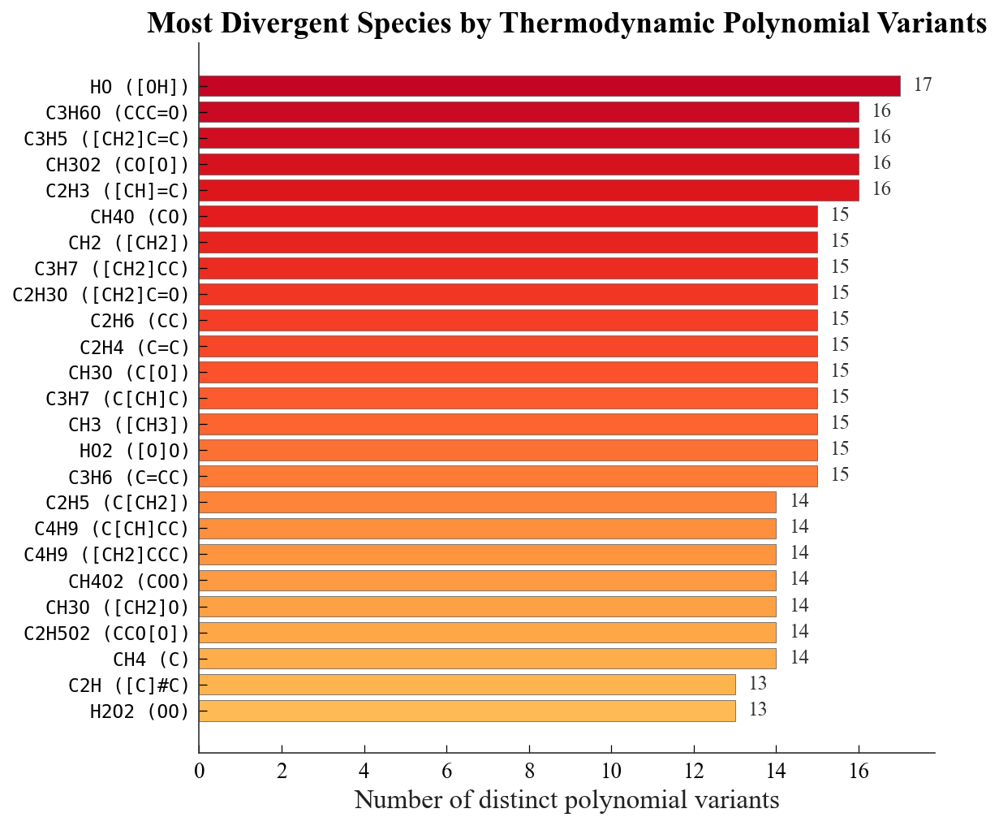

In [86]:
# --- Figure 6B: Most divergent species (top-25 by variant count) ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

vc = pd.Series(variant_counts)
top_sp = vc.sort_values(ascending=False).head(25)
# Create display labels: formula (SMILES)
top_labels = [species_label(sid) for sid in top_sp.index]
colors_b = plt.cm.YlOrRd(np.linspace(0.35, 0.85, len(top_sp)))
y_pos = np.arange(len(top_sp))

fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(y_pos, top_sp.values, color=colors_b[::-1], edgecolor='#666666', linewidth=0.4)
ax.set_yticks(y_pos)
ax.set_yticklabels(top_labels, fontsize=11, fontfamily='monospace')
ax.invert_yaxis()
ax.set_xlabel('Number of distinct polynomial variants')
ax.set_title('Most Divergent Species by Thermodynamic Polynomial Variants')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for i, v in enumerate(top_sp.values):
    ax.text(v + 0.3, i, str(int(v)), va='center', fontsize=12, color='#333')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig6b_divergent_species.pdf'))
plt.savefig(os.path.join(FIG_DIR, 'fig6b_divergent_species.png'))
plt.show()

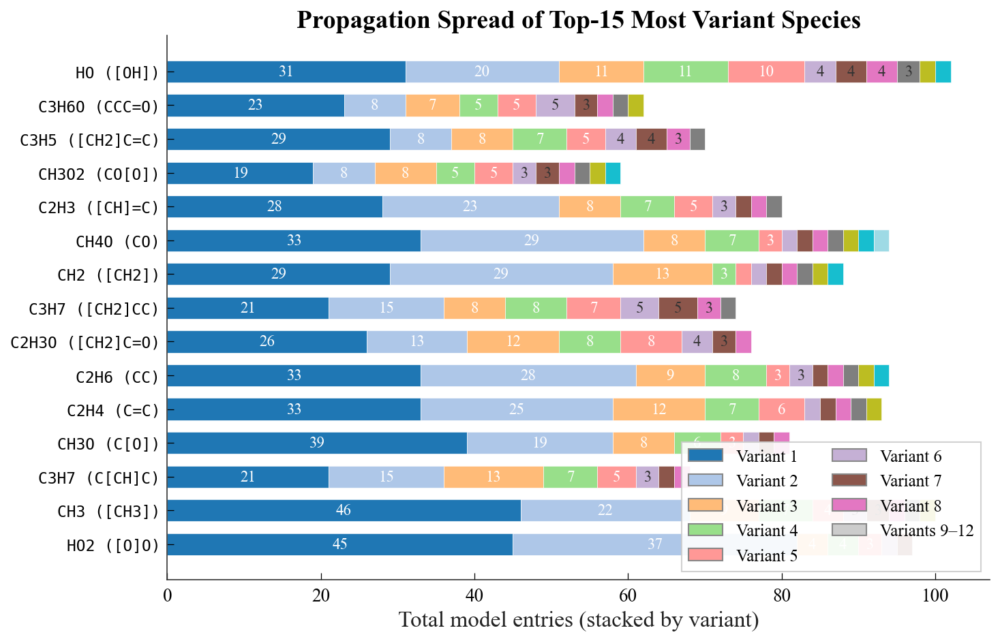

In [87]:
# --- Figure 6C: Propagation spread for top-15 species ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

vc = pd.Series(variant_counts)
top15_sids = vc.sort_values(ascending=False).head(15).index.tolist()

spread_data = []
for sid in top15_sids:
    lbl = species_label(sid)
    if sid in species_chains:
        chains_f = species_chains[sid]
        variant_sizes = sorted([len(models) for models in chains_f.values()], reverse=True)
        spread_data.append((lbl, variant_sizes))
    else:
        spread_data.append((lbl, []))

max_variants = max(len(s[1]) for s in spread_data) if spread_data else 1
cmap_stack = plt.cm.tab20(np.linspace(0, 1, max_variants))

fig, ax = plt.subplots(figsize=(10, 6.5))

y_positions = np.arange(len(spread_data))
for i, (lbl, sizes) in enumerate(spread_data):
    left = 0
    for j, sz in enumerate(sizes):
        color = cmap_stack[j % len(cmap_stack)]
        ax.barh(i, sz, left=left, height=0.65, color=color,
                edgecolor='white', linewidth=0.3)
        if sz >= 3:
            ax.text(left + sz / 2, i, str(sz), ha='center', va='center',
                    fontsize=11, color='white' if j < 5 else '#333')
        left += sz

ax.set_yticks(y_positions)
ax.set_yticklabels([s[0] for s in spread_data], fontsize=11, fontfamily='monospace')
ax.invert_yaxis()
ax.set_xlabel('Total model entries (stacked by variant)')
ax.set_title('Propagation Spread of Top-15 Most Variant Species')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

legend_patches = [Patch(facecolor=cmap_stack[k], edgecolor='#888', label=f'Variant {k+1}')
                  for k in range(min(8, max_variants))]
if max_variants > 8:
    legend_patches.append(Patch(facecolor='#CCCCCC', edgecolor='#888', label=f'Variants 9\u2013{max_variants}'))
ax.legend(handles=legend_patches, fontsize=12, loc='lower right', frameon=True, ncol=2)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig6c_propagation_spread.pdf'))
plt.savefig(os.path.join(FIG_DIR, 'fig6c_propagation_spread.png'))
plt.show()

In [88]:
# --- Propagation chain summary statistics ---
import pandas as pd

vc = pd.Series(variant_counts)
n_with_chains = len(species_chains)
n_total = len(unique_species)

print(f"{'='*80}")
print(f"PROPAGATION CHAIN SUMMARY")
print(f"{'='*80}")
print(f"  Total species in database       : {n_total}")
print(f"  Species with propagation chains  : {n_with_chains} ({100*n_with_chains/n_total:.1f}%)")
print(f"  Species with \u22655 variants         : {(vc >= 5).sum()}")
print(f"  Species with \u226510 variants        : {(vc >= 10).sum()}")
top_sid = vc.idxmax()
print(f"  Most divergent species           : {species_label(top_sid)} ({int(vc.max())} variants)")

# Top-5 largest single propagation chains
largest_chains = []
for sid, chains_f in species_chains.items():
    for key, models in chains_f.items():
        largest_chains.append((sid, len(models), len(set(models))))
largest_chains.sort(key=lambda x: -x[2])

print(f"\n  Largest single-variant propagation (most models sharing one polynomial):")
for sid, n_total_m, n_unique_m in largest_chains[:5]:
    print(f"    {species_label(sid):30s}: {n_unique_m} unique models (of {n_total_m} total entries)")

PROPAGATION CHAIN SUMMARY
  Total species in database       : 4754
  Species with propagation chains  : 3428 (72.1%)
  Species with ≥5 variants         : 318
  Species with ≥10 variants        : 77
  Most divergent species           : HO ([OH]) (17 variants)

  Largest single-variant propagation (most models sharing one polynomial):
    Ar ([Ar])                     : 51 unique models (of 57 total entries)
    C2H4O (CC=O)                  : 47 unique models (of 52 total entries)
    C2H2 ([C]=C)                  : 47 unique models (of 48 total entries)
    CH3 ([CH3])                   : 45 unique models (of 46 total entries)
    C3H4O (CC=C=O)                : 42 unique models (of 42 total entries)


In [89]:
# Identify likely propagation chains: Ref → early_mech → later_mech
# Use Source.publication_year from the database, fall back to name-parsing
import re

def extract_year_from_name(name):
    """Fallback: extract year from model name like 'CombFlame2013/...' or 'PCI2019/...'."""
    m = re.search(r'(20\d{2}|19\d{2})', name)
    if m:
        y = int(m.group(1))
        if 1950 <= y <= 2026:   # plausible publication year range
            return y
    return None

def _valid_year(y):
    """Sanity-check: reject years outside plausible publication range."""
    return y is not None and 1950 <= y <= 2026

# --- Primary: query publication_year from Source via KineticModel.source ---
from database.models.source import Source

source_years = {}
n_from_source = 0
n_from_name = 0
n_missing = 0

for km in KineticModel.objects.select_related('source').all():
    year = None
    # (1) Try Source.publication_year
    if km.source and km.source.publication_year:
        try:
            y = int(km.source.publication_year)
            if _valid_year(y):
                year = y
        except (ValueError, TypeError):
            pass
    # (2) Fallback: parse from model_name
    if year is None:
        year = extract_year_from_name(km.model_name)
        if year is not None:
            n_from_name += 1
        else:
            n_missing += 1
    else:
        n_from_source += 1
    source_years[km.model_name] = year

model_years = source_years
dated_models = {m: y for m, y in model_years.items() if y is not None}

print(f"Year resolution summary:")
print(f"  From Source.publication_year : {n_from_source}")
print(f"  From model_name (fallback)  : {n_from_name}")
print(f"  Still unknown               : {n_missing}")
print(f"  Total with year             : {len(dated_models)} / {len(model_years)}")
if dated_models:
    print(f"  Year range                  : {min(dated_models.values())} \u2013 {max(dated_models.values())}")

# For each species with a shared coeff_key, order models by year
# species_chains is now keyed by species_id
chain_examples = []
for sid, chains in species_chains.items():
    for key, models in chains.items():
        unique_models = list(set(models))
        years = [(m, dated_models.get(m)) for m in unique_models if m in dated_models]
        years.sort(key=lambda x: x[1])
        if len(years) >= 3:
            chain_examples.append((sid, years))

chain_examples.sort(key=lambda x: -len(x[1]))
print(f"\nPropagation chains with \u22653 dated models: {len(chain_examples)}")
print("\nLongest chains (species with most temporally-ordered sharing):")
for sid, chain in chain_examples[:8]:
    lbl = species_label(sid)
    years_str = " \u2192 ".join(f"{m[:20]}({y})" for m, y in chain[:5])
    if len(chain) > 5:
        years_str += f" \u2192 ...({len(chain)} total)"
    print(f"  {lbl:30s}: {years_str}")

Year resolution summary:
  From Source.publication_year : 30
  From model_name (fallback)  : 52
  Still unknown               : 18
  Total with year             : 82 / 100
  Year range                  : 2003 – 2025

Propagation chains with ≥3 dated models: 2385

Longest chains (species with most temporally-ordered sharing):
  Ar ([Ar])                     : MB-Fisher(2007) → Gasoline_Surrogate(2010) → Narayanaswamy(2010) → H2(2011) → PCI2013/269-Matsugi(2012) → ...(44 total)
  C2H2 ([C]=C)                  : Narayanaswamy(2010) → CombFlame2012/2028-S(2012) → CombFlame2013/17-Mal(2012) → PCI2013/527-Sheen(2012) → CombFlame2013/1609-V(2013) → ...(43 total)
  CH3 ([CH3])                   : Narayanaswamy(2010) → PCI2013/401-Liu(2012) → CombFlame2012/2028-S(2012) → PCI2013/259-Labbe(2013) → PCI2013/225-Somers(2013) → ...(41 total)
  C2H4O (CC=O)                  : PCI2013/401-Liu(2012) → CombFlame2012/2028-S(2012) → PCI2013/527-Sheen(2012) → CombFlame2013/1609-V(2013) → PCI2013/259-Labbe(

### 2.3 Propagation Network Construction
Build directed graph G = (M ∪ R, E) where nodes = mechanisms + reference compilations, and edges represent species-level data flow based on exact coefficient matching and ΔfH° provenance.

In [90]:
import networkx as nx
from collections import defaultdict

G = nx.DiGraph()

# Add reference nodes
for ref_name in ['ATcT', 'Burcat', 'GA']:
    G.add_node(ref_name, node_type='reference')

# Add mechanism nodes
for model_name in df_mechanism['model_name'].unique():
    G.add_node(model_name, node_type='mechanism')

# --- Reference → Mechanism edges (from ΔfH° provenance, Step 3) ---
ref_edges = df_mechanism[df_mechanism['provenance'].isin(['ATcT', 'Burcat', 'GA'])]
ref_edge_counts = ref_edges.groupby(['provenance', 'model_name']).size()

for (ref, model), weight in ref_edge_counts.items():
    G.add_edge(ref, model, weight=weight, edge_type='ref_to_mech')

# --- Strengthen Burcat edges with exact coeff match evidence ---
burcat_exact = df_mechanism[df_mechanism['burcat_coeff_match']]
burcat_exact_counts = burcat_exact.groupby('model_name').size()
for model, count in burcat_exact_counts.items():
    if G.has_edge('Burcat', model):
        G['Burcat'][model]['exact_coeff_matches'] = count
    else:
        G.add_edge('Burcat', model, weight=count, edge_type='ref_to_mech',
                   exact_coeff_matches=count)

print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"  Reference nodes: {sum(1 for _,d in G.nodes(data=True) if d.get('node_type')=='reference')}")
print(f"  Mechanism nodes: {sum(1 for _,d in G.nodes(data=True) if d.get('node_type')=='mechanism')}")
print(f"  Ref→Mech edges:  {sum(1 for _,_,d in G.edges(data=True) if d.get('edge_type')=='ref_to_mech')}")

Graph: 102 nodes, 292 edges
  Reference nodes: 3
  Mechanism nodes: 99
  Ref→Mech edges:  292


In [91]:
# Add Mechanism → Mechanism edges based on exact coefficient sharing
# Use dated_models from Step 4c to assign direction: earlier → later
from itertools import combinations

mech_sharing = defaultdict(int)  # (model_a, model_b) -> n_shared_species
for coeff_key, grp in shared_groups:
    models = sorted(grp['model_name'].unique())
    for m1, m2 in combinations(models, 2):
        mech_sharing[(m1, m2)] += 1

# Add edges with direction based on publication year
n_directed = 0
n_undirected = 0
for (m1, m2), weight in mech_sharing.items():
    if weight < 3:  # Only significant sharing (≥3 species)
        continue
    y1 = dated_models.get(m1)
    y2 = dated_models.get(m2)
    if y1 is not None and y2 is not None and y1 != y2:
        # Directed: earlier model → later model (likely source → recipient)
        src, dst = (m1, m2) if y1 < y2 else (m2, m1)
        G.add_edge(src, dst, weight=weight, edge_type='mech_to_mech', directed=True)
        n_directed += 1
    else:
        # Undirected (both dates unknown, or same year): add ONE edge only
        G.add_edge(m1, m2, weight=weight, edge_type='mech_to_mech', directed=False)
        n_undirected += 1

n_m2m = sum(1 for _,_,d in G.edges(data=True) if d.get('edge_type')=='mech_to_mech')
print(f"Mech→Mech edges (≥3 shared species): {n_m2m}")
print(f"  Directed (year-resolved):  {n_directed}")
print(f"  Undirected (no year info): {n_undirected} (single edge each)")
print(f"Updated graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

# Top mechanism pairs by shared species
top_pairs = sorted(mech_sharing.items(), key=lambda x: -x[1])[:10]
print("\nTop 10 mechanism pairs by shared species:")
for (m1, m2), n in top_pairs:
    y1 = dated_models.get(m1)
    y2 = dated_models.get(m2)
    if y1 and y2 and y1 != y2:
        if y1 < y2:
            print(f"  {m1[:30]}({y1}) → {m2[:30]}({y2})  {n} species")
        else:
            print(f"  {m2[:30]}({y2}) → {m1[:30]}({y1})  {n} species")
    else:
        print(f"  {m1[:35]:35s} ↔ {m2[:35]:35s}  {n} species")

Mech→Mech edges (≥3 shared species): 3025
  Directed (year-resolved):  1816
  Undirected (no year info): 1209 (single edge each)
Updated graph: 102 nodes, 3317 edges

Top 10 mechanism pairs by shared species:
  CombFlame2013/17-Malewicki(2012) → PCI2013/361-Malewicki(2013)  1143 species
  Gasoline_2                          ↔ PCI2017/036-Rashidi                  1036 species
  Gasoline_2                          ↔ Gasoline_Surrogate                   909 species
  EL24115                             ↔ Gasoline_Surrogate                   733 species
  Gasoline_Surrogate(2010) → PCI2017/036-Rashidi(2017)  643 species
  CombFlame2017/111-Atef              ↔ Gasoline_2                           620 species
  Gasoline_Surrogate(2010) → CombFlame2017/111-Atef(2017)  596 species
  EL24115                             ↔ Gasoline_2                           592 species
  CombFlame2014/65-Darcy              ↔ Gasoline_2                           538 species
  CombFlame2017/111-Atef              

In [92]:
# Summary statistics of the propagation network
print("=== PROPAGATION NETWORK SUMMARY ===")
print(f"Nodes: {G.number_of_nodes()} ({3} references + {G.number_of_nodes()-3} mechanisms)")
print(f"Edges: {G.number_of_edges()}")
print()

# Reference influence (out-degree from each reference)
for ref in ['ATcT', 'Burcat', 'GA']:
    out_edges = [(u,v,d) for u,v,d in G.edges(data=True) if u==ref]
    total_species = sum(d['weight'] for _,_,d in out_edges)
    n_mechs = len(out_edges)
    print(f"  {ref:6s} → {n_mechs:3d} mechanisms, {total_species:5d} species-level links")

print()
# Most connected mechanisms (highest degree)
mech_degree = {n: G.degree(n) for n, d in G.nodes(data=True) if d.get('node_type')=='mechanism'}
top_connected = sorted(mech_degree.items(), key=lambda x: -x[1])[:10]
print("Most connected mechanisms (degree = # neighbors):")
for model, deg in top_connected:
    print(f"  {model:45s}  degree={deg}")

=== PROPAGATION NETWORK SUMMARY ===
Nodes: 102 (3 references + 99 mechanisms)
Edges: 3317

  ATcT   →  98 mechanisms,   485 species-level links
  Burcat →  96 mechanisms,  1547 species-level links
  GA     →  98 mechanisms, 11808 species-level links

Most connected mechanisms (degree = # neighbors):
  CombFlame2019/1-Hanfeng                        degree=86
  CombFlame2014/1135-Dames                       degree=85
  CombFlame2013/2680-Vranckx                     degree=84
  PCI2013/411-Darcy                              degree=83
  MB-Farooq                                      degree=83
  PCI2015/0325-Nawdiyal                          degree=83
  PCI2017/111-Jin                                degree=83
  CombFlame2013/1939-Cai                         degree=83
  CombFlame2013/487-Schenk                       degree=83
  Gasoline_2                                     degree=82


### Data Genealogy & Network Structure

**Figure 3 — Global data-flow network.**  
Nodes are reference databases (ATcT, Burcat, GA) and mechanism models. Directed edges encode thermochemical data lineage:
- *Reference → Mechanism*: provenance assignment from Step 3  
- *Mechanism → Mechanism*: exact NASA-polynomial sharing from Step 4c, directed by publication year  

Node size ∝ number of species; edge width ∝ number of shared species. A timeline overlay shows publication year on the x-axis to reveal the temporal flow of data copying.

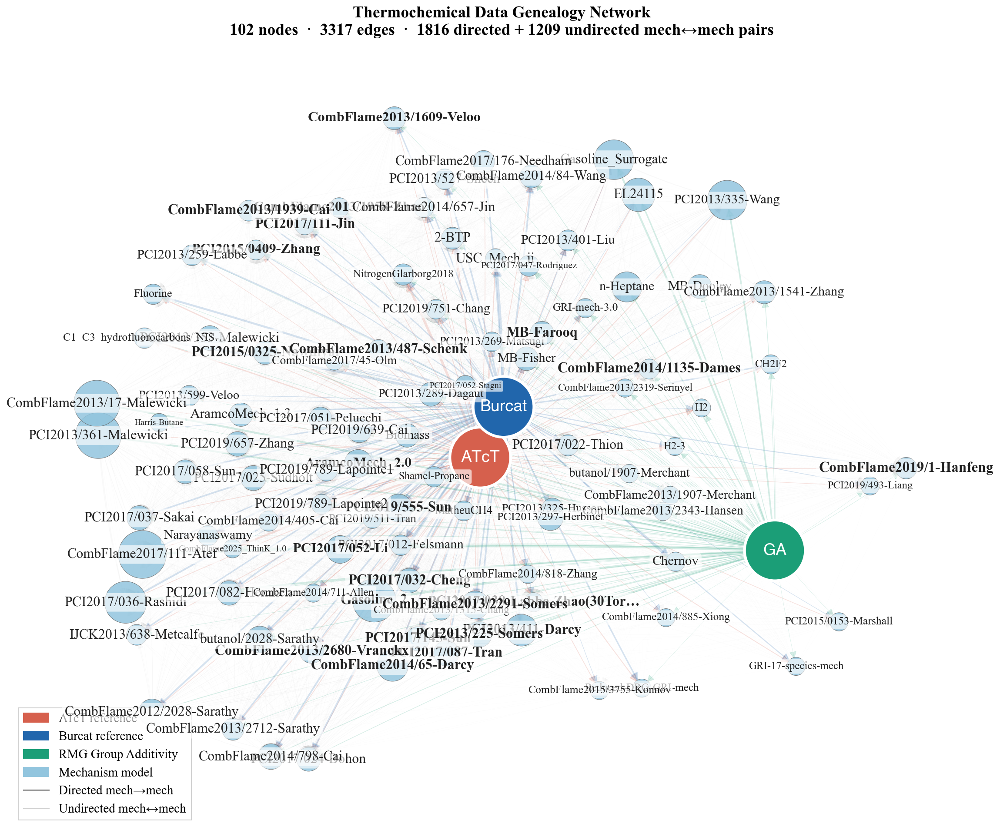

In [93]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from matplotlib.lines import Line2D

# ── colour palette ──────────────────────────────────────────────────
REF_CLR  = PUB_REF
MECH_CLR = PUB_MECH
EDGE_CLR_REF  = PUB_REF
EDGE_CLR_MECH = '#BFBFBF'

# ── node classification ────────────────────────────────────────────
ref_nodes  = [n for n, d in G.nodes(data=True) if d.get('node_type') == 'reference']
mech_nodes = [n for n, d in G.nodes(data=True) if d.get('node_type') == 'mechanism']

# ── node sizes proportional to species count ───────────────────────
mech_sizes = df_mechanism.groupby('model_name')['species_id'].nunique()
max_sz, min_sz = 2800, 400
norm = lambda s: min_sz + (max_sz - min_sz) * (s - mech_sizes.min()) / max(1, mech_sizes.max() - mech_sizes.min())

# ── layout: Kamada-Kawai for nice separation ───────────────────────
pos = nx.kamada_kawai_layout(G, weight='weight')

# ── figure ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(16, 13))
ax.set_facecolor('white')
fig.patch.set_facecolor('white')

# — Draw mech→mech edges first (background) ─────────────────────────
m2m_edges = [(u, v, d) for u, v, d in G.edges(data=True) if d.get('edge_type') == 'mech_to_mech']
# Deduplicate: keep only one edge per node pair to avoid back-and-forth lines
_seen = set()
m2m_edges = [(u,v,d) for u,v,d in m2m_edges if not (frozenset((u,v)) in _seen or _seen.add(frozenset((u,v))))]
m2m_weights = [d['weight'] for _, _, d in m2m_edges]
max_m2m_w = max(m2m_weights) if m2m_weights else 1
m2m_widths  = [0.1 + 2.0 * w / max_m2m_w for w in m2m_weights]
m2m_alphas  = [0.05 + 0.2 * w / max_m2m_w for w in m2m_weights]
m2m_edge_list = [(u, v) for u, v, _ in m2m_edges]

undir_idx = [i for i, (_, _, d) in enumerate(m2m_edges) if not d.get('directed', False)]
dir_idx   = [i for i, (_, _, d) in enumerate(m2m_edges) if d.get('directed', False)]

for idx_set, arrow_style, color in [
    (undir_idx, '-',  '#D0D0D0'),
    (dir_idx,   '->',  '#999999'),
]:
    if not idx_set:
        continue
    el = [m2m_edge_list[i] for i in idx_set]
    ew = [m2m_widths[i]   for i in idx_set]
    ea = [m2m_alphas[i]   for i in idx_set]
    nx.draw_networkx_edges(G, pos, edgelist=el, width=ew,
                           edge_color=color, alpha=np.mean(ea),
                           arrows=(arrow_style == '->'),
                           arrowstyle='-|>' if arrow_style == '->' else '-',
                           arrowsize=15, ax=ax, connectionstyle='arc3,rad=0.05')

# — Draw ref→mech edges (coloured, on top) ──────────────────────────
for ref in ref_nodes:
    r2m = [(u, v, d) for u, v, d in G.edges(data=True)
           if u == ref and d.get('edge_type') == 'ref_to_mech']
    if not r2m:
        continue
    r2m_w = [d['weight'] for _, _, d in r2m]
    max_rw = max(r2m_w)
    widths  = [0.3 + 2.5 * w / max_rw for w in r2m_w]
    nx.draw_networkx_edges(G, pos,
                           edgelist=[(u, v) for u, v, _ in r2m],
                           width=widths,
                           edge_color=EDGE_CLR_REF[ref],
                           alpha=0.18,
                           arrows=True, arrowstyle='-|>', arrowsize=18,
                           ax=ax, connectionstyle='arc3,rad=0.02')

# — Draw nodes ──────────────────────────────────────────────────────
mech_node_sizes = [norm(mech_sizes.get(n, 1)) for n in mech_nodes]
nx.draw_networkx_nodes(G, pos, nodelist=mech_nodes,
                       node_size=mech_node_sizes,
                       node_color=MECH_CLR, edgecolors='#666', linewidths=0.5,
                       alpha=0.85, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=ref_nodes,
                       node_size=[4500]*3,
                       node_color=[REF_CLR[r] for r in ref_nodes],
                       edgecolors='white', linewidths=3.0, alpha=1.0, ax=ax)

# — Labels: ALL nodes labelled ──────────────────────────────────────
# Reference labels (inside node, white)
nx.draw_networkx_labels(G, pos, labels={n: n for n in ref_nodes},
                        font_size=18, font_weight='bold', font_color='white', ax=ax)

# Mechanism labels — scale font size by degree so important nodes stand out
degrees = {n: G.degree(n) for n in mech_nodes}
max_deg = max(degrees.values()) if degrees else 1
min_deg = min(degrees.values()) if degrees else 0

for n in mech_nodes:
    x, y = pos[n]
    # shorten long names
    lbl = n[:28] + '…' if len(n) > 28 else n
    # font size: 4.5 for lowest-degree → 8 for highest
    fs = 9.5 + 6.5 * (degrees[n] - min_deg) / max(1, max_deg - min_deg)
    # bold for top-20
    fw = 'bold' if degrees[n] >= sorted(degrees.values(), reverse=True)[19] else 'normal'
    ax.text(x, y, lbl, fontsize=fs, fontweight=fw, color='#222',
            ha='center', va='center',
            bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.65),
            zorder=10)

# — Legend & title ──────────────────────────────────────────────────
legend_handles = [
    mpatches.Patch(color=REF_CLR['ATcT'],  label='ATcT reference'),
    mpatches.Patch(color=REF_CLR['Burcat'], label='Burcat reference'),
    mpatches.Patch(color=REF_CLR['GA'],     label='RMG Group Additivity'),
    mpatches.Patch(color=MECH_CLR,          label='Mechanism model'),
    Line2D([0], [0], color='#999', lw=1.5, label='Directed mech→mech'),
    Line2D([0], [0], color='#D0D0D0', lw=1.5, label='Undirected mech↔mech'),
]
ax.legend(handles=legend_handles, loc='lower left', framealpha=0.92,
          edgecolor='#CCC', fontsize=14)

ax.set_title('Thermochemical Data Genealogy Network\n'
             f'{G.number_of_nodes()} nodes  ·  {G.number_of_edges()} edges  ·  '
             f'{n_directed} directed + {n_undirected} undirected mech↔mech pairs',
             pad=18)
ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig3_genealogy_network.pdf'))
plt.savefig(os.path.join(FIG_DIR, 'fig3_genealogy_network.png'))
plt.show()

#### Subnetwork views

The full 102-node graph is dense. Below we extract **focused subnetworks** for the 5 major mechanisms (`major_5`) and the top-20 most connected mechanisms to reveal the fine structure of data copying and provenance lineage more clearly.

In [94]:
# -- Figure 5: Ancestry tracing for ALL mechanisms ----------------------------
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from collections import defaultdict

# 1) Build ancestry table for EVERY mechanism
ancestry_records = []

for mech in mech_nodes:
    anc_list = []   # (name, shared_species)
    desc_list = []  # (name, shared_species)
    peer_list = []  # (name, shared_species)

    for u, v, d in G.edges(data=True):
        if d.get('edge_type') != 'mech_to_mech':
            continue
        w = d.get('weight', 0)
        if v == mech and d.get('directed', False):
            anc_list.append((u, w))
        elif u == mech and d.get('directed', False):
            desc_list.append((v, w))
        elif u == mech and not d.get('directed', False):
            peer_list.append((v, w))
        elif v == mech and not d.get('directed', False):
            peer_list.append((u, w))

    # Deduplicate peers
    peer_dict = {}
    for name, w in peer_list:
        if name not in peer_dict or w > peer_dict[name]:
            peer_dict[name] = w
    peer_list = list(peer_dict.items())

    anc_sorted = sorted(anc_list, key=lambda x: -x[1])
    total_anc_shared = sum(w for _, w in anc_list)
    top_anc = anc_sorted[0] if anc_sorted else (None, 0)

    ancestry_records.append({
        'mechanism': mech,
        'year': dated_models.get(mech),
        'species_count': mech_sizes.get(mech, 0),
        'n_ancestors': len(anc_list),
        'n_descendants': len(desc_list),
        'n_peers': len(peer_list),
        'total_ancestor_shared': total_anc_shared,
        'top_ancestor': top_anc[0],
        'top_ancestor_shared': top_anc[1],
        '_ancestors': anc_sorted,
        '_descendants': sorted(desc_list, key=lambda x: -x[1]),
        '_peers': sorted(peer_list, key=lambda x: -x[1]),
    })

ancestry_df = pd.DataFrame(ancestry_records).sort_values('n_ancestors', ascending=False).reset_index(drop=True)

# Store for use in later cells
ancestry_lookup = {r['mechanism']: r for r in ancestry_records}


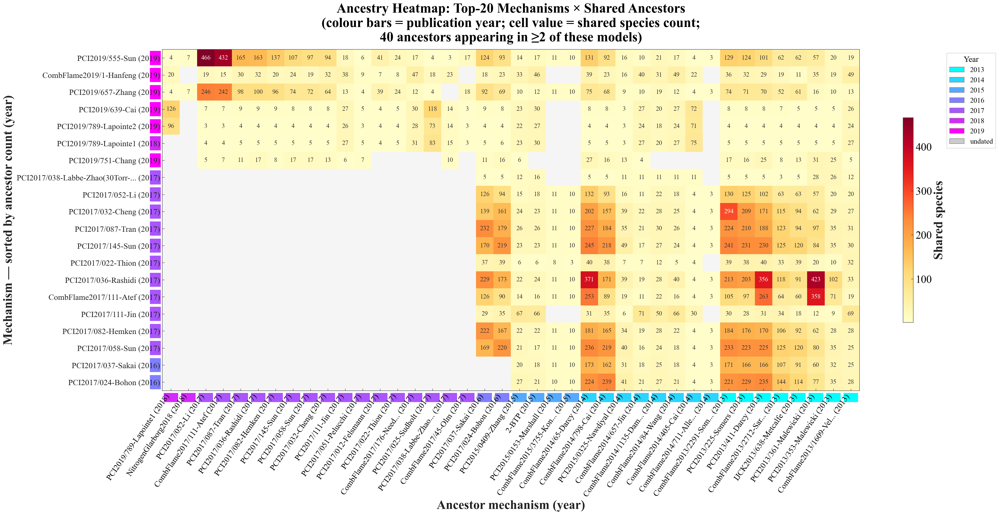

In [95]:
# -- Figure 5B: Per-mechanism ancestry detail (full lineage for every model) ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

# 1) Build a long-form table: one row per (mechanism, ancestor) pair
lineage_rows = []
for rec in ancestry_records:
    mech = rec['mechanism']
    yr = rec['year']
    for anc_name, shared in rec['_ancestors']:
        lineage_rows.append({
            'mechanism': mech,
            'mech_year': yr,
            'ancestor': anc_name,
            'ancestor_year': dated_models.get(anc_name),
            'shared_species': shared,
        })

lineage_df = pd.DataFrame(lineage_rows)


# 3) Figure 5B: Heatmap - top-20 mechanisms (by ancestor count) vs their ancestors
#    Now includes year on both axes + year-based colour coding
top_n = 20
top_mechs = ancestry_df.head(top_n)['mechanism'].tolist()

# Build ancestor set
all_ancestors_in_top = set()
for m in top_mechs:
    for a_name, _ in ancestry_lookup[m]['_ancestors']:
        all_ancestors_in_top.add(a_name)

# Count how often each ancestor appears among the top-20 mechanisms
anc_freq = {}
for m in top_mechs:
    for a_name, _ in ancestry_lookup[m]['_ancestors']:
        anc_freq[a_name] = anc_freq.get(a_name, 0) + 1

# Keep ancestors appearing >= 2 times among the top-20 mechanisms
frequent_anc = [a for a, cnt in anc_freq.items() if cnt >= 2]
# Sort by year descending (most recent first); undated go to the end
frequent_anc = sorted(frequent_anc,
                       key=lambda x: (-dated_models.get(x, 0), -anc_freq[x]))
frequent_anc = frequent_anc[:40]  # cap at 40 columns

if frequent_anc:
    matrix = np.zeros((len(top_mechs), len(frequent_anc)))
    for i, m in enumerate(top_mechs):
        anc_dict = {a: w for a, w in ancestry_lookup[m]['_ancestors']}
        for j, a in enumerate(frequent_anc):
            matrix[i, j] = anc_dict.get(a, 0)

    # --- Build year-annotated labels ---
    def _yr_label(name, max_chars=30):
        yr = dated_models.get(name)
        yr_str = str(int(yr)) if yr else '?'
        short = name[:max_chars] + ('...' if len(name) > max_chars else '')
        return f"{short} ({yr_str})"

    y_labels = [_yr_label(m, 30) for m in top_mechs]
    x_labels = [_yr_label(a, 22) for a in frequent_anc]

    # --- Year colour band for y-axis (mechanism year) ---
    mech_years_raw = [dated_models.get(m) for m in top_mechs]
    anc_years_raw  = [dated_models.get(a) for a in frequent_anc]
    all_yrs = [int(y) for y in mech_years_raw + anc_years_raw if y is not None]
    yr_min = min(all_yrs) if all_yrs else 2000
    yr_max = max(all_yrs) if all_yrs else 2025
    yr_range = max(yr_max - yr_min, 1)

    year_cmap = plt.cm.cool  # blue-to-magenta for year coding

    def _yr_color(yr_val):
        if yr_val is None:
            return '#CCCCCC'
        return year_cmap((int(yr_val) - yr_min) / yr_range)

    mech_yr_colors = [_yr_color(y) for y in mech_years_raw]
    anc_yr_colors  = [_yr_color(y) for y in anc_years_raw]

    # --- Plot ---
    fig, ax_main = plt.subplots(figsize=(max(32, len(frequent_anc) * 0.75),
                                         max(16, len(top_mechs) * 0.6)))
    fig.patch.set_facecolor('white')
    ax_main.set_facecolor('white')

    cmap = plt.cm.YlOrRd.copy()
    cmap.set_under('#F5F5F5')

    im = ax_main.imshow(matrix, aspect='auto', cmap=cmap, vmin=1, interpolation='nearest')
    cb = plt.colorbar(im, ax=ax_main, shrink=0.6, label='Shared species')
    cb.ax.tick_params(labelsize=24)
    cb.set_label('Shared species', fontsize=28, weight='bold')

    # Y-axis: mechanism labels with year colour markers
    ax_main.set_yticks(range(len(top_mechs)))
    ax_main.set_yticklabels(y_labels, fontsize=18)
    for i, col in enumerate(mech_yr_colors):
        ax_main.get_yticklabels()[i].set_color('#222')
        ax_main.add_patch(plt.Rectangle((-1.2, i - 0.4), 0.6, 0.8,
                                         color=col, clip_on=False, transform=ax_main.transData))

    # X-axis: ancestor labels with year colour markers
    ax_main.set_xticks(range(len(frequent_anc)))
    ax_main.set_xticklabels(x_labels, rotation=55, ha='right', fontsize=18)
    for j, col in enumerate(anc_yr_colors):
        ax_main.add_patch(plt.Rectangle((j - 0.4, len(top_mechs) - 0.5 + 0.15), 0.8, 0.5,
                                         color=col, clip_on=False, transform=ax_main.transData))

    # Annotate non-zero cells
    for i in range(len(top_mechs)):
        for j in range(len(frequent_anc)):
            v = matrix[i, j]
            if v > 0:
                ax_main.text(j, i, str(int(v)), ha='center', va='center', fontsize=14,
                             color='white' if v > matrix.max() * 0.6 else '#333')

    # Year colour legend
    legend_yrs = list(range(yr_min, yr_max + 1, max(1, yr_range // 5)))
    if yr_max not in legend_yrs:
        legend_yrs.append(yr_max)
    legend_handles = [Patch(facecolor=_yr_color(y), edgecolor='#888', label=str(y))
                      for y in legend_yrs]
    legend_handles.append(Patch(facecolor='#CCCCCC', edgecolor='#888', label='undated'))
    ax_main.legend(handles=legend_handles, title='Year', fontsize=16, title_fontsize=18,
                   loc='upper left', bbox_to_anchor=(1.12, 1.0), frameon=True)

    ax_main.set_title(
        f'Ancestry Heatmap: Top-{top_n} Mechanisms × Shared Ancestors\n'
        f'(colour bars = publication year; cell value = shared species count;\n'
        f'{len(frequent_anc)} ancestors appearing in \u22652 of these models)',
        pad=18, fontsize=30, weight='bold'
    )
    ax_main.set_xlabel('Ancestor mechanism (year)', fontsize=28, weight='bold')
    ax_main.set_ylabel('Mechanism \u2014 sorted by ancestor count (year)', fontsize=28, weight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'fig5b_ancestry_heatmap.pdf'))
    plt.savefig(os.path.join(FIG_DIR, 'fig5b_ancestry_heatmap.png'))
    plt.show()
else:
    print("No shared ancestors found among top mechanisms.")


### Species & Model Lineage Trees
Interactive exploration of how specific thermodynamic polynomial variants propagate
through model lineages, and how individual models relate to their ancestors and descendants.
- **Figure 7** — Species Variant Propagation Tree: pick a species and see which models share each variant, overlaid on the ancestry graph.
- **Figure 8** — Model Lineage Tree: pick a model and see its full ancestry (ancestors, descendants, peers).

/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/964434835.py:136: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(G_sp, pos, ax=ax, arrows=True,


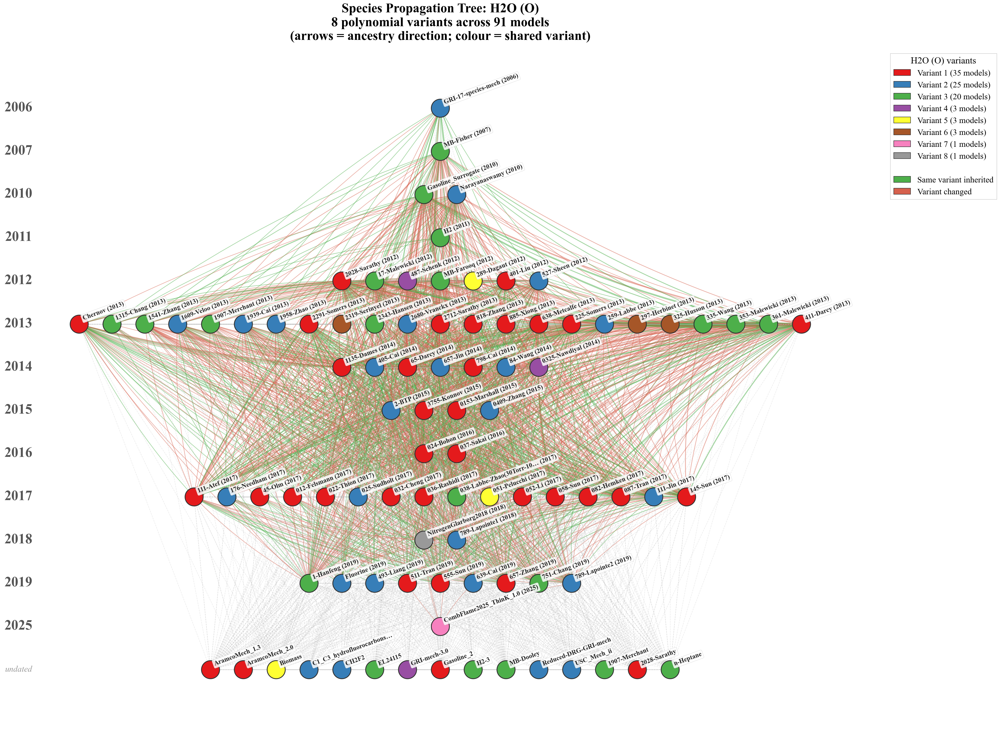


Variant breakdown for H2O (O):
  Variant 1: 35 models
    - AramcoMech_1.3 (?)
    - AramcoMech_2.0 (?)
    - Chernov (2013)
    - CombFlame2012/2028-Sarathy (2012)
    ... and 31 more
  Variant 2: 25 models
    - 2-BTP (2015)
    - C1_C3_hydrofluorocarbons_NIST (?)
    - CH2F2 (?)
    - CombFlame2013/1609-Veloo (2013)
    ... and 21 more
  Variant 3: 20 models
    - CombFlame2013/1315-Chang (2013)
    - CombFlame2013/1541-Zhang (2013)
    - CombFlame2013/17-Malewicki (2012)
    - CombFlame2013/1907-Merchant (2013)
    ... and 16 more
  Variant 4: 3 models
    - CombFlame2013/487-Schenk (2012)
    - GRI-mech-3.0 (?)
    - PCI2015/0325-Nawdiyal (2014)
  Variant 5: 3 models
    - Biomass (?)
    - PCI2013/289-Dagaut (2012)
    - PCI2017/051-Pelucchi (2017)
  Variant 6: 3 models
    - CombFlame2013/2319-Serinyel (2013)
    - PCI2013/297-Herbinet (2013)
    - PCI2013/325-Husson (2013)
  Variant 7: 1 models
    - CombFlame2025_ThinK_1.0 (2025)
  Variant 8: 1 models
    - NitrogenGlarborg20

In [96]:
# ===== Figure 7: Species Variant Propagation Tree ===============================
# Shows how different thermodynamic polynomial variants of a species
# propagate through the model ancestry network.
# Change QUERY_SPECIES below to explore any species.
# Now uses species_id (not formula) — set QUERY_SPECIES to a formula
# and the code will resolve it to the correct species_id.
# ================================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import numpy as np
import pandas as pd

QUERY_SPECIES = 'H2O'  # <-- Change to any species formula or set QUERY_SID directly

# Resolve formula to species_id
_query_matches = df_species[df_species['formula'] == QUERY_SPECIES]
if _query_matches.empty:
    QUERY_SID = None
    print(f"'{QUERY_SPECIES}' not found in database.")
else:
    QUERY_SID = _query_matches.index[0]
    if len(_query_matches) > 1:
        print(f"Multiple species with formula '{QUERY_SPECIES}':")
        for sid in _query_matches.index:
            print(f"  sid={sid}: {species_label(sid)}")
        print(f"Using first: sid={QUERY_SID}")

if QUERY_SID is None or QUERY_SID not in species_chains:
    print(f"Species {QUERY_SPECIES} (sid={QUERY_SID}) has no propagation chains.")
    print(f"Species with chains: {len(species_chains)}")
    _sample_labels = [species_label(sid) for sid in list(species_chains.keys())[:20]]
    print(f"Try: {_sample_labels}")
else:
    chains_sp = species_chains[QUERY_SID]
    n_variants = len(chains_sp)
    query_label = species_label(QUERY_SID)

    # Sort variants by cluster size (most models first)
    sorted_variants = sorted(chains_sp.items(), key=lambda x: -len(set(x[1])))

    variant_map = {}   # model_name -> variant_id
    variant_models = {}  # variant_id -> [models]
    for vid, (coeff_key, models) in enumerate(sorted_variants):
        unique_m = sorted(set(models))
        variant_models[vid] = unique_m
        for m in unique_m:
            variant_map[m] = vid

    involved_models = set(variant_map.keys())

    # --- Build ancestry subgraph (only models containing this species) ---
    G_sp = nx.DiGraph()
    for m in involved_models:
        G_sp.add_node(m)

    for u, v, d in G.edges(data=True):
        if d.get('edge_type') == 'mech_to_mech' and d.get('directed', False):
            if u in involved_models and v in involved_models:
                G_sp.add_edge(u, v, weight=d.get('weight', 1))

    # Collect peer edges
    peer_set = set()
    for u, v, d in G.edges(data=True):
        if d.get('edge_type') == 'mech_to_mech' and not d.get('directed', False):
            if u in involved_models and v in involved_models:
                peer_set.add(tuple(sorted([u, v])))

    # --- Hierarchical layout by year ---
    year_groups_sp = {}
    undated_sp = []
    for m in involved_models:
        yr = dated_models.get(m)
        if yr:
            year_groups_sp.setdefault(int(yr), []).append(m)
        else:
            undated_sp.append(m)

    sorted_years_sp = sorted(year_groups_sp.keys())

    pos = {}
    tier = 0
    max_tier_width = 0
    for yr in sorted_years_sp:
        ms = sorted(year_groups_sp[yr])
        n = len(ms)
        max_tier_width = max(max_tier_width, n)
        for i, m in enumerate(ms):
            pos[m] = ((i - (n - 1) / 2) * 3.5, -tier * 2.5)
        tier += 1

    if undated_sp:
        n = len(undated_sp)
        max_tier_width = max(max_tier_width, n)
        for i, m in enumerate(sorted(undated_sp)):
            pos[m] = ((i - (n - 1) / 2) * 3.5, -tier * 2.5)

    # --- Variant colours ---
    cpal = plt.cm.Set1 if n_variants <= 9 else plt.cm.tab20
    vcols = {vid: cpal(vid / max(n_variants - 1, 1)) for vid in range(n_variants)}
    node_colors = [vcols.get(variant_map.get(m, 0), '#CCC') for m in G_sp.nodes()]

    # --- Short labels ---
    def _short(name, mc=24):
        parts = name.split('/')
        s = parts[-1] if len(parts) > 1 else name
        yr = dated_models.get(name)
        ys = f' ({int(yr)})' if yr else ''
        return (s[:mc] + '\u2026' if len(s) > mc else s) + ys

    labels = {m: _short(m) for m in G_sp.nodes()}

    # --- Figure ---
    n_tiers = len(sorted_years_sp) + (1 if undated_sp else 0)
    fig_w = max(16, max_tier_width * 3.5)
    fig_h = max(10, n_tiers * 2.0 + 4)

    fig, ax = plt.subplots(figsize=(min(fig_w, 30), min(fig_h, 22)))
    fig.patch.set_facecolor('white')
    ax.set_facecolor('white')

    # Draw directed edges (ancestry)
    if G_sp.edges():
        ew = [G_sp[u][v].get('weight', 1) for u, v in G_sp.edges()]
        max_ew = max(ew) if ew else 1
        widths = [1.2 + 5.0 * w / max_ew for w in ew]

        # Edge colour: green = same variant inherited, red = variant changed
        edge_colors = []
        for u, v in G_sp.edges():
            if variant_map.get(u) == variant_map.get(v):
                edge_colors.append(PUB_EDGE['inherited'])
            else:
                edge_colors.append(PUB_EDGE['changed'])

        nx.draw_networkx_edges(G_sp, pos, ax=ax, arrows=True,
                               arrowstyle='->', arrowsize=22,
                               width=widths, edge_color=edge_colors,
                               alpha=0.5, connectionstyle='arc3,rad=0.08')

    # Draw peer edges (dashed)
    if peer_set:
        G_p = nx.Graph()
        for u, v in peer_set:
            if u in pos and v in pos:
                G_p.add_edge(u, v)
        if G_p.edges():
            nx.draw_networkx_edges(G_p, pos, ax=ax, style='dashed',
                                   width=1.0, edge_color='#BBB', alpha=0.3)

    # Draw nodes
    nx.draw_networkx_nodes(G_sp, pos, ax=ax,
                           node_color=node_colors, node_size=1500,
                           edgecolors='#333', linewidths=1.8)
    # Draw labels manually with rotation for readability
    for m in G_sp.nodes():
        x, y = pos[m]
        ax.annotate(labels[m], xy=(x, y), xytext=(6, 6),
                    textcoords='offset points', fontsize=14, fontweight='bold',
                    rotation=20, ha='left', va='bottom', color='#222',
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#CCC',
                              alpha=0.85, lw=0.5))

    # Year tier labels (left margin)
    x_min = min(p[0] for p in pos.values()) - 5.0
    tier = 0
    for yr in sorted_years_sp:
        ax.text(x_min, -tier * 2.5, str(yr), fontsize=30, fontweight='bold',
                ha='right', va='center', color='#555')
        tier += 1
    if undated_sp:
        ax.text(x_min, -tier * 2.5, 'undated', fontsize=18, fontstyle='italic',
                ha='right', va='center', color='#999')

    # Legend
    handles = [mpatches.Patch(facecolor=vcols[vid], edgecolor='#333',
                             label=f'Variant {vid+1} ({len(variant_models[vid])} models)')
               for vid in range(min(n_variants, 12))]
    if n_variants > 12:
        handles.append(mpatches.Patch(facecolor='#CCC', label=f'+ {n_variants-12} more'))
    handles.append(mpatches.Patch(facecolor='white', edgecolor='white', label=''))
    handles.append(mpatches.Patch(facecolor=PUB_EDGE['inherited'], edgecolor='#333',
                                  label='Same variant inherited'))
    handles.append(mpatches.Patch(facecolor=PUB_EDGE['changed'], edgecolor='#333',
                                  label='Variant changed'))

    ax.legend(handles=handles, fontsize=18, loc='upper left',
              bbox_to_anchor=(1.01, 1.0), title=f'{query_label} variants',
              title_fontsize=20)

    ax.set_title(f'Species Propagation Tree: {query_label}\n'
                 f'{n_variants} polynomial variants across {len(involved_models)} models\n'
                 f'(arrows = ancestry direction; colour = shared variant)',
                 fontsize=28, pad=20)
    ax.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'fig7_species_tree_{QUERY_SPECIES}.pdf'))
    plt.savefig(os.path.join(FIG_DIR, f'fig7_species_tree_{QUERY_SPECIES}.png'))
    plt.show()

    # --- Summary ---
    same_v = sum(1 for u, v in G_sp.edges() if variant_map.get(u) == variant_map.get(v))
    diff_v = sum(1 for u, v in G_sp.edges() if variant_map.get(u) != variant_map.get(v))
    print(f'\nVariant breakdown for {query_label}:')
    for vid in range(min(n_variants, 10)):
        ms = variant_models[vid]
        print(f'  Variant {vid+1}: {len(ms)} models')
        for m in ms[:4]:
            yr = dated_models.get(m, '?')
            print(f'    - {m} ({yr})')
        if len(ms) > 4:
            print(f'    ... and {len(ms)-4} more')
    if n_variants > 10:
        print(f'  ... and {n_variants - 10} more variants')
    tot_e = max(len(G_sp.edges()), 1)
    print(f'\n  Ancestry edges: {len(G_sp.edges())}')
    print(f'    Same variant inherited: {same_v} ({100*same_v/tot_e:.0f}%)')
    print(f'    Variant changed:       {diff_v} ({100*diff_v/tot_e:.0f}%)')

Also build a species-level propagation network:
- For each species s, trace which reference it was copied from in each mechanism
- Identify "propagation chains": Ref_A → Mechanism_1 → Mechanism_2 → ... (where later mechanisms copied from earlier mechanisms rather than from the original reference)



In [97]:
# ============================================================================
# Species-Level Propagation Network
# ============================================================================
# For each species, reconstruct how its thermochemical data propagated
# across mechanisms: Reference → earliest mechanism → later mechanisms.
# Uses coeff_key (exact 14-coefficient match) + dated_models (publication year)
# to build temporal propagation chains.
#
# G_sp: directed graph where edges carry per-species provenance flow.
# propagation_chains: sid → [{coeff_key, chain, ref_origin, models, years}]
# ============================================================================

import networkx as nx
from collections import defaultdict

G_sp = nx.DiGraph()

# Nodes: references + mechanisms
for ref_name in ['ATcT', 'Burcat', 'GA']:
    G_sp.add_node(ref_name, node_type='reference')
for model in df_mechanism['model_name'].unique():
    G_sp.add_node(model, node_type='mechanism')

# ── Build propagation chains per species ────────────────────────────────
propagation_chains = {}   # sid → list of chain dicts
chain_counts = {'total': 0, 'with_ref': 0}

for sid, variants in species_chains.items():
    sid_chains = []

    for ck, models in variants.items():
        # Provenance of each model for this (species, coeff_key)
        mask = (df_mechanism['species_id'] == sid) & (df_mechanism['coeff_key'] == ck)
        entries = df_mechanism.loc[mask, ['model_name', 'provenance']].drop_duplicates('model_name')
        prov_map = dict(zip(entries['model_name'], entries['provenance']))

        # Sort models by publication year (undated → end)
        model_yr = [(m, dated_models.get(m, 9999)) for m in models]
        model_yr.sort(key=lambda x: x[1])
        sorted_models = [m for m, _ in model_yr]
        sorted_years  = [yr for _, yr in model_yr]

        # Identify reference origin: provenance of the earliest model
        ref_origin = None
        for m in sorted_models:
            p = prov_map.get(m, 'Untraced')
            if p in ('ATcT', 'Burcat', 'GA'):
                ref_origin = p
                break

        # ── Build chain ─────────────────────────────────────────────
        chain = []
        if ref_origin:
            chain.append(ref_origin)
            chain_counts['with_ref'] += 1
            # Edge: Reference → earliest model with that provenance
            first_ref_model = sorted_models[0]
            for m in sorted_models:
                if prov_map.get(m) == ref_origin:
                    first_ref_model = m
                    break
            if G_sp.has_edge(ref_origin, first_ref_model):
                G_sp[ref_origin][first_ref_model]['species'].append(sid)
                G_sp[ref_origin][first_ref_model]['weight'] += 1
            else:
                G_sp.add_edge(ref_origin, first_ref_model, weight=1,
                              species=[sid], edge_type='ref_to_mech')

        chain.extend(sorted_models)

        # Mechanism → mechanism edges (temporal order)
        for i in range(len(sorted_models) - 1):
            s, d = sorted_models[i], sorted_models[i + 1]
            if G_sp.has_edge(s, d):
                G_sp[s][d]['species'].append(sid)
                G_sp[s][d]['weight'] += 1
            else:
                G_sp.add_edge(s, d, weight=1, species=[sid],
                              edge_type='mech_to_mech')

        sid_chains.append({
            'coeff_key': ck,
            'chain': chain,
            'length': len(chain),
            'models': sorted_models,
            'years': sorted_years,
            'ref_origin': ref_origin,
        })
        chain_counts['total'] += 1

    propagation_chains[sid] = sid_chains

# ── Summary ─────────────────────────────────────────────────────────────
n_ref_edges = sum(1 for *_, d in G_sp.edges(data=True)
                  if d.get('edge_type') == 'ref_to_mech')
n_m2m_edges = sum(1 for *_, d in G_sp.edges(data=True)
                  if d.get('edge_type') == 'mech_to_mech')

print(f"Species-level propagation network (G_sp):")
print(f"  Nodes:  {G_sp.number_of_nodes()}")
print(f"  Edges:  {G_sp.number_of_edges()}  "
      f"(Ref→Mech: {n_ref_edges}, Mech→Mech: {n_m2m_edges})")
print(f"  Chains: {chain_counts['total']}  "
      f"({chain_counts['with_ref']} with reference origin)")
print(f"  Species covered: {len(propagation_chains)}")

Species-level propagation network (G_sp):
  Nodes:  102
  Edges:  913  (Ref→Mech: 93, Mech→Mech: 820)
  Chains: 5304  (2030 with reference origin)
  Species covered: 3428


In [98]:
# ── Species propagation summary table ───────────────────────────────────
import pandas as pd

pd.set_option('display.max_colwidth', 160)

rows = []
for sid, cs in propagation_chains.items():
    formula = df_species.loc[sid, 'formula'] if sid in df_species.index else '?'
    smiles  = df_species.loc[sid, 'smiles']  if sid in df_species.index else ''

    # ── Per-model provenance (from df_mechanism) ──────────────────────
    all_prov = df_mechanism.loc[
        df_mechanism['species_id'] == sid, ['model_name', 'provenance']
    ].drop_duplicates('model_name')
    prov_per_model = dict(zip(all_prov['model_name'], all_prov['provenance']))
    unique_provs   = sorted(set(all_prov['provenance']))

    # Chain-level reference origins
    chain_refs = set(c['ref_origin'] for c in cs if c['ref_origin'])
    ref_str    = ', '.join(sorted(chain_refs)) if chain_refs else 'Untraced'

    max_len    = max(c['length'] for c in cs)
    n_vars     = len(cs)
    all_models = sorted(set(m for c in cs for m in c['models']))
    n_models   = len(all_models)

    # Longest chain text
    longest    = max(cs, key=lambda c: c['length'])
    chain_txt  = ' \u2192 '.join(longest['chain'])

    # Annotated model list:  ModelA(ATc), ModelB(Bur) ...
    models_annotated = ', '.join(
        f"{m}({prov_per_model.get(m, '?')[:3]})" for m in all_models
    )

    # Conflict flag: True if different models assign different provenances
    conflict = len(unique_provs) > 1

    rows.append({
        'species_id':       sid,
        'formula':          formula,
        'smiles':           smiles or '',
        'ref_source':       ref_str,
        'all_provenances':  ', '.join(unique_provs),
        'conflict':         conflict,
        'max_chain_length': max_len,
        'n_variants':       n_vars,
        'n_models':         n_models,
        'models':           models_annotated,
        'longest_chain':    chain_txt,
    })

df_prop = pd.DataFrame(rows).sort_values('max_chain_length', ascending=False)

# ── Multi-ref vs single-ref breakdown ─────────────────────────────────
multi_ref  = df_prop[df_prop['conflict']]
single_ref = df_prop[~df_prop['conflict']]

print('Reference source distribution (chain-level):')
print(df_prop['ref_source'].value_counts().to_string())

print(f'\n{"="*70}')
print(f'Species with CONFLICTING provenances across models: '
      f'{len(multi_ref)} / {len(df_prop)}')
print(f'Species with a SINGLE   provenance across models:  '
      f'{len(single_ref)} / {len(df_prop)}')

if len(multi_ref):
    print(f'\n── Species whose models DISAGREE on reference source ─────────────────')
    print(f'   (These species have different polynomial variants traced to ')
    print(f'   different reference databases across mechanisms.)\n')
    for _, r in multi_ref.sort_values('n_models', ascending=False).head(25).iterrows():
        print(f"  {r['formula']:12s} {r['smiles']:20s}  "
              f"provs: {r['all_provenances']:30s}  "
              f"{r['n_models']} models, {r['n_variants']} variants")
    print()
    print('Multi-reference species detail table:')
    display(multi_ref[['formula', 'smiles', 'all_provenances',
                       'n_variants', 'n_models', 'models']].head(25))
else:
    print('\nNo species have conflicting provenances across models.')
    print('This means every model that contains a given species traces ')
    print('its polynomial to the SAME reference (ATcT, Burcat, or GA).')
    print('Different polynomial variants for the same species still ')
    print('converge on the same reference type.')

# ── Full summary table ────────────────────────────────────────────────
print(f'\nFull propagation chain summary ({len(df_prop)} species, top 25):')
df_prop[['formula', 'smiles', 'ref_source', 'conflict',
         'max_chain_length', 'n_models', 'models']].head(25)


Reference source distribution (chain-level):
ref_source
Untraced            2126
GA                  1216
Burcat                38
Burcat, GA            33
ATcT                   7
ATcT, Burcat, GA       6
ATcT, GA               2

Species with CONFLICTING provenances across models: 571 / 3428
Species with a SINGLE   provenance across models:  2857 / 3428

── Species whose models DISAGREE on reference source ─────────────────
   (These species have different polynomial variants traced to 
   different reference databases across mechanisms.)

  H2           [H][H]                provs: ATcT, GA                        93 models, 8 variants
  H            [H]                   provs: ATcT, Untraced                  93 models, 6 variants
  O            [O]                   provs: ATcT, Burcat, GA                91 models, 6 variants
  H2O          O                     provs: ATcT, Burcat, GA                91 models, 8 variants
  HO           [OH]                  provs: GA, Untraced    

,formula,smiles,all_provenances,n_variants,n_models,models
7,HO2,[O]O,"Burcat, Untraced",7,86,"2-BTP(Bur), AramcoMech_1.3(Unt), AramcoMech_2.0(Unt), Biomass(Bur), C1_C3_hydrofluorocarbons_NIST(Bur), CH2F2(Bur), CombFlame2012/2028-Sarathy(Unt), CombFla..."
39,C3H4,C=C=C,"Burcat, Untraced",6,68,"2-BTP(Bur), AramcoMech_1.3(Bur), AramcoMech_2.0(Bur), Biomass(Unt), Chernov(Bur), CombFlame2012/2028-Sarathy(Bur), CombFlame2013/1541-Zhang(Unt), CombFlame2..."
38,C3H4,C#CC,"GA, Untraced",5,66,"2-BTP(GA), AramcoMech_1.3(GA), AramcoMech_2.0(GA), Biomass(GA), CombFlame2012/2028-Sarathy(GA), CombFlame2013/1541-Zhang(Unt), CombFlame2013/1609-Veloo(GA),..."
327,C3H4O,CC=C=O,"GA, Untraced",2,46,"AramcoMech_1.3(Unt), AramcoMech_2.0(Unt), CombFlame2012/2028-Sarathy(Unt), CombFlame2013/1541-Zhang(Unt), CombFlame2013/1609-Veloo(Unt), CombFlame2013/17-Ma..."
23,CH3O,C[O],"Burcat, Untraced",8,74,"2-BTP(Bur), AramcoMech_1.3(Bur), AramcoMech_2.0(Bur), Biomass(Unt), C1_C3_hydrofluorocarbons_NIST(Unt), CH2F2(Unt), Chernov(Unt), CombFlame2012/2028-Sarathy..."
37,CH3O,[CH2]O,"GA, Untraced",10,76,"2-BTP(Unt), AramcoMech_1.3(Unt), AramcoMech_2.0(Unt), Biomass(Unt), C1_C3_hydrofluorocarbons_NIST(Unt), Chernov(Unt), CombFlame2012/2028-Sarathy(Unt), CombF..."
72,C2H3O3,CC(=O)O[O],"GA, Untraced",5,50,"AramcoMech_1.3(Unt), AramcoMech_2.0(Unt), Biomass(Unt), CombFlame2012/2028-Sarathy(Unt), CombFlame2013/1541-Zhang(Unt), CombFlame2013/1609-Veloo(Unt), CombF..."
57,C4H6,C=C=CC,"GA, Untraced",5,47,"2-BTP(GA), AramcoMech_1.3(GA), AramcoMech_2.0(GA), CombFlame2012/2028-Sarathy(GA), CombFlame2013/1609-Veloo(GA), CombFlame2013/17-Malewicki(GA), CombFlame20..."
10,CH4,C,"ATcT, Burcat, GA",10,90,"2-BTP(Bur), AramcoMech_1.3(Bur), AramcoMech_2.0(Bur), Biomass(GA), C1_C3_hydrofluorocarbons_NIST(Bur), CH2F2(Bur), Chernov(Bur), CombFlame2012/2028-Sarathy(..."
6,H2O,O,"ATcT, Burcat, GA",8,91,"2-BTP(Bur), AramcoMech_1.3(Bur), AramcoMech_2.0(Bur), Biomass(GA), C1_C3_hydrofluorocarbons_NIST(Bur), CH2F2(Bur), Chernov(Bur), CombFlame2012/2028-Sarathy(..."



Full propagation chain summary (3428 species, top 25):


,formula,smiles,ref_source,conflict,max_chain_length,n_models,models
66,Ar,[Ar],ATcT,False,58,88,"2-BTP(ATc), AramcoMech_1.3(ATc), AramcoMech_2.0(ATc), Biomass(ATc), C1_C3_hydrofluorocarbons_NIST(ATc), Chernov(ATc), CombFlame2012/2028-Sarathy(ATc), CombF..."
48,C2H4O,CC=O,GA,False,53,74,"2-BTP(GA), AramcoMech_1.3(GA), AramcoMech_2.0(GA), Biomass(GA), C1_C3_hydrofluorocarbons_NIST(GA), Chernov(GA), CombFlame2012/2028-Sarathy(GA), CombFlame201..."
1167,C2H2,[C]=C,Untraced,False,48,48,"2-BTP(Unt), AramcoMech_1.3(Unt), AramcoMech_2.0(Unt), CombFlame2012/2028-Sarathy(Unt), CombFlame2013/1609-Veloo(Unt), CombFlame2013/17-Malewicki(Unt), CombF..."
9,CH3,[CH3],GA,False,47,90,"2-BTP(GA), AramcoMech_1.3(GA), AramcoMech_2.0(GA), Biomass(GA), C1_C3_hydrofluorocarbons_NIST(GA), CH2F2(GA), Chernov(GA), CombFlame2012/2028-Sarathy(GA), C..."
7,HO2,[O]O,Burcat,True,46,86,"2-BTP(Bur), AramcoMech_1.3(Unt), AramcoMech_2.0(Unt), Biomass(Bur), C1_C3_hydrofluorocarbons_NIST(Bur), CH2F2(Bur), CombFlame2012/2028-Sarathy(Unt), CombFla..."
39,C3H4,C=C=C,Burcat,True,43,68,"2-BTP(Bur), AramcoMech_1.3(Bur), AramcoMech_2.0(Bur), Biomass(Unt), Chernov(Bur), CombFlame2012/2028-Sarathy(Bur), CombFlame2013/1541-Zhang(Unt), CombFlame2..."
38,C3H4,C#CC,GA,True,42,66,"2-BTP(GA), AramcoMech_1.3(GA), AramcoMech_2.0(GA), Biomass(GA), CombFlame2012/2028-Sarathy(GA), CombFlame2013/1541-Zhang(Unt), CombFlame2013/1609-Veloo(GA),..."
327,C3H4O,CC=C=O,Untraced,True,42,46,"AramcoMech_1.3(Unt), AramcoMech_2.0(Unt), CombFlame2012/2028-Sarathy(Unt), CombFlame2013/1541-Zhang(Unt), CombFlame2013/1609-Veloo(Unt), CombFlame2013/17-Ma..."
67,He,[He],ATcT,False,41,63,"AramcoMech_1.3(ATc), AramcoMech_2.0(ATc), Biomass(ATc), Chernov(ATc), CombFlame2012/2028-Sarathy(ATc), CombFlame2013/1315-Chang(ATc), CombFlame2013/1541-Zha..."
43,C2H4O,C1CO1,GA,False,41,58,"2-BTP(GA), AramcoMech_1.3(GA), AramcoMech_2.0(GA), Biomass(GA), CombFlame2012/2028-Sarathy(GA), CombFlame2013/1541-Zhang(GA), CombFlame2013/1609-Veloo(GA), ..."


  [Longest propagation chain]  sid=5669  Ar ([Ar])
  [Most models]  sid=6  H ([H])
  [Multi-reference conflict]  sid=5  H2 ([H][H])


/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:70: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Patch(color=MECH_COLOR, edgecolor='#333', label='Mechanism'),
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:343: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.tight_layout(rect=[0.02, 0.0, 1.0, 0.96], h_pad=0.5)
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:345: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR,
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:345: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR,
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:348:

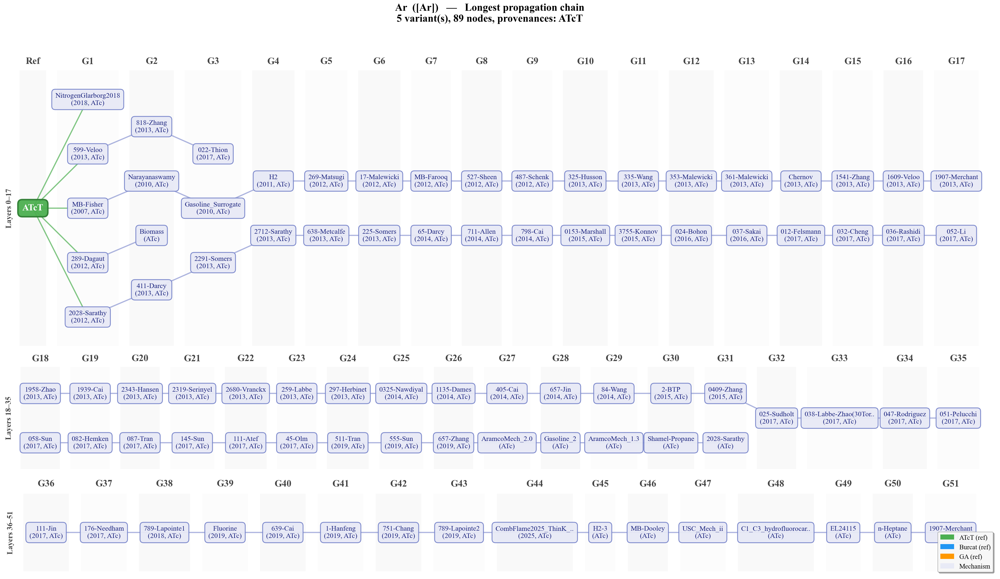


Ar ([Ar])  —  species_id=5669  [Longest propagation chain]
  5 polynomial variant(s):
  Variant 1: chain length 58
    Ref origin: ATcT
    Chain: ATcT → MB-Fisher → Narayanaswamy → Narayanaswamy → Gasoline_Surrogate → H2 → H2 → PCI2013/269-Matsugi → CombFlame2013/17-Malewicki → MB-Farooq → PCI2013/527-Sheen → CombFlame2013/487-Schenk → PCI2013/325-Husson → PCI2013/335-Wang → PCI2013/353-Malewicki → PCI2013/361-Malewicki → Chernov → CombFlame2013/1541-Zhang → CombFlame2013/1609-Veloo → CombFlame2013/1907-Merchant → CombFlame2013/1958-Zhao → CombFlame2013/1939-Cai → CombFlame2013/2343-Hansen → CombFlame2013/2319-Serinyel → CombFlame2013/2680-Vranckx → PCI2013/259-Labbe → PCI2013/297-Herbinet → PCI2015/0325-Nawdiyal → CombFlame2014/1135-Dames → CombFlame2014/405-Cai → CombFlame2014/657-Jin → CombFlame2014/84-Wang → 2-BTP → PCI2015/0409-Zhang → PCI2017/025-Sudholt → PCI2017/038-Labbe-Zhao(30Torr-10Atm) → PCI2017/047-Rodriguez → PCI2017/051-Pelucchi → PCI2017/111-Jin → CombFlame2017/176-N

/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:343: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.tight_layout(rect=[0.02, 0.0, 1.0, 0.96], h_pad=0.5)
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:345: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR,
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:345: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR,
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:348: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR,
/opt/anaconda3/envs/kms/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8943 (\N{MIDLI

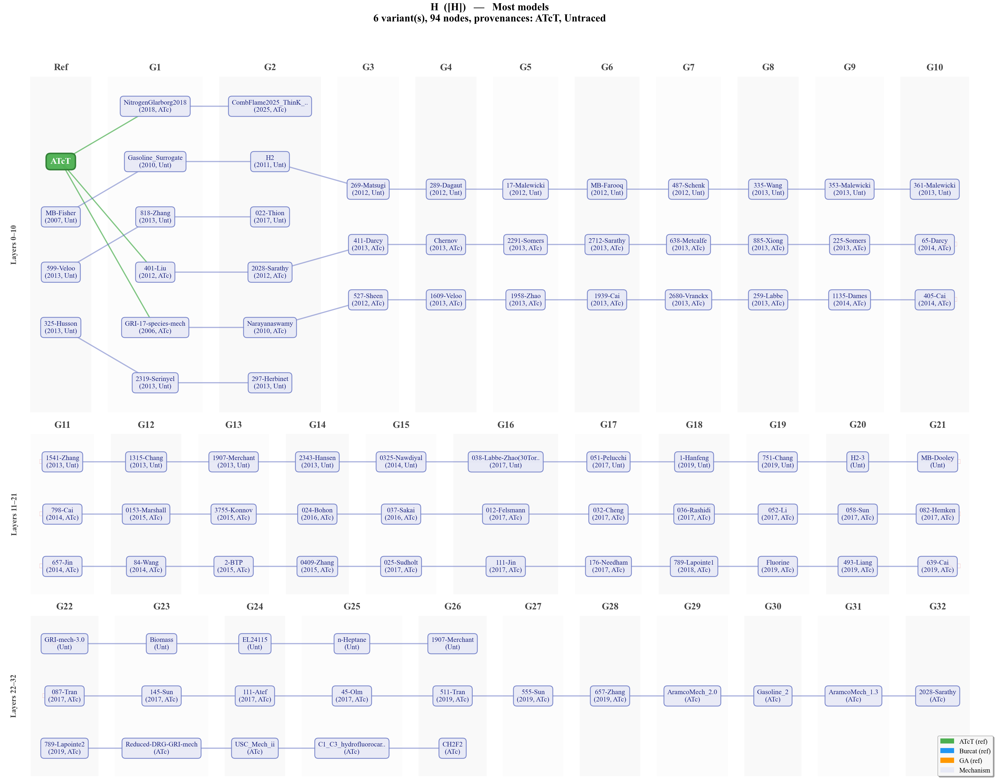


H ([H])  —  species_id=6  [Most models]
  6 polynomial variant(s):
  Variant 1: chain length 34
    Ref origin: ATcT
    Chain: ATcT → GRI-17-species-mech → GRI-17-species-mech → Narayanaswamy → Narayanaswamy → PCI2013/527-Sheen → CombFlame2013/1609-Veloo → CombFlame2013/1958-Zhao → CombFlame2013/1939-Cai → CombFlame2013/2680-Vranckx → PCI2013/259-Labbe → CombFlame2014/1135-Dames → CombFlame2014/405-Cai → CombFlame2014/657-Jin → CombFlame2014/84-Wang → 2-BTP → PCI2015/0409-Zhang → PCI2017/025-Sudholt → PCI2017/111-Jin → CombFlame2017/176-Needham → PCI2019/789-Lapointe1 → Fluorine → Fluorine → PCI2019/493-Liang → PCI2019/639-Cai → PCI2019/789-Lapointe2 → Reduced-DRG-GRI-mech → Reduced-DRG-GRI-mech → USC_Mech_ii → USC_Mech_ii → C1_C3_hydrofluorocarbons_NIST → C1_C3_hydrofluorocarbons_NIST → CH2F2 → CH2F2
    Models (33): GRI-17-species-mech, GRI-17-species-mech, Narayanaswamy, Narayanaswamy, PCI2013/527-Sheen, CombFlame2013/1609-Veloo, CombFlame2013/1958-Zhao, CombFlame2013/1939-Cai, Co

/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:343: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.tight_layout(rect=[0.02, 0.0, 1.0, 0.96], h_pad=0.5)
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:345: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR,
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:345: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR,
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/328300923.py:348: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR,
/opt/anaconda3/envs/kms/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8943 (\N{MIDLI

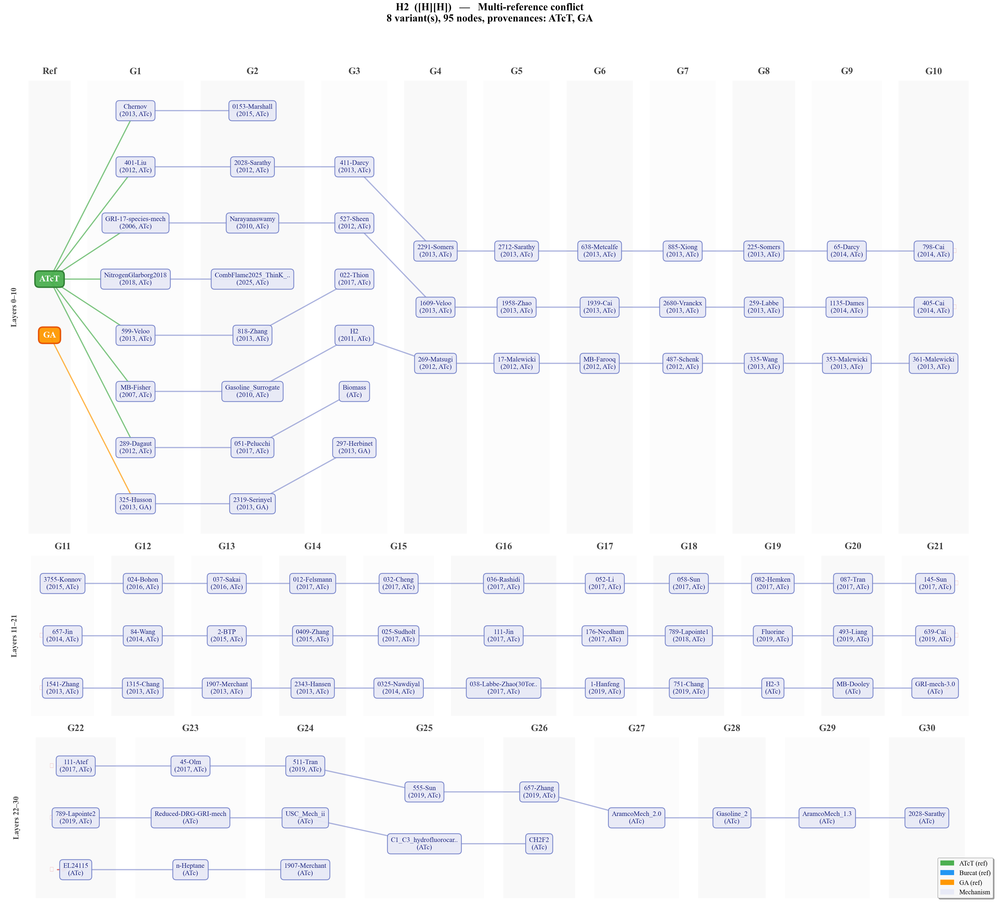


H2 ([H][H])  —  species_id=5  [Multi-reference conflict]
  8 polynomial variant(s):
  Variant 1: chain length 34
    Ref origin: ATcT
    Chain: ATcT → GRI-17-species-mech → GRI-17-species-mech → Narayanaswamy → Narayanaswamy → PCI2013/527-Sheen → CombFlame2013/1609-Veloo → CombFlame2013/1958-Zhao → CombFlame2013/1939-Cai → CombFlame2013/2680-Vranckx → PCI2013/259-Labbe → CombFlame2014/1135-Dames → CombFlame2014/405-Cai → CombFlame2014/657-Jin → CombFlame2014/84-Wang → 2-BTP → PCI2015/0409-Zhang → PCI2017/025-Sudholt → PCI2017/111-Jin → CombFlame2017/176-Needham → PCI2019/789-Lapointe1 → Fluorine → Fluorine → PCI2019/493-Liang → PCI2019/639-Cai → PCI2019/789-Lapointe2 → Reduced-DRG-GRI-mech → Reduced-DRG-GRI-mech → USC_Mech_ii → USC_Mech_ii → C1_C3_hydrofluorocarbons_NIST → C1_C3_hydrofluorocarbons_NIST → CH2F2 → CH2F2
    Models (33): GRI-17-species-mech, GRI-17-species-mech, Narayanaswamy, Narayanaswamy, PCI2013/527-Sheen, CombFlame2013/1609-Veloo, CombFlame2013/1958-Zhao, CombFlame

In [99]:
# ── Network diagrams for 3 representative species ──────────────────────
# Pick 3 species: (1) longest chain, (2) most models, (3) multi-ref or
# most variants.  Each gets its OWN figure.
# Layout: generations split across 3 horizontal rows for wide slides.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import matplotlib.gridspec as gridspec
import networkx as nx
import numpy as np
import os
from collections import defaultdict

ref_node_colors = {
    'ATcT':     '#4CAF50',
    'Burcat':   '#2196F3',
    'GA':       '#FF9800',
    'Untraced': '#9E9E9E',
}
REF_TEXT_CLR    = '#FFFFFF'
MECH_COLOR      = '#E8EAF6'
MECH_EDGE_CLR   = '#5C6BC0'
MECH_TEXT_CLR   = '#1A237E'
BAND_COLORS     = ['#F5F5F5', '#FAFAFA']
N_ROWS          = 3          # number of horizontal strips

# ── Select 3 species ───────────────────────────────────────────────────
pick_sids = []
pick_reasons = []

sid_longest = int(df_prop.iloc[0]['species_id'])
pick_sids.append(sid_longest)
pick_reasons.append('Longest propagation chain')

for _, row in df_prop.sort_values('n_models', ascending=False).iterrows():
    sid_most = int(row['species_id'])
    if sid_most not in pick_sids:
        pick_sids.append(sid_most)
        pick_reasons.append('Most models')
        break

found_third = False
if len(multi_ref):
    for _, row in multi_ref.sort_values('n_models', ascending=False).iterrows():
        sid_mr = int(row['species_id'])
        if sid_mr not in pick_sids:
            pick_sids.append(sid_mr)
            pick_reasons.append('Multi-reference conflict')
            found_third = True
            break
if not found_third:
    for _, row in df_prop.sort_values('n_variants', ascending=False).iterrows():
        sid_var = int(row['species_id'])
        if sid_var not in pick_sids:
            pick_sids.append(sid_var)
            pick_reasons.append('Most polynomial variants')
            break

for sid, reason in zip(pick_sids, pick_reasons):
    f = df_species.loc[sid, 'formula'] if sid in df_species.index else '?'
    s = df_species.loc[sid, 'smiles']  if sid in df_species.index else ''
    print(f'  [{reason}]  sid={sid}  {f} ({s})')

# ── Legend patches ─────────────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=ref_node_colors['ATcT'],   label='ATcT (ref)'),
    mpatches.Patch(color=ref_node_colors['Burcat'], label='Burcat (ref)'),
    mpatches.Patch(color=ref_node_colors['GA'],     label='GA (ref)'),
    mpatches.Patch(color=MECH_COLOR, edgecolor='#333', label='Mechanism'),
]

# ── Helpers ────────────────────────────────────────────────────────────
def _draw_box(ax, xy, label, fc, tc, fs, ec='#333', lw=1.5, bold=False):
    ax.text(xy[0], xy[1], label, ha='center', va='center',
            fontsize=fs, fontweight='bold' if bold else 'normal',
            color=tc, zorder=4,
            bbox=dict(boxstyle='round,pad=0.5', facecolor=fc,
                      edgecolor=ec, linewidth=lw, alpha=0.95))

def _draw_arrow(ax, src, dst, color, width, alpha, idx=0):
    rad_base = 0.15
    sign = 1 if idx % 2 == 0 else -1
    rad  = sign * rad_base * (1 + idx // 2)
    cs = 'arc3,rad=0.0' if idx == 0 else f'arc3,rad={rad:.2f}'
    ax.add_patch(FancyArrowPatch(
        posA=src, posB=dst, arrowstyle='-|>', mutation_scale=20,
        connectionstyle=cs, color=color, linewidth=width,
        alpha=alpha, zorder=2))

# ── One figure per species ─────────────────────────────────────────────
for plot_i, (sid, reason) in enumerate(zip(pick_sids, pick_reasons)):
    chains = propagation_chains[sid]
    formula = df_species.loc[sid, 'formula'] if sid in df_species.index else '?'
    smiles  = df_species.loc[sid, 'smiles']  if sid in df_species.index else ''

    _prov = df_mechanism.loc[
        df_mechanism['species_id'] == sid, ['model_name', 'provenance']
    ].drop_duplicates('model_name')
    prov_map = dict(zip(_prov['model_name'], _prov['provenance']))

    # Build digraph
    H = nx.DiGraph()
    for c in chains:
        ch = c['chain']
        for k in range(len(ch) - 1):
            if H.has_edge(ch[k], ch[k+1]):
                H[ch[k]][ch[k+1]]['variants'] += 1
            else:
                H.add_edge(ch[k], ch[k+1], variants=1)
        for nd in ch:
            if nd not in H:
                H.add_node(nd)

    n_total = H.number_of_nodes()

    # ── Assign layers (topological) ────────────────────────────────────
    try:
        topo = list(nx.topological_sort(H))
    except nx.NetworkXUnfeasible:
        topo = list(H.nodes())

    layer = {}
    for nd in topo:
        preds = list(H.predecessors(nd))
        layer[nd] = 0 if not preds else max(layer.get(p, 0) for p in preds) + 1

    layer_groups = defaultdict(list)
    for nd, lyr in layer.items():
        layer_groups[lyr].append(nd)

    n_layers = max(layer.values()) + 1 if layer else 1
    max_per_layer = max(len(v) for v in layer_groups.values()) if layer_groups else 1

    # ── Split layers into N_ROWS strips ────────────────────────────────
    layers_per_row = int(np.ceil(n_layers / N_ROWS))
    row_layer_ranges = []
    for r in range(N_ROWS):
        lo = r * layers_per_row
        hi = min((r + 1) * layers_per_row, n_layers)
        if lo < n_layers:
            row_layer_ranges.append((lo, hi))

    actual_rows = len(row_layer_ranges)

    # ── Estimate per-layer label widths for fit-content spacing ────────
    def _label_for(nd):
        if nd in ref_node_colors:
            return nd
        parts = nd.split('/')
        short = parts[-1] if len(parts) > 1 else nd
        if len(short) > 22:
            short = short[:20] + '..'
        yr = dated_models.get(nd)
        pc = prov_map.get(nd, '?')[:3]
        return f"{short}\n({yr}, {pc})" if yr else f"{short}\n({pc})"

    # Approximate width per layer (in data units) from longest label
    CHAR_W = 0.18   # approx data-units per character at typical font
    MIN_W  = 2.0    # minimum layer width
    GAP    = 0.8    # gap between adjacent layers

    layer_widths = {}  # lyr_abs → estimated width
    for lyr_abs in range(n_layers):
        nodes = layer_groups.get(lyr_abs, [])
        if not nodes:
            layer_widths[lyr_abs] = MIN_W
            continue
        max_chars = max(max(len(line) for line in _label_for(nd).split('\n'))
                        for nd in nodes)
        layer_widths[lyr_abs] = max(MIN_W, max_chars * CHAR_W + 1.0)

    # y_sp computed per-row based on actual node count in that row

    pos = {}  # node → (x, y)  in DATA coords for the row's axes
    node_row = {}  # node → which row it belongs to
    layer_x_center = {}  # lyr_abs → x center (for band drawing)

    for ri, (lo, hi) in enumerate(row_layer_ranges):
        # Find the max nodes in any layer of THIS row
        row_max_nodes = max((len(layer_groups.get(l, [])) for l in range(lo, hi)), default=1)
        # Per-row y_sp: tighter when fewer nodes, more room when many
        y_sp_row = max(1.6, min(3.0, 28.0 / max(row_max_nodes, 1)))

        # Accumulate x positions based on each layer's width
        x_cursor = 0.0
        for lyr_abs in range(lo, hi):
            w = layer_widths[lyr_abs]
            x_center = x_cursor + w / 2.0
            layer_x_center[lyr_abs] = x_center

            nodes = layer_groups.get(lyr_abs, [])
            n_in = len(nodes)
            for j, nd in enumerate(nodes):
                y = -(j - (n_in - 1) / 2.0) * y_sp_row
                pos[nd] = (x_center, y)
                node_row[nd] = ri

            x_cursor += w + GAP

    # ── Figure: one subplot row per strip ──────────────────────────────
    fig_w = max(16, min(30, sum(layer_widths.get(l, 2.0) for l in range(n_layers)) / actual_rows * 1.1 + 4))
    # Per-row height adapts to actual node count in each row
    row_heights = []
    for ri, (lo, hi) in enumerate(row_layer_ranges):
        row_max = max((len(layer_groups.get(l, [])) for l in range(lo, hi)), default=1)
        rh = max(3.0, row_max * 1.8)
        row_heights.append(rh)
    fig_h = sum(row_heights) + 1.5

    fig, axes = plt.subplots(actual_rows, 1, figsize=(fig_w, fig_h),
                             squeeze=False,
                             gridspec_kw={'height_ratios': row_heights})
    fig.patch.set_facecolor('white')

    font_sz = max(14, min(18, 22 - n_total * 0.08))

    # ── Render each row ───────────────────────────────────────────────
    for ri, (lo, hi) in enumerate(row_layer_ranges):
        ax = axes[ri, 0]
        ax.set_facecolor('white')

        # Nodes in this row
        row_nodes = [nd for nd, r in node_row.items() if r == ri]
        if not row_nodes:
            ax.axis('off')
            continue

        # Layer bands
        all_x = [pos[nd][0] for nd in row_nodes]
        all_y = [pos[nd][1] for nd in row_nodes]
        # Use per-layer widths for boundaries
        row_lyrs = [layer[nd] for nd in row_nodes]
        x_lo = min(all_x) - layer_widths.get(min(row_lyrs), 2.0) * 0.6
        x_hi = max(all_x) + layer_widths.get(max(row_lyrs), 2.0) * 0.6
        _row_ysp = max(1.6, min(3.0, 28.0 / max(len(row_nodes), 1)))
        y_lo, y_hi = min(all_y) - _row_ysp, max(all_y) + _row_ysp

        for lyr_abs in range(lo, hi):
            x_c = layer_x_center[lyr_abs]
            bw  = layer_widths[lyr_abs]
            bc  = BAND_COLORS[lyr_abs % 2]
            ax.add_patch(plt.Rectangle(
                (x_c - bw/2, y_lo), bw, y_hi - y_lo,
                facecolor=bc, edgecolor='none', zorder=0, alpha=0.5))
            lbl = 'Ref' if lyr_abs == 0 else f'G{lyr_abs}'
            ax.text(x_c, y_hi + 0.25, lbl, ha='center', va='bottom',
                    fontsize=20, color='#444', fontweight='bold')

        # Edges — only draw if BOTH endpoints are in this row
        # Cross-row edges: draw a dashed "continuation" arrow at row edges
        edge_idx = defaultdict(int)
        for u, v, d in H.edges(data=True):
            u_r = node_row.get(u)
            v_r = node_row.get(v)
            if u_r == ri and v_r == ri:
                # Normal edge within row
                e_clr = ref_node_colors.get(u, MECH_EDGE_CLR)
                e_alpha = 0.7 if u in ref_node_colors else 0.5
                n_var = d.get('variants', 1)
                e_w = min(4.5, 1.8 + 0.7 * n_var)
                idx = edge_idx[(u, v)]
                edge_idx[(u, v)] += 1
                _draw_arrow(ax, pos[u], pos[v], e_clr, e_w, e_alpha, idx)

        # Cross-row connectors: show as labeled text at the boundary
        # Incoming from previous row (u is in row ri-1, v is in row ri)
        incoming = set()
        outgoing = set()
        for u, v, d in H.edges(data=True):
            u_r = node_row.get(u)
            v_r = node_row.get(v)
            if u_r is not None and v_r == ri and u_r < ri:
                incoming.add(v)
            if v_r is not None and u_r == ri and v_r > ri:
                outgoing.add(u)

        # Draw small marker triangles for continuations
        for nd in incoming:
            px_, py_ = pos[nd]
            ax.annotate('', xy=(px_ - 0.3, py_),
                        xytext=(px_ - 0.8, py_),
                        arrowprops=dict(arrowstyle='-|>', color='#E57373',
                                        lw=2.5, mutation_scale=18))
            ax.text(px_ - 1.0, py_, '⋯', ha='center', va='center',
                    fontsize=14, color='#E57373', fontweight='bold')
        for nd in outgoing:
            px_, py_ = pos[nd]
            ax.annotate('', xy=(px_ + 0.8, py_),
                        xytext=(px_ + 0.3, py_),
                        arrowprops=dict(arrowstyle='-|>', color='#E57373',
                                        lw=2.5, mutation_scale=18))
            ax.text(px_ + 1.0, py_, '⋯', ha='center', va='center',
                    fontsize=14, color='#E57373', fontweight='bold')

        # Draw nodes
        for nd in row_nodes:
            if nd in ref_node_colors:
                _draw_box(ax, pos[nd], nd, ref_node_colors[nd],
                          REF_TEXT_CLR, font_sz + 4,
                          ec=('#2E7D32' if nd == 'ATcT'
                              else '#1565C0' if nd == 'Burcat'
                              else '#E65100'),
                          lw=3.0, bold=True)
            else:
                parts = nd.split('/')
                short = parts[-1] if len(parts) > 1 else nd
                if len(short) > 22:
                    short = short[:20] + '..'
                yr = dated_models.get(nd)
                pc = prov_map.get(nd, '?')[:3]
                lbl = f"{short}\n({yr}, {pc})" if yr else f"{short}\n({pc})"
                _draw_box(ax, pos[nd], lbl, MECH_COLOR, MECH_TEXT_CLR,
                          font_sz, ec='#7986CB', lw=1.8)

        # Row label on left
        row_label = f"Layers {lo}" if lo == hi - 1 else f"Layers {lo}–{hi-1}"
        ax.text(x_lo - 0.3, (y_lo + y_hi) / 2, row_label,
                ha='right', va='center', fontsize=16, color='#444',
                fontweight='bold', rotation=90)

        ax.set_xlim(x_lo - 1.0, x_hi + 1.0)
        ax.set_ylim(y_lo - 0.2, y_hi + 0.7)
        ax.set_aspect('auto')
        ax.axis('off')

    # ── Suptitle + legend ──────────────────────────────────────────────
    prov_set = sorted(set(prov_map.get(m, 'Untraced') for m in H.nodes()
                         if m not in ref_node_colors))
    title = f"{formula}"
    if smiles:
        title += f"  ({smiles})"
    title += f"   —   {reason}"
    title += f"\n{len(chains)} variant(s), {n_total} nodes, "
    title += f"provenances: {', '.join(prov_set)}"
    fig.suptitle(title, fontsize=22, fontweight='bold', y=0.99)

    # Place legend in last row
    axes[-1, 0].legend(handles=legend_patches, loc='lower right',
                       fontsize=14, framealpha=0.92, edgecolor='#999',
                       fancybox=True, shadow=True)

    plt.tight_layout(rect=[0.02, 0.0, 1.0, 0.96], h_pad=0.5)
    safe_formula = formula.replace('/', '_')
    plt.savefig(os.path.join(FIG_DIR,
                f'species_network_{plot_i+1}_{safe_formula}.pdf'),
                bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR,
                f'species_network_{plot_i+1}_{safe_formula}.png'),
                dpi=150, bbox_inches='tight')
    plt.show()

    # ── Print chain details ────────────────────────────────────────────
    print(f'\n{"="*70}')
    print(f'{formula} ({smiles})  —  species_id={sid}  [{reason}]')
    print(f'  {len(chains)} polynomial variant(s):')
    for vi, c in enumerate(sorted(chains, key=lambda x: -x["length"])):
        print(f'  Variant {vi+1}: chain length {c["length"]}')
        print(f'    Ref origin: {c["ref_origin"] or "None"}')
        print(f'    Chain: {" → ".join(c["chain"])}')
        print(f'    Models ({len(c["models"])}): {", ".join(c["models"])}')
        print(f'    Years: {", ".join(str(y) for y in c["years"])}')
    print()


CH4  sid=13  formula=CH4  smiles=C
  10 polynomial variant(s)
  93 nodes, 100 edges


/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/949317595.py:43: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Patch(color=_MECH_CLR, edgecolor='#333', label='Mechanism'),
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/949317595.py:232: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.tight_layout(rect=[0.02, 0.0, 1.0, 0.96], h_pad=0.5)
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/949317595.py:234: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR, f'species_network_CH4_{sf}.pdf'), bbox_inches='tight')
/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/949317595.py:234: UserWarning: Glyph 8943 (\N{MIDLINE HORIZONTAL ELLIPSIS}) missing from font(s) Times New Roman.
  plt.savefig(os.path.join(FIG_DIR, f'species_network_CH4_{sf}.p

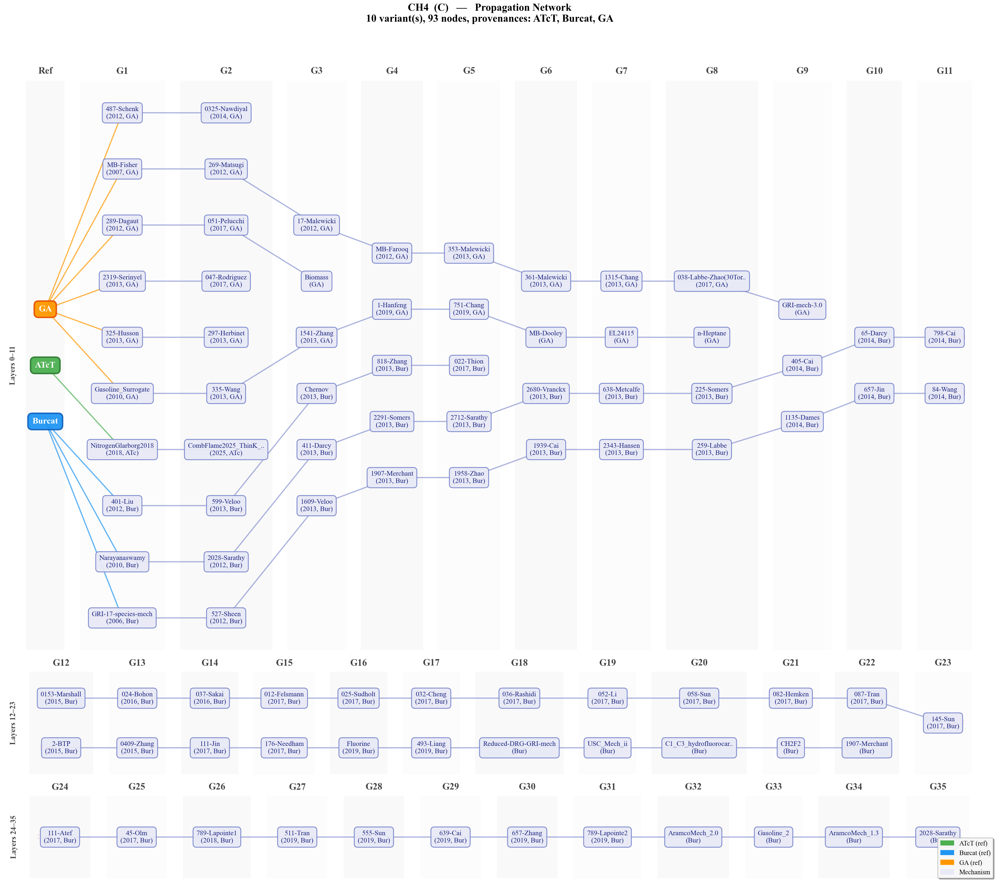


CH4 (C)  —  species_id=13
  10 polynomial variant(s):
  Variant 1: chain length 37
    Ref origin: Burcat
    Chain: Burcat → Narayanaswamy → Narayanaswamy → CombFlame2012/2028-Sarathy → PCI2013/411-Darcy → CombFlame2013/2291-Somers → CombFlame2013/2712-Sarathy → CombFlame2013/2680-Vranckx → IJCK2013/638-Metcalfe → PCI2013/225-Somers → CombFlame2014/405-Cai → CombFlame2014/65-Darcy → CombFlame2014/798-Cai → PCI2015/0153-Marshall → PCI2017/024-Bohon → PCI2017/037-Sakai → PCI2017/012-Felsmann → PCI2017/025-Sudholt → PCI2017/032-Cheng → PCI2017/036-Rashidi → PCI2017/052-Li → PCI2017/058-Sun → PCI2017/082-Hemken → PCI2017/087-Tran → PCI2017/145-Sun → CombFlame2017/111-Atef → CombFlame2017/45-Olm → PCI2019/789-Lapointe1 → PCI2019/511-Tran → PCI2019/555-Sun → PCI2019/639-Cai → PCI2019/657-Zhang → PCI2019/789-Lapointe2 → AramcoMech_2.0 → Gasoline_2 → AramcoMech_1.3 → butanol/2028-Sarathy
    Models (36): Narayanaswamy, Narayanaswamy, CombFlame2012/2028-Sarathy, PCI2013/411-Darcy, CombFlame20

In [100]:
# ── Network diagram for CH4 (methane) ──────────────────────────────────
# Uses the same 3-row horizontal strip layout as the representative
# species diagrams above.

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
import networkx as nx
import numpy as np
import os
from collections import defaultdict

# ── Find CH4 species_id ───────────────────────────────────────────────
ch4_mask = df_species['formula'] == 'CH4'
assert ch4_mask.any(), "CH4 not found in df_species"
ch4_sid = int(df_species[ch4_mask].index[0])
ch4_formula = df_species.loc[ch4_sid, 'formula']
ch4_smiles  = df_species.loc[ch4_sid, 'smiles'] if 'smiles' in df_species.columns else 'C'
print(f"CH4  sid={ch4_sid}  formula={ch4_formula}  smiles={ch4_smiles}")

assert ch4_sid in propagation_chains, f"sid {ch4_sid} not in propagation_chains"
chains = propagation_chains[ch4_sid]
print(f"  {len(chains)} polynomial variant(s)")

# ── Colours & helpers ─────────────────────────────────────────────────
_ref_clr = {
    'ATcT':     '#4CAF50',
    'Burcat':   '#2196F3',
    'GA':       '#FF9800',
    'Untraced': '#9E9E9E',
}
_REF_TXT   = '#FFFFFF'
_MECH_CLR  = '#E8EAF6'
_MECH_EDGE = '#5C6BC0'
_MECH_TXT  = '#1A237E'
_BANDS     = ['#F5F5F5', '#FAFAFA']
_NROWS     = 3

_legend = [
    mpatches.Patch(color=_ref_clr['ATcT'],   label='ATcT (ref)'),
    mpatches.Patch(color=_ref_clr['Burcat'], label='Burcat (ref)'),
    mpatches.Patch(color=_ref_clr['GA'],     label='GA (ref)'),
    mpatches.Patch(color=_MECH_CLR, edgecolor='#333', label='Mechanism'),
]

def _box(ax, xy, label, fc, tc, fs, ec='#333', lw=1.5, bold=False):
    ax.text(xy[0], xy[1], label, ha='center', va='center',
            fontsize=fs, fontweight='bold' if bold else 'normal',
            color=tc, zorder=4,
            bbox=dict(boxstyle='round,pad=0.5', facecolor=fc,
                      edgecolor=ec, linewidth=lw, alpha=0.95))

def _arrow(ax, src, dst, color, width, alpha, idx=0):
    rad_base = 0.15
    sign = 1 if idx % 2 == 0 else -1
    rad  = sign * rad_base * (1 + idx // 2)
    cs = 'arc3,rad=0.0' if idx == 0 else f'arc3,rad={rad:.2f}'
    ax.add_patch(FancyArrowPatch(
        posA=src, posB=dst, arrowstyle='-|>', mutation_scale=20,
        connectionstyle=cs, color=color, linewidth=width,
        alpha=alpha, zorder=2))

# Per-model provenance
_prov = df_mechanism.loc[
    df_mechanism['species_id'] == ch4_sid, ['model_name', 'provenance']
].drop_duplicates('model_name')
_prov_map = dict(zip(_prov['model_name'], _prov['provenance']))

def _lbl(nd):
    if nd in _ref_clr:
        return nd
    parts = nd.split('/')
    short = parts[-1] if len(parts) > 1 else nd
    if len(short) > 22:
        short = short[:20] + '..'
    yr = dated_models.get(nd)
    pc = _prov_map.get(nd, '?')[:3]
    return f"{short}\n({yr}, {pc})" if yr else f"{short}\n({pc})"

# ── Build digraph ─────────────────────────────────────────────────────
H_ch4 = nx.DiGraph()
for c in chains:
    ch = c['chain']
    for k in range(len(ch) - 1):
        if H_ch4.has_edge(ch[k], ch[k+1]):
            H_ch4[ch[k]][ch[k+1]]['variants'] += 1
        else:
            H_ch4.add_edge(ch[k], ch[k+1], variants=1)
    for nd in ch:
        if nd not in H_ch4:
            H_ch4.add_node(nd)

_ntotal = H_ch4.number_of_nodes()
print(f"  {_ntotal} nodes, {H_ch4.number_of_edges()} edges")

# ── Layers ────────────────────────────────────────────────────────────
try:
    _topo = list(nx.topological_sort(H_ch4))
except nx.NetworkXUnfeasible:
    _topo = list(H_ch4.nodes())

_layer = {}
for nd in _topo:
    pds = list(H_ch4.predecessors(nd))
    _layer[nd] = 0 if not pds else max(_layer.get(p, 0) for p in pds) + 1

_lg = defaultdict(list)
for nd, lyr in _layer.items():
    _lg[lyr].append(nd)

_nlayers = max(_layer.values()) + 1 if _layer else 1
_max_pl = max(len(v) for v in _lg.values()) if _lg else 1

# Per-layer widths (fit-content)
_CHAR_W = 0.18; _MIN_W = 2.0; _GAP = 0.8
_lw = {}
for la in range(_nlayers):
    nds = _lg.get(la, [])
    if not nds:
        _lw[la] = _MIN_W; continue
    mc = max(max(len(ln) for ln in _lbl(nd).split('\n')) for nd in nds)
    _lw[la] = max(_MIN_W, mc * _CHAR_W + 1.0)

# Split into rows
_lpr = int(np.ceil(_nlayers / _NROWS))
_rlr = []
for r in range(_NROWS):
    lo = r * _lpr; hi = min((r + 1) * _lpr, _nlayers)
    if lo < _nlayers:
        _rlr.append((lo, hi))
_ar = len(_rlr)

# Positions
_pos = {}; _nr = {}; _lxc = {}

for ri, (lo, hi) in enumerate(_rlr):
    rmn = max((len(_lg.get(l, [])) for l in range(lo, hi)), default=1)
    ysp = max(1.6, min(3.0, 28.0 / max(rmn, 1)))
    xc = 0.0
    for la in range(lo, hi):
        w = _lw[la]; xce = xc + w / 2.0; _lxc[la] = xce
        nds = _lg.get(la, []); ni = len(nds)
        for j, nd in enumerate(nds):
            _pos[nd] = (xce, -(j - (ni - 1) / 2.0) * ysp)
            _nr[nd] = ri
        xc += w + _GAP

# Figure
_fw = max(16, min(30, sum(_lw.get(l, 2.0) for l in range(_nlayers)) / _ar * 1.1 + 4))
_rh = []
for ri, (lo, hi) in enumerate(_rlr):
    rm = max((len(_lg.get(l, [])) for l in range(lo, hi)), default=1)
    _rh.append(max(3.0, rm * 1.8))
_fh = sum(_rh) + 1.5

fig, axes = plt.subplots(_ar, 1, figsize=(_fw, _fh), squeeze=False,
                         gridspec_kw={'height_ratios': _rh})
fig.patch.set_facecolor('white')
_fs = max(14, min(18, 22 - _ntotal * 0.08))

for ri, (lo, hi) in enumerate(_rlr):
    ax = axes[ri, 0]; ax.set_facecolor('white')
    rn = [nd for nd, r in _nr.items() if r == ri]
    if not rn: ax.axis('off'); continue

    ax_ = [_pos[nd][0] for nd in rn]
    ay_ = [_pos[nd][1] for nd in rn]
    rl = [_layer[nd] for nd in rn]
    _rysp = max(1.6, min(3.0, 28.0 / max(len(rn), 1)))
    xl = min(ax_) - _lw.get(min(rl), 2.0) * 0.6
    xh = max(ax_) + _lw.get(max(rl), 2.0) * 0.6
    yl, yh = min(ay_) - _rysp, max(ay_) + _rysp

    for la in range(lo, hi):
        xc_ = _lxc[la]; bw_ = _lw[la]
        ax.add_patch(plt.Rectangle((xc_ - bw_/2, yl), bw_, yh - yl,
            facecolor=_BANDS[la % 2], edgecolor='none', zorder=0, alpha=0.5))
        lb_ = 'Ref' if la == 0 else f'G{la}'
        ax.text(xc_, yh + 0.25, lb_, ha='center', va='bottom',
                fontsize=20, color='#444', fontweight='bold')

    eidx = defaultdict(int)
    for u, v, d in H_ch4.edges(data=True):
        ur, vr = _nr.get(u), _nr.get(v)
        if ur == ri and vr == ri:
            ec = _ref_clr.get(u, _MECH_EDGE)
            ea = 0.7 if u in _ref_clr else 0.5
            nv = d.get('variants', 1)
            ew = min(4.5, 1.8 + 0.7 * nv)
            ix = eidx[(u, v)]; eidx[(u, v)] += 1
            _arrow(ax, _pos[u], _pos[v], ec, ew, ea, ix)

    inc = set(); outg = set()
    for u, v, d in H_ch4.edges(data=True):
        ur, vr = _nr.get(u), _nr.get(v)
        if ur is not None and vr == ri and ur < ri: inc.add(v)
        if vr is not None and ur == ri and vr > ri: outg.add(u)
    for nd in inc:
        px_, py_ = _pos[nd]
        ax.annotate('', xy=(px_-0.3, py_), xytext=(px_-0.8, py_),
                    arrowprops=dict(arrowstyle='-|>', color='#E57373', lw=2.5, mutation_scale=18))
        ax.text(px_-1.0, py_, '⋯', ha='center', va='center',
                fontsize=14, color='#E57373', fontweight='bold')
    for nd in outg:
        px_, py_ = _pos[nd]
        ax.annotate('', xy=(px_+0.8, py_), xytext=(px_+0.3, py_),
                    arrowprops=dict(arrowstyle='-|>', color='#E57373', lw=2.5, mutation_scale=18))
        ax.text(px_+1.0, py_, '⋯', ha='center', va='center',
                fontsize=14, color='#E57373', fontweight='bold')

    for nd in rn:
        if nd in _ref_clr:
            _box(ax, _pos[nd], nd, _ref_clr[nd], _REF_TXT, _fs + 4,
                 ec='#2E7D32' if nd=='ATcT' else '#1565C0' if nd=='Burcat' else '#E65100',
                 lw=3.0, bold=True)
        else:
            _box(ax, _pos[nd], _lbl(nd), _MECH_CLR, _MECH_TXT, _fs, ec='#7986CB', lw=1.8)

    rl_ = f"Layers {lo}" if lo == hi - 1 else f"Layers {lo}–{hi-1}"
    ax.text(xl - 0.3, (yl + yh)/2, rl_, ha='right', va='center',
            fontsize=16, color='#444', fontweight='bold', rotation=90)
    ax.set_xlim(xl - 1.0, xh + 1.0)
    ax.set_ylim(yl - 0.2, yh + 0.7)
    ax.set_aspect('auto'); ax.axis('off')

pvs = sorted(set(_prov_map.get(m, 'Untraced') for m in H_ch4.nodes() if m not in _ref_clr))
ttl = f"CH4  ({ch4_smiles})   —   Propagation Network"
ttl += f"\n{len(chains)} variant(s), {_ntotal} nodes, provenances: {', '.join(pvs)}"
fig.suptitle(ttl, fontsize=22, fontweight='bold', y=0.99)
axes[-1, 0].legend(handles=_legend, loc='lower right', fontsize=14,
                   framealpha=0.92, edgecolor='#999', fancybox=True, shadow=True)
plt.tight_layout(rect=[0.02, 0.0, 1.0, 0.96], h_pad=0.5)
sf = ch4_formula.replace('/', '_')
plt.savefig(os.path.join(FIG_DIR, f'species_network_CH4_{sf}.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, f'species_network_CH4_{sf}.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'\n{"="*70}')
print(f'CH4 ({ch4_smiles})  —  species_id={ch4_sid}')
print(f'  {len(chains)} polynomial variant(s):')
for vi, c in enumerate(sorted(chains, key=lambda x: -x["length"])):
    print(f'  Variant {vi+1}: chain length {c["length"]}')
    print(f'    Ref origin: {c["ref_origin"] or "None"}')
    print(f'    Chain: {" → ".join(c["chain"])}')
    print(f'    Models ({len(c["models"])}): {", ".join(c["models"])}')
    print(f'    Years: {", ".join(str(y) for y in c["years"])}')
print()


Selected focal model: PCI2013/335-Wang
  Ancestor depth: 3, Descendant depth: 3, Span: 6 generations


/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/811605159.py:272: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(G_dir, pos, ax=ax, arrows=True,


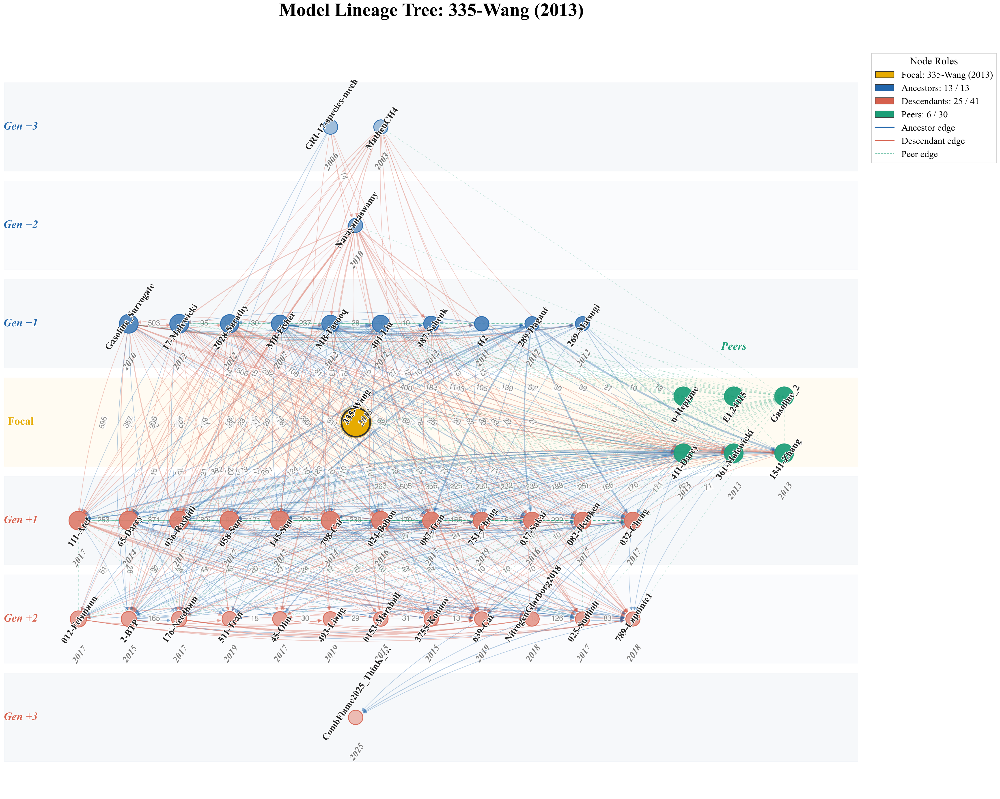


Lineage summary for: PCI2013/335-Wang (2013)
  Generational span: 3 ancestor + 3 descendant generations

  TOP 13 ANCESTORS (of 13 total):
    [Gen −1] Gasoline_Surrogate (2010) — 506 shared species
    [Gen −1] CombFlame2013/17-Malewicki (2012) — 282 shared species
    [Gen −1] CombFlame2012/2028-Sarathy (2012) — 106 shared species
    [Gen −1] MB-Fisher (2007) — 81 shared species
    [Gen −1] MB-Farooq (2012) — 79 shared species
    [Gen −1] PCI2013/401-Liu (2012) — 75 shared species
    [Gen −1] CombFlame2013/487-Schenk (2012) — 27 shared species
    [Gen −1] H2 (2011) — 10 shared species
    [Gen −1] PCI2013/289-Dagaut (2012) — 6 shared species
    [Gen −1] PCI2013/269-Matsugi (2012) — 6 shared species
    [Gen −2] Narayanaswamy (2010) — 4 shared species
    [Gen −3] GRI-17-species-mech (2006) — 14 shared species
    [Gen −3] MatheuCH4 (2003) — 4 shared species

  TOP 25 DESCENDANTS (of 41 total):
    [Gen +1] CombFlame2017/111-Atef (2017) — 382 shared species
    [Gen +1] CombFla

In [101]:
# ===== Figure 8: Model Lineage Tree (Improved) ==================================
# Selects the model with the deepest generational tree and renders a clean
# hierarchical layout with generation bands, horizontal labels, and
# depth-graded colouring.
# ================================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
import networkx as nx
import numpy as np

# ── Configuration ──────────────────────────────────────────────────────────────
MAX_DEPTH   = 4
TOP_ANC     = 20
TOP_DESC    = 12
TOP_PEERS   = 6

# ── Pick model with deepest generational span ────────────────────────────────
_mech_list = [n for n in G.nodes() if G.nodes[n].get('node_type') == 'mechanism']

def _bfs_max_depth(start, direction='up'):
    vis = {start}
    q = [(start, 0)]
    mx = 0
    while q:
        cur, dep = q.pop(0)
        mx = max(mx, dep)
        if direction == 'up':
            nbs = [u for u, _, d in G.in_edges(cur, data=True)
                   if d.get('edge_type') == 'mech_to_mech' and d.get('directed', False)]
        else:
            nbs = [v for _, v, d in G.out_edges(cur, data=True)
                   if d.get('edge_type') == 'mech_to_mech' and d.get('directed', False)]
        for nb in nbs:
            if nb not in vis:
                vis.add(nb)
                q.append((nb, dep + 1))
    return mx

_depth_scores = {}
for m in _mech_list:
    up = _bfs_max_depth(m, 'up')
    down = _bfs_max_depth(m, 'down')
    n_rel = len(ancestry_lookup.get(m, {}).get('_ancestors', [])) + \
            len(ancestry_lookup.get(m, {}).get('_descendants', []))
    _depth_scores[m] = (up + down, up, down, n_rel)

QUERY_MODEL = max(_depth_scores, key=lambda m: _depth_scores[m])
_up_d = _depth_scores[QUERY_MODEL][1]
_down_d = _depth_scores[QUERY_MODEL][2]
print(f"Selected focal model: {QUERY_MODEL}")
print(f"  Ancestor depth: {_up_d}, Descendant depth: {_down_d}, Span: {_up_d + _down_d} generations")

# ── BFS ancestors ─────────────────────────────────────────────────────────────
ancestors = {}
queue = [(QUERY_MODEL, 0)]
visited = {QUERY_MODEL}
while queue:
    current, depth = queue.pop(0)
    if depth >= MAX_DEPTH:
        continue
    for u, _, d in G.in_edges(current, data=True):
        if d.get('edge_type') == 'mech_to_mech' and d.get('directed', False):
            if u not in visited:
                ancestors[u] = (depth + 1, d.get('weight', 0))
                visited.add(u)
                queue.append((u, depth + 1))

# ── BFS descendants ──────────────────────────────────────────────────────────
descendants = {}
queue = [(QUERY_MODEL, 0)]
visited_d = {QUERY_MODEL}
while queue:
    current, depth = queue.pop(0)
    if depth >= MAX_DEPTH:
        continue
    for _, v, d in G.out_edges(current, data=True):
        if d.get('edge_type') == 'mech_to_mech' and d.get('directed', False):
            if v not in visited_d:
                descendants[v] = (depth + 1, d.get('weight', 0))
                visited_d.add(v)
                queue.append((v, depth + 1))

# ── Peers ────────────────────────────────────────────────────────────────────
peers = {}
for u, v, d in G.edges(data=True):
    if d.get('edge_type') == 'mech_to_mech' and not d.get('directed', False):
        if u == QUERY_MODEL and v not in ancestors and v not in descendants:
            peers[v] = d.get('weight', 0)
        elif v == QUERY_MODEL and u not in ancestors and u not in descendants:
            peers[u] = d.get('weight', 0)

# ── Filter to top-N per generation ──────────────────────────────────────────
anc_by_depth = {}
for m, (dep, w) in ancestors.items():
    anc_by_depth.setdefault(dep, []).append((m, w))
for dep in anc_by_depth:
    anc_by_depth[dep] = sorted(anc_by_depth[dep], key=lambda x: -x[1])[:TOP_ANC]

desc_by_depth = {}
for m, (dep, w) in descendants.items():
    desc_by_depth.setdefault(dep, []).append((m, w))
for dep in desc_by_depth:
    desc_by_depth[dep] = sorted(desc_by_depth[dep], key=lambda x: -x[1])[:TOP_DESC]

keep_peers = sorted(peers, key=lambda m: -peers[m])[:TOP_PEERS]
keep_anc   = [m for grp in anc_by_depth.values() for m, _ in grp]
keep_desc  = [m for grp in desc_by_depth.values() for m, _ in grp]

anc_d  = {m: ancestors[m]  for m in keep_anc}
desc_d = {m: descendants[m] for m in keep_desc}
peer_d = {m: peers[m]       for m in keep_peers}

# ── Build subgraph ──────────────────────────────────────────────────────────
all_nodes = {QUERY_MODEL} | set(keep_anc) | set(keep_desc) | set(keep_peers)
G_lineage = nx.DiGraph()
for m in all_nodes:
    G_lineage.add_node(m)
for u, v, d in G.edges(data=True):
    if d.get('edge_type') == 'mech_to_mech' and u in all_nodes and v in all_nodes:
        G_lineage.add_edge(u, v, weight=d.get('weight', 1),
                           directed=d.get('directed', False))

# ── Helpers ──────────────────────────────────────────────────────────────────
def _short(name, mc=22):
    parts = name.split('/')
    s = parts[-1] if len(parts) > 1 else name
    return (s[:mc] + '…') if len(s) > mc else s

def _year_str(name):
    yr = dated_models.get(name)
    return str(int(yr)) if yr else ''

def _depth_color(base_hex, depth, max_depth=MAX_DEPTH):
    from matplotlib.colors import to_rgb, to_hex
    r, g, b = to_rgb(base_hex)
    frac = 0.18 * min(depth, max_depth)
    return to_hex((r + frac*(1-r), g + frac*(1-g), b + frac*(1-b)))

# ── Hierarchical layout ────────────────────────────────────────────────────
pos = {}
x_spacing = 4.8
y_spacing = 3.8

pos[QUERY_MODEL] = (0, 0)

for dep in sorted(anc_by_depth.keys()):
    ms = [m for m, _ in anc_by_depth[dep]]
    n = len(ms)
    for i, m in enumerate(ms):
        pos[m] = ((i - (n-1)/2) * x_spacing, dep * y_spacing)

for dep in sorted(desc_by_depth.keys()):
    ms = [m for m, _ in desc_by_depth[dep]]
    n = len(ms)
    for i, m in enumerate(ms):
        pos[m] = ((i - (n-1)/2) * x_spacing, -dep * y_spacing)

if keep_peers:
    x_max_main = max((p[0] for m, p in pos.items() if m != QUERY_MODEL), default=0)
    x_off = max(x_max_main + x_spacing, x_spacing * 2)
    for i, m in enumerate(sorted(keep_peers, key=lambda m: -peer_d[m])):
        pos[m] = (x_off + (i % 3) * x_spacing, -(i // 3) * 2.2 + 1.0)

# ── Node styling ──────────────────────────────────────────────────────────
ROLE_CLR = PUB_ROLE
node_list = list(G_lineage.nodes())
role_map = {}
node_colors = []
edge_colors_n = []
sizes = []

for m in node_list:
    if m == QUERY_MODEL:
        role_map[m] = 'focal'
        node_colors.append(ROLE_CLR['focal'])
        edge_colors_n.append('#333')
        sizes.append(3200)
    elif m in anc_d:
        role_map[m] = 'ancestor'
        node_colors.append(_depth_color(ROLE_CLR['ancestor'], anc_d[m][0]))
        edge_colors_n.append(ROLE_CLR['ancestor'])
        sizes.append(900 + min(anc_d[m][1], 120) * 6)
    elif m in desc_d:
        role_map[m] = 'descendant'
        node_colors.append(_depth_color(ROLE_CLR['descendant'], desc_d[m][0]))
        edge_colors_n.append(ROLE_CLR['descendant'])
        sizes.append(900 + min(desc_d[m][1], 120) * 6)
    elif m in peer_d:
        role_map[m] = 'peer'
        node_colors.append(ROLE_CLR['peer'])
        edge_colors_n.append(ROLE_CLR['peer'])
        sizes.append(900 + min(peer_d[m], 120) * 6)
    else:
        role_map[m] = 'peer'
        node_colors.append('#CCC')
        edge_colors_n.append('#999')
        sizes.append(700)

# ── Figure ──────────────────────────────────────────────────────────────────
x_vals = [p[0] for p in pos.values()]
y_vals = [p[1] for p in pos.values()]
x_range = max(x_vals) - min(x_vals) + 10
y_range = max(y_vals) - min(y_vals) + 10

fig_w = min(max(18, x_range * 0.9), 30)
fig_h = min(max(14, y_range * 1.1), 24)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# ── Generation bands ────────────────────────────────────────────────────────
band_colors = ['#F7F9FC', '#EEF2F7']
gen_depths_anc = sorted(anc_by_depth.keys()) if anc_by_depth else []
gen_depths_desc = sorted(desc_by_depth.keys()) if desc_by_depth else []

# Focal band
ax.axhspan(-y_spacing*0.45, y_spacing*0.45, color='#FFF9E6', alpha=0.5, zorder=0)
x_label = min(x_vals) - 5.5

ax.text(x_label, 0, 'Focal', fontsize=24, fontweight='bold', ha='center', va='center',
        color=ROLE_CLR['focal'],
        path_effects=[pe.withStroke(linewidth=3, foreground='white')])

for dep in gen_depths_anc:
    yc = dep * y_spacing
    ax.axhspan(yc - y_spacing*0.45, yc + y_spacing*0.45,
               color=band_colors[dep % 2], alpha=0.5, zorder=0)
    ax.text(x_label, yc, f'Gen −{dep}', fontsize=24, fontweight='bold', ha='center', va='center',
            fontstyle='italic', color=ROLE_CLR['ancestor'],
            path_effects=[pe.withStroke(linewidth=2, foreground='white')])

for dep in gen_depths_desc:
    yc = -dep * y_spacing
    ax.axhspan(yc - y_spacing*0.45, yc + y_spacing*0.45,
               color=band_colors[dep % 2], alpha=0.5, zorder=0)
    ax.text(x_label, yc, f'Gen +{dep}', fontsize=24, fontweight='bold', ha='center', va='center',
            fontstyle='italic', color=ROLE_CLR['descendant'],
            path_effects=[pe.withStroke(linewidth=2, foreground='white')])

if keep_peers:
    peer_x = [pos[m][0] for m in keep_peers]
    peer_y = [pos[m][1] for m in keep_peers]
    ax.text(np.mean(peer_x), max(peer_y) + 1.8, 'Peers', fontsize=24, fontweight='bold',
            ha='center', fontstyle='italic', color=ROLE_CLR['peer'],
            path_effects=[pe.withStroke(linewidth=2, foreground='white')])

# ── Edges ───────────────────────────────────────────────────────────────────
dir_edges = [(u, v) for u, v, d in G_lineage.edges(data=True) if d.get('directed', False)]
undir_edges = [(u, v) for u, v, d in G_lineage.edges(data=True) if not d.get('directed', False)]

if dir_edges:
    ew = [G_lineage[u][v].get('weight', 1) for u, v in dir_edges]
    max_ew = max(ew) if ew else 1

    edge_cols = []
    edge_w = []
    for (u, v), w in zip(dir_edges, ew):
        w_norm = w / max(max_ew, 1)
        edge_w.append(1.0 + 5.0 * w_norm)
        if role_map.get(v) == 'focal' or role_map.get(u) == 'ancestor':
            edge_cols.append(ROLE_CLR['ancestor'])
        else:
            edge_cols.append(ROLE_CLR['descendant'])

    G_dir = nx.DiGraph()
    for e in dir_edges:
        G_dir.add_edge(*e)

    nx.draw_networkx_edges(G_dir, pos, ax=ax, arrows=True,
                           arrowstyle='-|>', arrowsize=16,
                           width=edge_w, edge_color=edge_cols,
                           alpha=0.35, connectionstyle='arc3,rad=0.08',
                           min_source_margin=18, min_target_margin=18)

    # Edge labels only for heavy edges (>= 10 shared species)
    edge_labels_d = {}
    for u, v in dir_edges:
        w = G_lineage[u][v].get('weight', 0)
        if w >= 10:
            edge_labels_d[(u, v)] = str(w)
    if edge_labels_d:
        nx.draw_networkx_edge_labels(G_dir, pos, edge_labels_d, ax=ax,
                                     font_size=16, font_color='#888', font_weight='bold',
                                     bbox=dict(facecolor='white', edgecolor='none',
                                               alpha=0.8, pad=0.3))

if undir_edges:
    G_u = nx.Graph()
    for u, v in undir_edges:
        G_u.add_edge(u, v)
    nx.draw_networkx_edges(G_u, pos, ax=ax, style=(0, (5, 5)),
                           width=1.0, edge_color=ROLE_CLR['peer'], alpha=0.25)

# ── Nodes ───────────────────────────────────────────────────────────────────
non_focal = [m for m in node_list if m != QUERY_MODEL]
nf_idx = [node_list.index(m) for m in non_focal]
nx.draw_networkx_nodes(G_lineage, pos, nodelist=non_focal, ax=ax,
                       node_color=[node_colors[i] for i in nf_idx],
                       node_size=[sizes[i] for i in nf_idx],
                       edgecolors=[edge_colors_n[i] for i in nf_idx],
                       linewidths=1.8, alpha=0.92)

# Focal: double-ring
nx.draw_networkx_nodes(G_lineage, pos, nodelist=[QUERY_MODEL], ax=ax,
                       node_color=ROLE_CLR['focal'], node_size=3800,
                       edgecolors='#333', linewidths=3.5, alpha=1.0)
nx.draw_networkx_nodes(G_lineage, pos, nodelist=[QUERY_MODEL], ax=ax,
                       node_color='none', node_size=4600,
                       edgecolors=ROLE_CLR['focal'], linewidths=2.0, alpha=0.45)

# ── Labels (horizontal, no rotation) ────────────────────────────────────────
for m in node_list:
    x, y = pos[m]
    name_lbl = _short(m, 20)
    yr_lbl = _year_str(m)

    if m == QUERY_MODEL:
        ax.text(x + 0.15, y - 0.15, name_lbl, fontsize=20, fontweight='bold', rotation=55,
                ha='center', va='bottom', color='#111',
                path_effects=[pe.withStroke(linewidth=3, foreground='white')])
        if yr_lbl:
            ax.text(x + 0.15, y - 0.15, yr_lbl, fontsize=20, fontweight='bold', rotation=55,
                    color='#555', fontstyle='italic',
                    path_effects=[pe.withStroke(linewidth=2, foreground='white')])
    else:
        sz = sizes[node_list.index(m)]
        r_off = np.sqrt(sz) / 75 + 0.55
        ax.text(x + 0.15, y - r_off, name_lbl, fontsize=20, fontweight='bold', rotation=55,
                ha='center', va='bottom', color='#222',
                path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])
        if yr_lbl:
            ax.text(x + 0.15, y - r_off, yr_lbl, fontsize=20, fontweight='bold', rotation=55,
                    ha='center', va='top', color='#777', fontstyle='italic',
                    path_effects=[pe.withStroke(linewidth=2, foreground='white')])

# ── Trim info ───────────────────────────────────────────────────────────────
trim_parts = []
if len(ancestors) > len(keep_anc):
    trim_parts.append(f'{len(ancestors)-len(keep_anc)} ancestors hidden')
if len(descendants) > len(keep_desc):
    trim_parts.append(f'{len(descendants)-len(keep_desc)} descendants hidden')
if len(peers) > len(keep_peers):
    trim_parts.append(f'{len(peers)-len(keep_peers)} peers hidden')
trim_str = f'  ({"; ".join(trim_parts)})' if trim_parts else ''

# ── Legend ──────────────────────────────────────────────────────────────────
focal_short = _short(QUERY_MODEL, 30)
yr_focal = dated_models.get(QUERY_MODEL)
yr_f_str = f" ({int(yr_focal)})" if yr_focal else ""

handles = [
    mpatches.Patch(facecolor=ROLE_CLR['focal'], edgecolor='#333', linewidth=1.5,
                   label=f'Focal: {focal_short}{yr_f_str}'),
    mpatches.Patch(facecolor=ROLE_CLR['ancestor'], edgecolor='#333',
                   label=f'Ancestors: {len(keep_anc)} / {len(ancestors)}'),
    mpatches.Patch(facecolor=ROLE_CLR['descendant'], edgecolor='#333',
                   label=f'Descendants: {len(keep_desc)} / {len(descendants)}'),
    mpatches.Patch(facecolor=ROLE_CLR['peer'], edgecolor='#333',
                   label=f'Peers: {len(keep_peers)} / {len(peers)}'),
    Line2D([], [], color=ROLE_CLR['ancestor'], lw=2.5, label='Ancestor edge'),
    Line2D([], [], color=ROLE_CLR['descendant'], lw=2.5, label='Descendant edge'),
    Line2D([], [], color=ROLE_CLR['peer'], lw=1.2, ls='--', label='Peer edge'),
]
ax.legend(handles=handles, fontsize=20, loc='upper left',
          bbox_to_anchor=(1.01, 1.0), title='Node Roles', title_fontsize=22,
          framealpha=0.95, edgecolor='#CCC', fancybox=False)

# ── Title ──────────────────────────────────────────────────────────────────
ax.set_title(
    f'Model Lineage Tree: {focal_short}{yr_f_str}\n',
    fontsize=40, pad=22, linespacing=1.5)
ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig8_model_lineage.pdf'))
plt.savefig(os.path.join(FIG_DIR, 'fig8_model_lineage.png'))
plt.show()

# ── Summary ────────────────────────────────────────────────────────────────
print(f"\nLineage summary for: {QUERY_MODEL}{yr_f_str}")
print(f"{'='*70}")
print(f"  Generational span: {_up_d} ancestor + {_down_d} descendant generations")
if keep_anc:
    print(f"\n  TOP {len(keep_anc)} ANCESTORS (of {len(ancestors)} total):")
    for m in keep_anc:
        depth, w = anc_d[m]
        yr = dated_models.get(m, '?')
        print(f"    [Gen −{depth}] {m} ({yr}) — {w} shared species")
if keep_desc:
    print(f"\n  TOP {len(keep_desc)} DESCENDANTS (of {len(descendants)} total):")
    for m in keep_desc:
        depth, w = desc_d[m]
        yr = dated_models.get(m, '?')
        print(f"    [Gen +{depth}] {m} ({yr}) — {w} shared species")
if keep_peers:
    print(f"\n  TOP {len(keep_peers)} PEERS (of {len(peers)} total):")
    for m in keep_peers:
        yr = dated_models.get(m, '?')
        print(f"    {m} ({yr}) — {peer_d[m]} shared species")


#### Figure 8b: Direct Lineage Chains

Shows **only the direct parent→child edges** in the lineage of the focal model. Each arrow represents a single directed inheritance link between two mechanisms, labelled with the number of shared thermochemical species. This highlights the actual "who inherited from whom" chain — ancestor→ancestor and descendant→descendant — rather than the full neighbourhood.


Focal model: PCI2013/335-Wang
Direct ancestor edges: 13
Direct descendant edges: 25
Total chain nodes: 39  (focal + 38 relatives)


/var/folders/s3/w8v7qhm16dn7t5xvxlk9n1bc0000gn/T/ipykernel_71708/3342657312.py:186: DeprecationWarning: `alltrue` is deprecated as of NumPy 1.25.0, and will be removed in NumPy 2.0. Please use `all` instead.
  nx.draw_networkx_edges(G_chain, pos_chain, ax=ax, edgelist=edge_list,


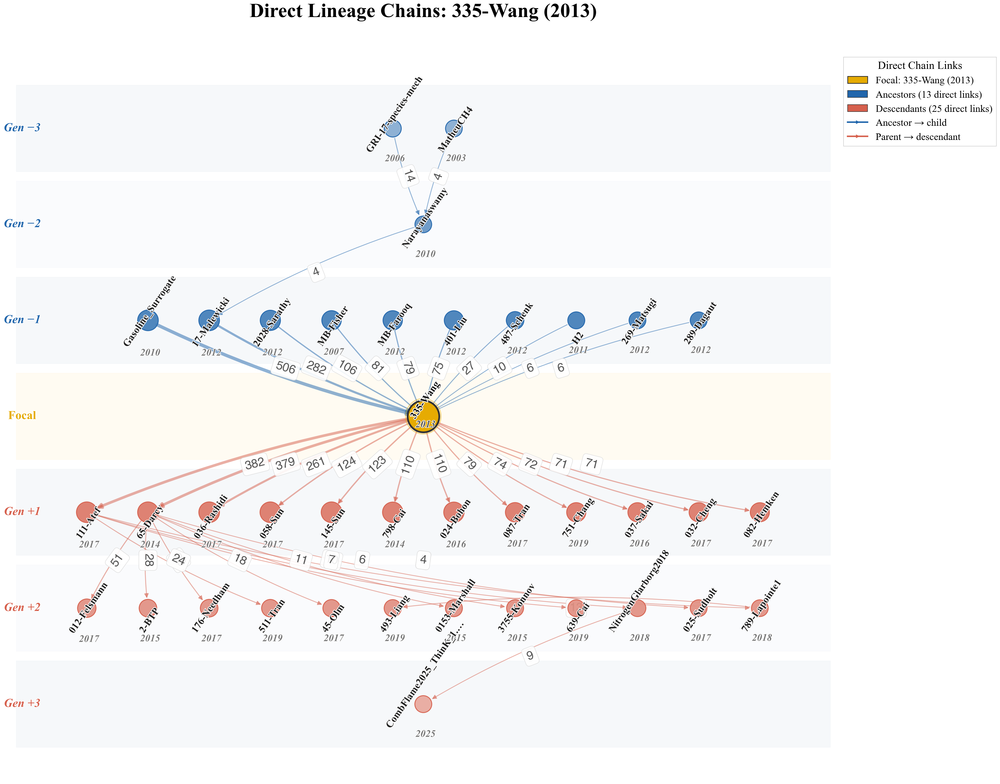


Direct lineage chains for: PCI2013/335-Wang (2013)

  ANCESTOR CHAIN EDGES (13 direct links):
    [Gen −3] GRI-17-species-mech (2006)  →  [Gen −2] Narayanaswamy (2010)  |  14 shared spp.
    [Gen −3] MatheuCH4 (2003)  →  [Gen −2] Narayanaswamy (2010)  |  4 shared spp.
    [Gen −2] Narayanaswamy (2010)  →  [Gen −1] 17-Malewicki (2012)  |  4 shared spp.
    [Gen −1] Gasoline_Surrogate (2010)  →  [Gen −0] 335-Wang (2013)  |  506 shared spp.
    [Gen −1] 17-Malewicki (2012)  →  [Gen −0] 335-Wang (2013)  |  282 shared spp.
    [Gen −1] 2028-Sarathy (2012)  →  [Gen −0] 335-Wang (2013)  |  106 shared spp.
    [Gen −1] MB-Fisher (2007)  →  [Gen −0] 335-Wang (2013)  |  81 shared spp.
    [Gen −1] MB-Farooq (2012)  →  [Gen −0] 335-Wang (2013)  |  79 shared spp.
    [Gen −1] 401-Liu (2012)  →  [Gen −0] 335-Wang (2013)  |  75 shared spp.
    [Gen −1] 487-Schenk (2012)  →  [Gen −0] 335-Wang (2013)  |  27 shared spp.
    [Gen −1] H2 (2011)  →  [Gen −0] 335-Wang (2013)  |  10 shared spp.
    [Gen −1

In [102]:
# ===== Figure 8b: Direct Lineage Chains =========================================
# Displays ONLY the direct parent→child edges in the ancestry of QUERY_MODEL.
# Each arrow = one directed inheritance link, labelled with shared-species count.
# Ancestor chains flow upward; descendant chains flow downward.
# Re-uses QUERY_MODEL, ancestors, descendants, anc_d, desc_d, anc_by_depth,
# desc_by_depth, G, dated_models, PUB_ROLE, FIG_DIR from the preceding cell.
# ================================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
import networkx as nx
import numpy as np
from collections import defaultdict

# ── 1. Build a subgraph that contains ONLY the direct BFS-tree edges ────────
# (the edges that were actually traversed during BFS in cell 85)

# Re-derive the BFS tree edges for ancestors
_anc_tree_edges = []   # list of (parent, child, weight) where parent→child is directed in G
_anc_parent = {}       # child → parent (BFS predecessor)
_queue = [(QUERY_MODEL, 0)]
_vis = {QUERY_MODEL}
while _queue:
    cur, dep = _queue.pop(0)
    if dep >= MAX_DEPTH:
        continue
    for u, _, d in G.in_edges(cur, data=True):
        if d.get('edge_type') == 'mech_to_mech' and d.get('directed', False):
            if u not in _vis and u in anc_d:
                w = d.get('weight', 0)
                _anc_tree_edges.append((u, cur, w))   # ancestor → child
                _anc_parent[cur] = u
                _vis.add(u)
                _queue.append((u, dep + 1))

# Re-derive the BFS tree edges for descendants
_desc_tree_edges = []
_desc_parent = {}
_queue = [(QUERY_MODEL, 0)]
_vis = {QUERY_MODEL}
while _queue:
    cur, dep = _queue.pop(0)
    if dep >= MAX_DEPTH:
        continue
    for _, v, d in G.out_edges(cur, data=True):
        if d.get('edge_type') == 'mech_to_mech' and d.get('directed', False):
            if v not in _vis and v in desc_d:
                w = d.get('weight', 0)
                _desc_tree_edges.append((cur, v, w))   # parent → descendant
                _desc_parent[v] = cur
                _vis.add(v)
                _queue.append((v, dep + 1))

all_chain_edges = _anc_tree_edges + _desc_tree_edges
chain_nodes = {QUERY_MODEL}
for u, v, w in all_chain_edges:
    chain_nodes.add(u)
    chain_nodes.add(v)

print(f"Focal model: {QUERY_MODEL}")
print(f"Direct ancestor edges: {len(_anc_tree_edges)}")
print(f"Direct descendant edges: {len(_desc_tree_edges)}")
print(f"Total chain nodes: {len(chain_nodes)}  (focal + {len(chain_nodes)-1} relatives)")

# ── 2. Build the chain DiGraph ──────────────────────────────────────────────
G_chain = nx.DiGraph()
for m in chain_nodes:
    G_chain.add_node(m)
for u, v, w in all_chain_edges:
    G_chain.add_edge(u, v, weight=w)

# ── 3. Group nodes by generation depth ──────────────────────────────────────
gen_map = {QUERY_MODEL: 0}
for m in chain_nodes:
    if m in anc_d:
        gen_map[m] = anc_d[m][0]       # positive = ancestor generation
    elif m in desc_d:
        gen_map[m] = -desc_d[m][0]     # negative = descendant generation

# Group by generation
gen_groups = defaultdict(list)
for m, g in gen_map.items():
    gen_groups[g].append(m)

# Sort within each generation by weight (heaviest edge to parent, for visual consistency)
for g in gen_groups:
    if g > 0:
        gen_groups[g] = sorted(gen_groups[g], key=lambda m: -anc_d.get(m, (0,0))[1])
    elif g < 0:
        gen_groups[g] = sorted(gen_groups[g], key=lambda m: -desc_d.get(m, (0,0))[1])

# ── 4. Hierarchical layout ─────────────────────────────────────────────────
pos_chain = {}
x_sp = 5.2
y_sp = 4.0

# Focal at origin
pos_chain[QUERY_MODEL] = (0, 0)

# Ancestors above (positive y), descendants below (negative y)
for g in sorted(gen_groups.keys()):
    ms = gen_groups[g]
    if g == 0:
        continue
    n = len(ms)
    for i, m in enumerate(ms):
        x = (i - (n - 1) / 2) * x_sp
        y = g * y_sp   # ancestors: g>0 → top; descendants: g<0 → bottom
        pos_chain[m] = (x, y)

# ── 5. Helpers ──────────────────────────────────────────────────────────────
def _short_c(name, mc=24):
    parts = name.split('/')
    s = parts[-1] if len(parts) > 1 else name
    return (s[:mc] + '…') if len(s) > mc else s

def _year_c(name):
    yr = dated_models.get(name)
    return str(int(yr)) if yr else ''

def _depth_clr(base_hex, depth, max_depth=MAX_DEPTH):
    from matplotlib.colors import to_rgb, to_hex
    r, g, b = to_rgb(base_hex)
    frac = 0.15 * min(depth, max_depth)
    return to_hex((r + frac*(1-r), g + frac*(1-g), b + frac*(1-b)))

# ── 6. Figure ───────────────────────────────────────────────────────────────
ROLE_CLR = PUB_ROLE

x_vals = [p[0] for p in pos_chain.values()]
y_vals = [p[1] for p in pos_chain.values()]
x_rng = max(x_vals) - min(x_vals) + 12
y_rng = max(y_vals) - min(y_vals) + 10

fig_w = min(max(16, x_rng * 0.85), 28)
fig_h = min(max(12, y_rng * 1.1), 22)

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# ── 7. Generation bands ────────────────────────────────────────────────────
band_light = ['#F7F9FC', '#EEF2F7']
x_label_pos = min(x_vals) - 5.5

# Focal band
ax.axhspan(-y_sp * 0.45, y_sp * 0.45, color='#FFF9E6', alpha=0.50, zorder=0)
ax.text(x_label_pos, 0, 'Focal', fontsize=24, fontweight='bold',
        ha='center', va='center', color=ROLE_CLR['focal'],
        path_effects=[pe.withStroke(linewidth=3, foreground='white')])

for g in sorted(gen_groups.keys()):
    if g == 0:
        continue
    yc = g * y_sp
    abs_g = abs(g)
    ax.axhspan(yc - y_sp * 0.45, yc + y_sp * 0.45,
               color=band_light[abs_g % 2], alpha=0.50, zorder=0)
    if g > 0:
        lbl = f'Gen −{abs_g}'
        clr = ROLE_CLR['ancestor']
    else:
        lbl = f'Gen +{abs_g}'
        clr = ROLE_CLR['descendant']
    ax.text(x_label_pos, yc, lbl, fontsize=24, fontweight='bold', ha='center', va='center',
            fontstyle='italic', color=clr,
            path_effects=[pe.withStroke(linewidth=2, foreground='white')])

# ── 8. Draw direct edges with weight labels ────────────────────────────────
edge_list = list(G_chain.edges())
weights = [G_chain[u][v].get('weight', 1) for u, v in edge_list]
max_w = max(weights) if weights else 1

edge_colors_chain = []
edge_widths = []
for (u, v), w in zip(edge_list, weights):
    w_norm = w / max(max_w, 1)
    edge_widths.append(1.5 + 5.0 * w_norm)
    # Ancestor-side edges (target gen >= 0 means going to focal or ancestor)
    if gen_map.get(v, 0) >= 0:
        edge_colors_chain.append(ROLE_CLR['ancestor'])
    else:
        edge_colors_chain.append(ROLE_CLR['descendant'])

nx.draw_networkx_edges(G_chain, pos_chain, ax=ax, edgelist=edge_list,
                       arrows=True, arrowstyle='-|>', arrowsize=18,
                       width=edge_widths, edge_color=edge_colors_chain,
                       alpha=0.50, connectionstyle='arc3,rad=0.06',
                       min_source_margin=20, min_target_margin=20)

# All direct edges get weight labels
edge_labels = {(u, v): str(G_chain[u][v].get('weight', ''))
               for u, v in edge_list}
nx.draw_networkx_edge_labels(G_chain, pos_chain, edge_labels, ax=ax,
                             font_size=24, font_color='#555', font_weight='bold',
                             bbox=dict(facecolor='white', edgecolor='#DDD',
                                       alpha=0.90, pad=1.5, boxstyle='round,pad=0.3'))

# ── 9. Draw nodes ──────────────────────────────────────────────────────────
node_list_c = list(G_chain.nodes())
node_colors_c = []
edge_colors_nc = []
sizes_c = []

for m in node_list_c:
    if m == QUERY_MODEL:
        node_colors_c.append(ROLE_CLR['focal'])
        edge_colors_nc.append('#333')
        sizes_c.append(3400)
    elif m in anc_d:
        dep = anc_d[m][0]
        node_colors_c.append(_depth_clr(ROLE_CLR['ancestor'], dep))
        edge_colors_nc.append(ROLE_CLR['ancestor'])
        sizes_c.append(1100 + min(anc_d[m][1], 120) * 5)
    elif m in desc_d:
        dep = desc_d[m][0]
        node_colors_c.append(_depth_clr(ROLE_CLR['descendant'], dep))
        edge_colors_nc.append(ROLE_CLR['descendant'])
        sizes_c.append(1100 + min(desc_d[m][1], 120) * 5)
    else:
        node_colors_c.append('#CCC')
        edge_colors_nc.append('#999')
        sizes_c.append(800)

non_focal = [m for m in node_list_c if m != QUERY_MODEL]
nf_idx = [node_list_c.index(m) for m in non_focal]
nx.draw_networkx_nodes(G_chain, pos_chain, nodelist=non_focal, ax=ax,
                       node_color=[node_colors_c[i] for i in nf_idx],
                       node_size=[sizes_c[i] for i in nf_idx],
                       edgecolors=[edge_colors_nc[i] for i in nf_idx],
                       linewidths=1.8, alpha=0.92)

# Focal: double ring
nx.draw_networkx_nodes(G_chain, pos_chain, nodelist=[QUERY_MODEL], ax=ax,
                       node_color=ROLE_CLR['focal'], node_size=4000,
                       edgecolors='#333', linewidths=3.5, alpha=1.0)
nx.draw_networkx_nodes(G_chain, pos_chain, nodelist=[QUERY_MODEL], ax=ax,
                       node_color='none', node_size=5000,
                       edgecolors=ROLE_CLR['focal'], linewidths=2.0, alpha=0.45)

# ── 10. Labels ──────────────────────────────────────────────────────────────
for m in node_list_c:
    x, y = pos_chain[m]
    name_lbl = _short_c(m, 22)
    yr_lbl = _year_c(m)

    if m == QUERY_MODEL:
        ax.text(x + 0.18, y - 0.18, name_lbl, fontsize=20, fontweight='bold', rotation=55,
                ha='center', va='bottom', color='#111',
                path_effects=[pe.withStroke(linewidth=3, foreground='white')])
        if yr_lbl:
            ax.text(x + 0.18, y - 0.18, yr_lbl, fontsize=20, fontweight='bold', ha='center', va='top',
                    color='#555', fontstyle='italic',
                    path_effects=[pe.withStroke(linewidth=2, foreground='white')])
    else:
        sz = sizes_c[node_list_c.index(m)]
        r_off = np.sqrt(sz) / 70 + 0.6
        ax.text(x + 0.18, y - r_off, name_lbl, fontsize=20, fontweight='bold', rotation=55,
                ha='center', va='bottom', color='#222',
                path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])
        if yr_lbl:
            ax.text(x + 0.18, y - r_off, yr_lbl, fontsize=20, fontweight='bold', ha='center', va='top',
                    color='#777', fontstyle='italic',
                    path_effects=[pe.withStroke(linewidth=2, foreground='white')])

# ── 11. Legend ──────────────────────────────────────────────────────────────
focal_short = _short_c(QUERY_MODEL, 30)
yr_focal = dated_models.get(QUERY_MODEL)
yr_f_str = f" ({int(yr_focal)})" if yr_focal else ""

handles = [
    mpatches.Patch(facecolor=ROLE_CLR['focal'], edgecolor='#333', linewidth=1.5,
                   label=f'Focal: {focal_short}{yr_f_str}'),
    mpatches.Patch(facecolor=ROLE_CLR['ancestor'], edgecolor='#333',
                   label=f'Ancestors ({len(_anc_tree_edges)} direct links)'),
    mpatches.Patch(facecolor=ROLE_CLR['descendant'], edgecolor='#333',
                   label=f'Descendants ({len(_desc_tree_edges)} direct links)'),
    Line2D([], [], color=ROLE_CLR['ancestor'], lw=3, marker='>', markersize=6,
           label='Ancestor → child'),
    Line2D([], [], color=ROLE_CLR['descendant'], lw=3, marker='>', markersize=6,
           label='Parent → descendant'),
]
ax.legend(handles=handles, fontsize=20, loc='upper left',
          bbox_to_anchor=(1.01, 1.0), title='Direct Chain Links', title_fontsize=22,
          framealpha=0.95, edgecolor='#CCC', fancybox=False)

# ── 12. Title ──────────────────────────────────────────────────────────────
ax.set_title(
    f'Direct Lineage Chains: {focal_short}{yr_f_str}\n',
    fontsize=40, pad=22, linespacing=1.5)

ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig8b_direct_lineage_chains.pdf'), bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'fig8b_direct_lineage_chains.png'), dpi=300, bbox_inches='tight')
plt.show()

# ── 13. Print the chains ──────────────────────────────────────────────────
print(f"\n{'='*70}")
print(f"Direct lineage chains for: {QUERY_MODEL}{yr_f_str}")
print(f"{'='*70}")

print(f"\n  ANCESTOR CHAIN EDGES ({len(_anc_tree_edges)} direct links):")
for u, v, w in sorted(_anc_tree_edges, key=lambda x: (-anc_d.get(x[0], (0,0))[0], -x[2])):
    u_yr = _year_c(u) or '?'
    v_yr = _year_c(v) or '?'
    u_gen = anc_d.get(u, (0,0))[0]
    v_gen = anc_d.get(v, (0,0))[0] if v != QUERY_MODEL else 0
    print(f"    [Gen −{u_gen}] {_short_c(u, 28)} ({u_yr})  →  "
          f"[Gen −{v_gen}] {_short_c(v, 28)} ({v_yr})  |  {w} shared spp.")

print(f"\n  DESCENDANT CHAIN EDGES ({len(_desc_tree_edges)} direct links):")
for u, v, w in sorted(_desc_tree_edges, key=lambda x: (desc_d.get(x[1], (0,0))[0], -x[2])):
    u_yr = _year_c(u) or '?'
    v_yr = _year_c(v) or '?'
    u_gen = desc_d.get(u, (0,0))[0] if u != QUERY_MODEL else 0
    v_gen = desc_d.get(v, (0,0))[0]
    print(f"    [Gen +{u_gen}] {_short_c(u, 28)} ({u_yr})  →  "
          f"[Gen +{v_gen}] {_short_c(v, 28)} ({v_yr})  |  {w} shared spp.")


### Step 5: Technical debt — deviation from ATcT

### 2.4 Technical Debt Quantification

For each (mechanism, species) pair where the provenance is an outdated source and ATcT provides an updated value, we quantify the **enthalpy debt** — the gap between current mechanism data and the best available reference.

#### Enthalpy Debt

$$\Delta H_{\text{debt}}(m, s) = |\Delta_f H^\circ_{\text{mechanism}}(m,s) - \Delta_f H^\circ_{\text{ATcT}}(s)|$$

#### Future Work: Equilibrium Constant Debt

Through the thermodynamic identity $\Delta_r G^\circ = \Delta_r H^\circ - T\Delta_r S^\circ = -RT \ln K_{\text{eq}}$, enthalpy errors propagate into equilibrium constants. A full K-debt analysis requires both $\Delta_f H^\circ$ and $S^\circ$ from ATcT. Since the current ATcT API (v1.0) exposes only formation enthalpies and their uncertainties, K-debt quantification is deferred until entropy data becomes available through the API.

In [103]:
# ============================================================================
# Enthalpy Debt: (model, species) pair-level computation
# ============================================================================
import pandas as pd
import numpy as np

# ── Build the pair-level debt table ──────────────────────────────────
# Each row = one (mechanism, species) pair with ATcT comparison
has_atct = df_mechanism[df_mechanism['H_atct'].notna()].copy()
has_atct['H_debt_kJmol'] = (has_atct['H298_Jmol'] - has_atct['H_atct']).abs() / 1000
has_atct['H_debt_signed_kJmol'] = (has_atct['H298_Jmol'] - has_atct['H_atct']) / 1000

# Add publication year per model
has_atct['year'] = has_atct['model_name'].map(dated_models)

In [104]:
# ============================================================================
# (Model, Species) pair-level debt table + aggregated views
# ============================================================================
import pandas as pd
import numpy as np

# ── 1. Display top (model, species) pairs with largest enthalpy debt ────────
pair_cols = ['model_name', 'formula', 'smiles', 'H_debt_kJmol',
             'H_debt_signed_kJmol', 'year']
pair_df = has_atct[pair_cols].copy()
pair_df = pair_df.sort_values('H_debt_kJmol', ascending=False)

print(f'{"Model":>38s} {"Species":>10s} {"SMILES":>16s} {"ΔH(kJ)":>8s} {"Signed":>8s} {"Year":>5s}')
print('─' * 90)
for _, r in pair_df.head(50).iterrows():
    nm = r['model_name'][:38]
    fm = str(r['formula'])[:10]
    sm = str(r['smiles'])[:16] if r['smiles'] else ''
    yr = str(int(r['year'])) if pd.notna(r['year']) else '  ?'
    print(f"{nm:>38s} {fm:>10s} {sm:>16s} {r['H_debt_kJmol']:8.2f} {r['H_debt_signed_kJmol']:+8.2f} {yr:>5s}")


                                 Model    Species           SMILES   ΔH(kJ)   Signed  Year
──────────────────────────────────────────────────────────────────────────────────────────
                    PCI2013/289-Dagaut          C              [C]   716.87  -716.87  2012
                                  H2-3          O                O   680.33  +680.33     ?
             CombFlame2015/3755-Konnov          O                O   680.33  +680.33  2015
             CombFlame2015/3755-Konnov         HO             [OH]   392.98  +392.98  2015
                                  H2-3         HO             [OH]   392.98  +392.98     ?
                    PCI2017/082-Hemken         HO             [OH]   387.38  +387.38  2017
                  CombFlame2017/45-Olm         HO             [OH]   387.38  +387.38  2017
                     PCI2017/037-Sakai         HO             [OH]   387.38  +387.38  2016
                CombFlame2017/111-Atef         HO             [OH]   387.38  +387.38  2017

In [105]:
# ── 2. For a selected species, show ALL models and their debt ─────
# Pick species with highest max debt across all models
worst_sp = has_atct.groupby('species_id')['H_debt_kJmol'].max().idxmax()
worst_label = species_label(worst_sp)
print(f'\n═══ ALL MODELS FOR WORST SPECIES: {worst_label} ═══')
sp_pairs = has_atct[has_atct['species_id'] == worst_sp].sort_values('H_debt_kJmol', ascending=False)
print(f'{"Model":>45s} {"ΔH(kJ)":>8s} {"Signed":>8s} {"Year":>5s}')
print('─' * 70)
for _, r in sp_pairs.iterrows():
    nm = r['model_name'][:45]
    yr = str(int(r['year'])) if pd.notna(r['year']) else '  ?'
    print(f"{nm:>45s} {r['H_debt_kJmol']:8.2f} {r['H_debt_signed_kJmol']:+8.2f} {yr:>5s}")



═══ ALL MODELS FOR WORST SPECIES: C ([C]) ═══
                                        Model   ΔH(kJ)   Signed  Year
──────────────────────────────────────────────────────────────────────
                           PCI2013/289-Dagaut   716.87  -716.87  2012
                               Shamel-Propane     0.62    +0.62     ?
                               PCI2017/052-Li     0.20    -0.20  2017
                              PCI2019/555-Sun     0.20    -0.20  2019
                         PCI2017/012-Felsmann     0.20    -0.20  2017
                              PCI2017/145-Sun     0.20    -0.20  2017
                               AramcoMech_1.3     0.20    -0.20     ?
                    CombFlame2013/2291-Somers     0.20    -0.20  2013
                            PCI2017/024-Bohon     0.20    -0.20  2016
                   CombFlame2013/2712-Sarathy     0.20    -0.20  2013
                             PCI2017/087-Tran     0.20    -0.20  2017
                            PCI2017/037-Sa

In [106]:
# ── 3. For a selected model, show ALL species with debt ──────────
worst_mod = has_atct.groupby('model_name')['H_debt_kJmol'].mean().idxmax()
print(f'\n═══ ALL SPECIES WITH DEBT IN WORST MODEL: {worst_mod[:50]} ═══')
mod_pairs = has_atct[has_atct['model_name'] == worst_mod].sort_values('H_debt_kJmol', ascending=False)
print(f'{"Formula":>10s} {"SMILES":>18s} {"ΔH(kJ)":>8s} {"Signed":>8s}')
print('─' * 48)
for _, r in mod_pairs.head(25).iterrows():
    fm = str(r['formula'])[:10]
    sm = str(r['smiles'])[:18] if r['smiles'] else ''
    print(f"{fm:>10s} {sm:>18s} {r['H_debt_kJmol']:8.2f} {r['H_debt_signed_kJmol']:+8.2f}")
if len(mod_pairs) > 25:
    print(f'  ... and {len(mod_pairs) - 25} more species')


═══ ALL SPECIES WITH DEBT IN WORST MODEL: CombFlame2015/3755-Konnov ═══
   Formula             SMILES   ΔH(kJ)   Signed
────────────────────────────────────────────────
         O                  O   680.33  +680.33
        HO               [OH]   392.98  +392.98
        O2                O=O    94.42   +94.42
      H2O2                 OO     0.47    -0.47
         O                [O]     0.05    -0.05
       H2O                  O     0.02    -0.02
         H                [H]     0.00    -0.00
        N2                N#N     0.00    -0.00
        H2             [H][H]     0.00    -0.00
        Ar               [Ar]     0.00    +0.00
        He               [He]     0.00    +0.00


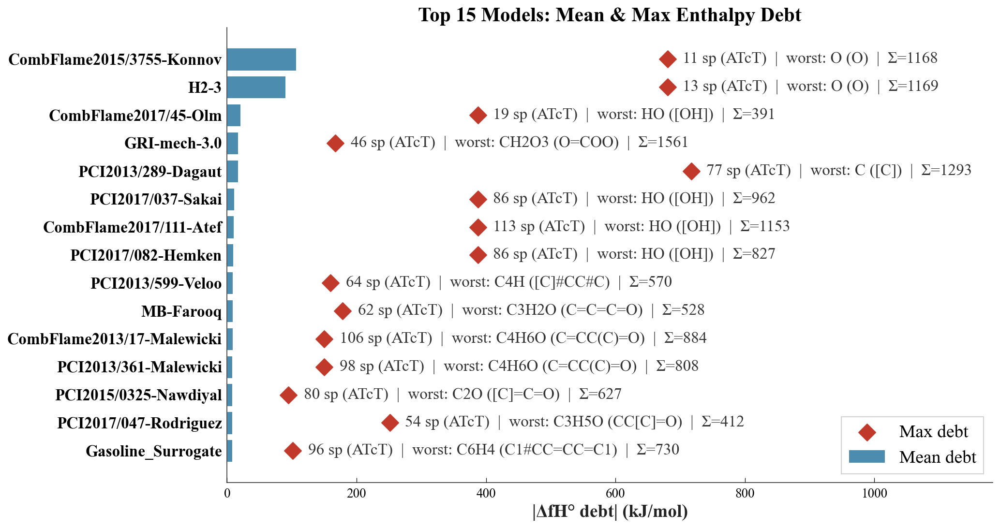

Chart saved: top 15 models (mean + max + total debt)


In [142]:
# ============================================================================
# Model-level debt aggregation + heatmap cross-tabulation
# ============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# ── 1. Model-level summary ────────────────────────────────────────
debt_by_model = has_atct.groupby('model_name').agg(
    mean_debt=('H_debt_kJmol', 'mean'),
    median_debt=('H_debt_kJmol', 'median'),
    total_debt=('H_debt_kJmol', 'sum'),
    max_debt=('H_debt_kJmol', 'max'),
    n_species=('species_id', 'nunique'),
).reset_index()
debt_by_model['year'] = debt_by_model['model_name'].map(dated_models)
debt_by_model = debt_by_model.sort_values('mean_debt', ascending=False)

# Find the worst species (highest debt) for each model
worst_species_per_model = has_atct.loc[
    has_atct.groupby('model_name')['H_debt_kJmol'].idxmax()
][['model_name', 'species_id', 'formula', 'H_debt_kJmol']].set_index('model_name')

# ── 2. Species-level summary ──────────────────────────────────────
debt_by_species = has_atct.groupby('species_id').agg(
    mean_debt=('H_debt_kJmol', 'mean'),
    max_debt=('H_debt_kJmol', 'max'),
    n_models=('model_name', 'nunique'),
).reset_index().sort_values('mean_debt', ascending=False)

# ── 3. Bar chart with clear annotations ──────────────────────────
N_TOP = min(15, len(debt_by_model))
top = debt_by_model.head(N_TOP).iloc[::-1]  # reverse for bottom-to-top

labels = [r['model_name'][:40] for _, r in top.iterrows()]
mean_vals = top['mean_debt'].values
max_vals = top['max_debt'].values

y_pos = np.arange(N_TOP)

fig, ax = plt.subplots(figsize=(14, max(6, N_TOP * 0.5)))

# Mean debt bars
ax.barh(y_pos, mean_vals, height=0.8, color='#4c8caf',
        edgecolor='white', linewidth=0.5, label='Mean debt', zorder=2)

# Max debt markers (diamond)
ax.scatter(max_vals, y_pos, marker='D', s=140, color='#c0392b',
           zorder=3, label='Max debt')

# Add extra space on the right for annotations
x_lim = max(max_vals) * 1.65
ax.set_xlim(0, x_lim)

# Annotations — placed after the max marker, clearly separated
for i, (_, r) in enumerate(top.iterrows()):
    mn = r['model_name']
    # Build annotation string: n_sp | worst species | Σ total
    parts = []
    parts.append(f"{r['n_species']:.0f} sp (ATcT)")
    if mn in worst_species_per_model.index:
        ws = worst_species_per_model.loc[mn]
        lbl = species_label(ws['species_id']) if callable(species_label) else str(ws['formula'])
        parts.append(f"worst: {lbl}")
    parts.append(f"Σ={r['total_debt']:.0f}")
    txt = '  |  '.join(parts)
    ax.text(r['max_debt'] + x_lim * 0.02, i, txt,
            va='center', fontsize=16, color='#333')

ax.set_yticks(y_pos)
ax.set_yticklabels(labels, fontsize=16, fontweight='bold')
ax.set_xlabel('|ΔfH° debt| (kJ/mol)', fontsize=18, fontweight='bold')
ax.set_title('Top 15 Models: Mean & Max Enthalpy Debt', fontsize=20, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='lower right', fontsize=18, framealpha=0.9)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_model_debt_ranking.pdf'), dpi=150, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'fig_model_debt_ranking.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'Chart saved: top {N_TOP} models (mean + max + total debt)')


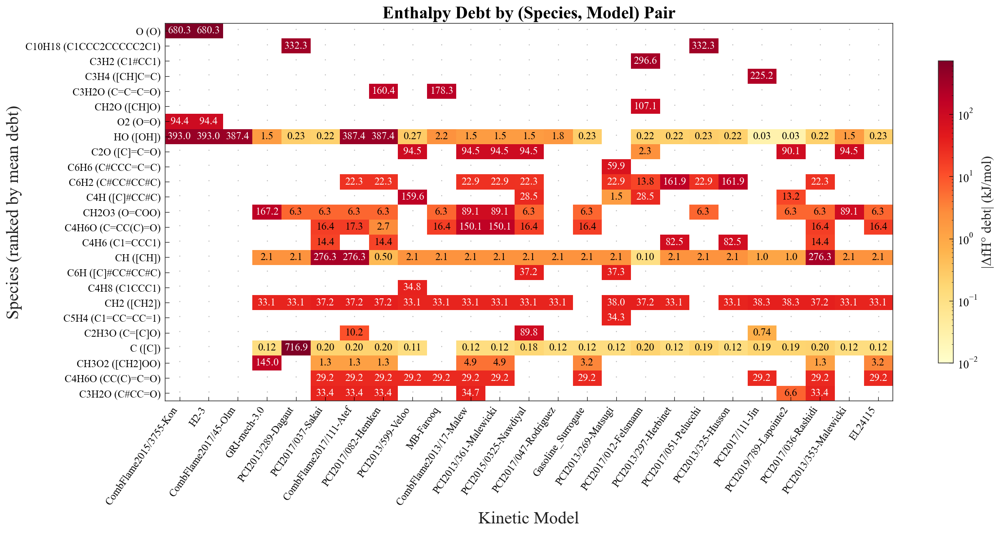

Heatmap saved (25 species × 25 models)


In [113]:
# ============================================================================
# (Species × Model) enthalpy debt heatmap
# ============================================================================
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import os

# Select top models first, then pick species that actually appear in them
N_MOD = min(25, len(debt_by_model))
top_mod_names = debt_by_model.head(N_MOD)['model_name'].tolist()

# Restrict to species that appear in at least one of the top models
species_in_top_models = has_atct[has_atct['model_name'].isin(top_mod_names)]
debt_by_species_filtered = species_in_top_models.groupby('species_id').agg(
    mean_debt=('H_debt_kJmol', 'mean'),
).reset_index().sort_values('mean_debt', ascending=False)

N_SP = min(25, len(debt_by_species_filtered))
top_sp_ids = debt_by_species_filtered.head(N_SP)['species_id'].tolist()
top_sp_labels = [species_label(sid) for sid in top_sp_ids]

# Build the matrix
heat_data = has_atct[
    has_atct['species_id'].isin(top_sp_ids) &
    has_atct['model_name'].isin(top_mod_names)
].pivot_table(
    index='species_id', columns='model_name',
    values='H_debt_kJmol', aggfunc='first'
)

# Reorder axes to match our ranking
heat_data = heat_data.reindex(index=top_sp_ids, columns=top_mod_names)
heat_labels_y = top_sp_labels
heat_labels_x = [n[:22] for n in top_mod_names]

# Plot
fig, ax = plt.subplots(figsize=(max(12, N_MOD * 0.7), max(6, N_SP * 0.35)))
norm = mcolors.LogNorm(vmin=0.01, vmax=max(heat_data.max().max(), 100))
im = ax.imshow(heat_data.values.astype(float), aspect='auto',
               cmap='YlOrRd', norm=norm, interpolation='nearest')

# Axis labels
ax.set_xticks(range(len(heat_labels_x)))
ax.set_xticklabels(heat_labels_x, rotation=55, ha='right', fontsize=12)
ax.set_yticks(range(len(heat_labels_y)))
ax.set_yticklabels(heat_labels_y, fontsize=12)

# Annotate cells
for i in range(heat_data.shape[0]):
    for j in range(heat_data.shape[1]):
        val = heat_data.iloc[i, j]
        if np.isnan(val):
            ax.text(j, i, '·', ha='center', va='center', fontsize=12, color='#bbb')
        elif val < 1:
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=12, color='black')
        else:
            ax.text(j, i, f'{val:.1f}', ha='center', va='center', fontsize=12,
                    color='white' if val > 20 else 'black')

cbar = fig.colorbar(im, ax=ax, label='|ΔfH° debt| (kJ/mol)', shrink=0.8)
ax.set_title('Enthalpy Debt by (Species, Model) Pair', fontsize=20, fontweight='bold')
ax.set_xlabel('Kinetic Model', fontsize=20)
ax.set_ylabel('Species (ranked by mean debt)', fontsize=20)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig_debt_heatmap.pdf'), dpi=150, bbox_inches='tight')
plt.savefig(os.path.join(FIG_DIR, 'fig_debt_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f'Heatmap saved ({N_SP} species × {N_MOD} models)')
